# Paso 1: Instalar las librerías necesarias

In [1]:
%pip install pandas numpy matplotlib openpyxl

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path


# Paso 2: Carga EM-DAT y revisa su estructura

In [3]:
# Ruta de los datos originales
CARPETA = Path("../datos/originales")

# Cargar la tabla principal de EM-DAT
archivo_emdat = (
    CARPETA /
    "public_emdat_custom_request_2026-10-10_9a289a17-70af-4ed5-b374-4d7f81af0743.xlsx"
)

df = pd.read_excel(
    archivo_emdat,
    sheet_name="EM-DAT Data"
)

# Inspeccionar los datos
display(df.head())

print("Número de filas:", df.shape[0])
print("Número de columnas:", df.shape[1])

print("\nNombres de columnas:")
print(df.columns.tolist())

print("\nTipos de datos:")
df.info()


,DisNo.,Historic,Classification Key,Disaster Group,Disaster Subgroup,Disaster Type,Disaster Subtype,External IDs,Event Name,ISO,...,"Reconstruction Costs, Adjusted ('000 US$)",Insured Damage ('000 US$),"Insured Damage, Adjusted ('000 US$)",Total Damage ('000 US$),"Total Damage, Adjusted ('000 US$)",CPI,Admin Units,GADM Admin Units,Entry Date,Last Update
0,2025-0303-ECU,No,nat-geo-ear-gro,Natural,Geophysical,Earthquake,Ground movement,NaN,NaN,ECU,...,NaN,NaN,NaN,NaN,NaN,100.0,NaN,NaN,2025-04-28,2026-05-15
1,2026-0153-KEN,No,nat-hyd-flo-flo,Natural,Hydrological,Flood,Flood (General),NaN,NaN,KEN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2026-03-09,2026-05-15
2,2025-0750-AFG,No,nat-geo-ear-gro,Natural,Geophysical,Earthquake,Ground movement,GLIDE:EQ-2025-000153,NaN,AFG,...,NaN,NaN,NaN,180000.0,180000.0,100.0,NaN,NaN,2025-09-01,2026-05-15
3,2026-0305-AFG,No,nat-hyd-flo-flo,Natural,Hydrological,Flood,Flood (General),NaN,NaN,AFG,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2026-05-04,2026-05-11
4,2024-0962-AGO,No,nat-bio-epi-bac,Natural,Biological,Epidemic,Bacterial disease,GLIDE:EP-2025-000013,Cholera,AGO,...,NaN,NaN,NaN,NaN,NaN,100.0,NaN,NaN,2025-01-17,2026-05-15


Número de filas: 10907
Número de columnas: 47

Nombres de columnas:
['DisNo.', 'Historic', 'Classification Key', 'Disaster Group', 'Disaster Subgroup', 'Disaster Type', 'Disaster Subtype', 'External IDs', 'Event Name', 'ISO', 'Country', 'Subregion', 'Region', 'Location', 'Origin', 'Associated Types', 'OFDA/BHA Response', 'Appeal', 'Declaration', "AID Contribution ('000 US$)", 'Magnitude', 'Magnitude Scale', 'Latitude', 'Longitude', 'River Basin', 'Start Year', 'Start Month', 'Start Day', 'End Year', 'End Month', 'End Day', 'Total Deaths', 'No. Injured', 'No. Affected', 'No. Homeless', 'Total Affected', "Reconstruction Costs ('000 US$)", "Reconstruction Costs, Adjusted ('000 US$)", "Insured Damage ('000 US$)", "Insured Damage, Adjusted ('000 US$)", "Total Damage ('000 US$)", "Total Damage, Adjusted ('000 US$)", 'CPI', 'Admin Units', 'GADM Admin Units', 'Entry Date', 'Last Update']

Tipos de datos:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10907 entries, 0 to 10906
Data columns (

# Paso 3. Haz la primera auditoría de calidad

In [4]:

# 1. Porcentaje de valores faltantes
reporte_faltantes = pd.DataFrame({
    "Cantidad_faltante": df.isna().sum(),
    "Porcentaje_faltante": df.isna().mean() * 100
})

reporte_faltantes = reporte_faltantes.sort_values(
    "Porcentaje_faltante",
    ascending=False
)

display(reporte_faltantes)

# 2. Duplicados exactos
print("Filas duplicadas:",
      df.duplicated().sum())

# 3. Identificadores de eventos repetidos
print("Identificadores repetidos:",
      df["DisNo."].duplicated().sum())

# 4. Años cubiertos
print("Año inicial:",
      df["Start Year"].min())

print("Año final:",
      df["Start Year"].max())

# 5. Tipos de desastres
display(
    df["Disaster Type"]
    .value_counts(dropna=False)
)

# 6. Países registrados
print("Países distintos:",
      df["ISO"].nunique())

# 7. Estadísticas de variables numéricas
columnas_impacto = [
    "Total Deaths",
    "No. Injured",
    "No. Affected",
    "Total Affected",
    "Total Damage ('000 US$)",
    "Total Damage, Adjusted ('000 US$)"
]

display(
    df[columnas_impacto].describe().T
)


,Cantidad_faltante,Porcentaje_faltante
"Reconstruction Costs, Adjusted ('000 US$)",10875,99.706610
Reconstruction Costs ('000 US$),10874,99.697442
AID Contribution ('000 US$),10426,95.589988
"Insured Damage, Adjusted ('000 US$)",10187,93.398735
Insured Damage ('000 US$),10184,93.371229
No. Homeless,9635,88.337765
River Basin,9581,87.842670
Longitude,9043,82.910058
Latitude,9043,82.910058
Event Name,8192,75.107729


Filas duplicadas: 0
Identificadores repetidos: 0
Año inicial: 2000
Año final: 2026


Disaster Type
Flood                          4294
Storm                          2930
Epidemic                        895
Earthquake                      707
Extreme temperature             606
Mass movement (wet)             505
Drought                         426
Wildfire                        356
Volcanic activity               134
Infestation                      29
Mass movement (dry)              15
Glacial lake outburst flood       8
Impact                            1
Animal incident                   1
Name: count, dtype: int64

Países distintos: 220


,count,mean,std,min,25%,50%,75%,max
Total Deaths,7835.0,2.217731e+02,3.943335e+03,1.0,4.0,12.0,36.0,222570.0
No. Injured,3187.0,2.691254e+03,3.721067e+04,1.0,10.0,35.0,156.0,1800000.0
No. Affected,7229.0,6.713210e+05,6.780205e+06,1.0,1125.0,9600.0,80000.0,330000000.0
Total Affected,8830.0,5.553153e+05,6.141743e+06,1.0,606.0,5385.0,50215.0,330000000.0
Total Damage ('000 US$),3347.0,1.179078e+06,6.283916e+06,2.0,17000.0,102000.0,575500.0,210000000.0
"Total Damage, Adjusted ('000 US$)",3312.0,1.570627e+06,8.658607e+06,3.0,24357.0,154130.5,804833.0,300561348.0


# Paso 4. Genera tus primeras gráficas exploratorias

- Vamores Faltantes 

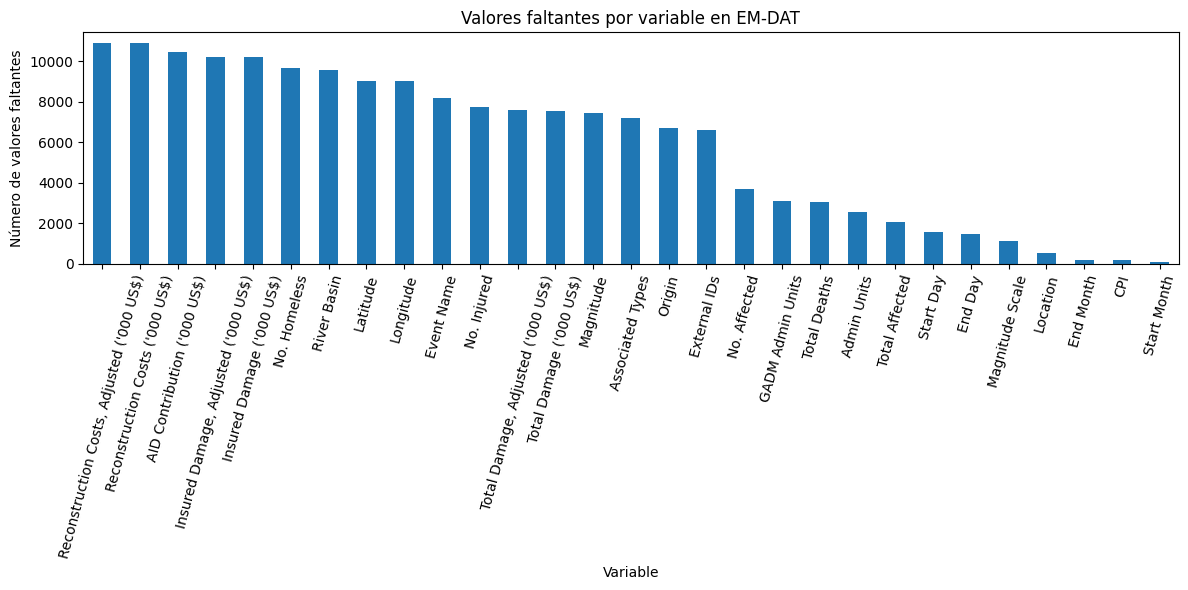

In [5]:
faltantes = df.isna().sum()
faltantes = faltantes[faltantes > 0].sort_values(
    ascending=False
)

plt.figure(figsize=(12, 6))
faltantes.plot(kind="bar")

plt.title("Valores faltantes por variable en EM-DAT")
plt.xlabel("Variable")
plt.ylabel("Número de valores faltantes")
plt.xticks(rotation=75)
plt.tight_layout()
plt.savefig(
    "../resultados/graficas/faltantes_emdat.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


- Desastres por tipo

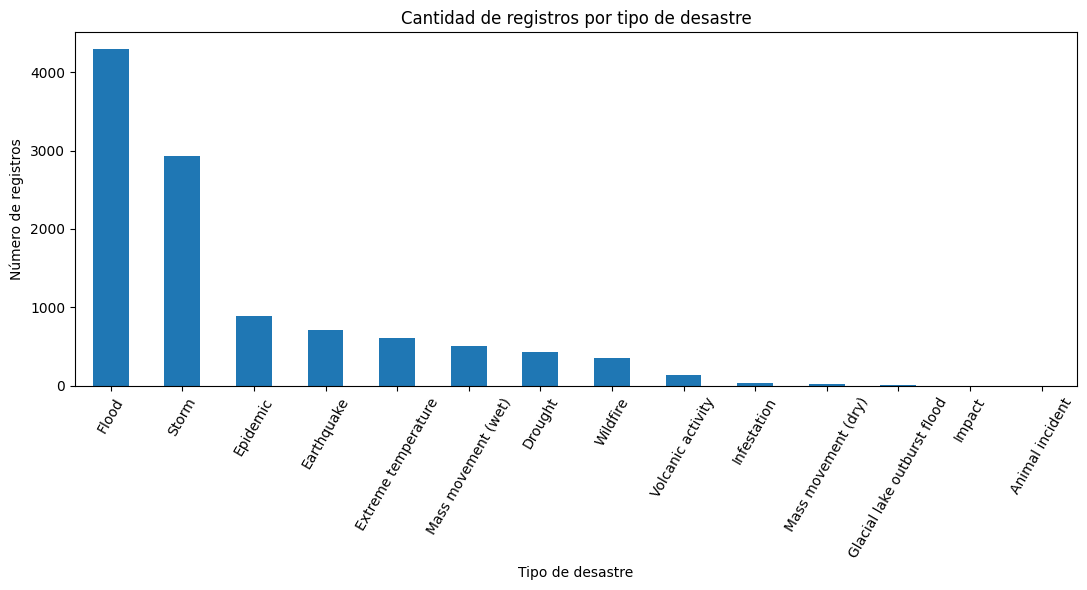

In [6]:

conteo_tipos = df["Disaster Type"].value_counts()

plt.figure(figsize=(11, 6))
conteo_tipos.plot(kind="bar")

plt.title("Cantidad de registros por tipo de desastre")
plt.xlabel("Tipo de desastre")
plt.ylabel("Número de registros")
plt.xticks(rotation=60)
plt.tight_layout()
plt.savefig(
    "../resultados/graficas/desastres_por_tipo.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


- Evolución anual de registros

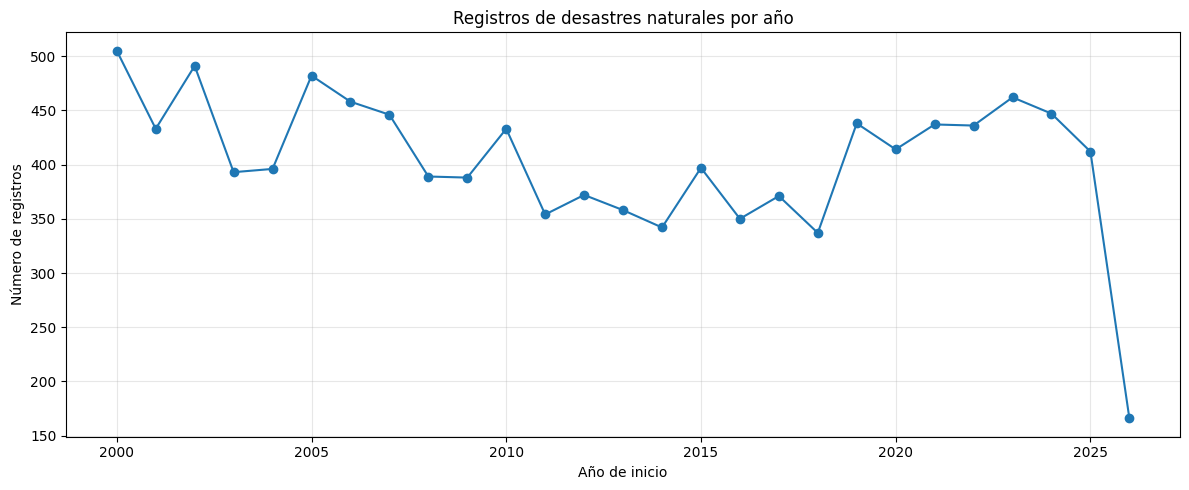

In [7]:

eventos_anuales = (
    df.groupby("Start Year")
    .size()
)

plt.figure(figsize=(12, 5))
eventos_anuales.plot(kind="line", marker="o")

plt.title("Registros de desastres naturales por año")
plt.xlabel("Año de inicio")
plt.ylabel("Número de registros")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(
    "../resultados/graficas/desastres_por_anio.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


- Guarda un registro reproducible de la auditoría

In [8]:

# Guardar la auditoría de valores faltantes
reporte_faltantes.to_csv(
    "../resultados/reporte_faltantes_emdat.csv",
    encoding="utf-8"
)

# Guardar un resumen de la estructura
resumen = pd.DataFrame({
    "Metrica": [
        "Filas originales",
        "Columnas originales",
        "Duplicados exactos",
        "Identificadores duplicados",
        "Año inicial",
        "Año final",
        "Países o territorios"
    ],
    "Valor": [
        len(df),
        len(df.columns),
        int(df.duplicated().sum()),
        int(df["DisNo."].duplicated().sum()),
        df["Start Year"].min(),
        df["Start Year"].max(),
        df["ISO"].nunique()
    ]
})

display(resumen)

resumen.to_csv(
    "../resultados/resumen_inicial_emdat.csv",
    index=False,
    encoding="utf-8"
)


,Metrica,Valor
0,Filas originales,10907
1,Columnas originales,47
2,Duplicados exactos,0
3,Identificadores duplicados,0
4,Año inicial,2000
5,Año final,2026
6,Países o territorios,220


- comprobaremos que Python puede leer el mapa

In [9]:
%pip install geopandas

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [10]:

import geopandas as gpd

ruta_mapa = (
    "../datos/geograficos/"
    "ne_110m_admin_0_countries/"
    "ne_110m_admin_0_countries.shp"
)

paises = gpd.read_file(ruta_mapa)

# Revisar los primeros países
display(paises.head())

# Revisar dimensiones
print("Filas y columnas:", paises.shape)

# Revisar los campos disponibles
print(paises.columns.tolist())

# Comprobar el sistema de coordenadas
print(paises.crs)


,featurecla,scalerank,LABELRANK,SOVEREIGNT,SOV_A3,ADM0_DIF,LEVEL,TYPE,TLC,ADMIN,...,FCLASS_TR,FCLASS_ID,FCLASS_PL,FCLASS_GR,FCLASS_IT,FCLASS_NL,FCLASS_SE,FCLASS_BD,FCLASS_UA,geometry
0,Admin-0 country,1,6,Fiji,FJI,0,2,Sovereign country,1,Fiji,...,None,None,None,None,None,None,None,None,None,"MULTIPOLYGON (((180 -16.06713, 180 -16.55522, ..."
1,Admin-0 country,1,3,United Republic of Tanzania,TZA,0,2,Sovereign country,1,United Republic of Tanzania,...,None,None,None,None,None,None,None,None,None,"POLYGON ((33.90371 -0.95, 34.07262 -1.05982, 3..."
2,Admin-0 country,1,7,Western Sahara,SAH,0,2,Indeterminate,1,Western Sahara,...,Unrecognized,Unrecognized,Unrecognized,None,None,Unrecognized,None,None,None,"POLYGON ((-8.66559 27.65643, -8.66512 27.58948..."
3,Admin-0 country,1,2,Canada,CAN,0,2,Sovereign country,1,Canada,...,None,None,None,None,None,None,None,None,None,"MULTIPOLYGON (((-122.84 49, -122.97421 49.0025..."
4,Admin-0 country,1,2,United States of America,US1,1,2,Country,1,United States of America,...,None,None,None,None,None,None,None,None,None,"MULTIPOLYGON (((-122.84 49, -120 49, -117.0312..."


Filas y columnas: (177, 169)
['featurecla', 'scalerank', 'LABELRANK', 'SOVEREIGNT', 'SOV_A3', 'ADM0_DIF', 'LEVEL', 'TYPE', 'TLC', 'ADMIN', 'ADM0_A3', 'GEOU_DIF', 'GEOUNIT', 'GU_A3', 'SU_DIF', 'SUBUNIT', 'SU_A3', 'BRK_DIFF', 'NAME', 'NAME_LONG', 'BRK_A3', 'BRK_NAME', 'BRK_GROUP', 'ABBREV', 'POSTAL', 'FORMAL_EN', 'FORMAL_FR', 'NAME_CIAWF', 'NOTE_ADM0', 'NOTE_BRK', 'NAME_SORT', 'NAME_ALT', 'MAPCOLOR7', 'MAPCOLOR8', 'MAPCOLOR9', 'MAPCOLOR13', 'POP_EST', 'POP_RANK', 'POP_YEAR', 'GDP_MD', 'GDP_YEAR', 'ECONOMY', 'INCOME_GRP', 'FIPS_10', 'ISO_A2', 'ISO_A2_EH', 'ISO_A3', 'ISO_A3_EH', 'ISO_N3', 'ISO_N3_EH', 'UN_A3', 'WB_A2', 'WB_A3', 'WOE_ID', 'WOE_ID_EH', 'WOE_NOTE', 'ADM0_ISO', 'ADM0_DIFF', 'ADM0_TLC', 'ADM0_A3_US', 'ADM0_A3_FR', 'ADM0_A3_RU', 'ADM0_A3_ES', 'ADM0_A3_CN', 'ADM0_A3_TW', 'ADM0_A3_IN', 'ADM0_A3_NP', 'ADM0_A3_PK', 'ADM0_A3_DE', 'ADM0_A3_GB', 'ADM0_A3_BR', 'ADM0_A3_IL', 'ADM0_A3_PS', 'ADM0_A3_SA', 'ADM0_A3_EG', 'ADM0_A3_MA', 'ADM0_A3_PT', 'ADM0_A3_AR', 'ADM0_A3_JP', 'ADM0_A3_KO', 'A

# Etapa 2: tratamiento de valores faltantes

# Paso 1: cargamos nuevamente el archivo y conservamos el original

In [11]:
import pandas as pd
import numpy as np
from pathlib import Path

In [12]:
# Ruta de los archivos originales
CARPETA = Path("../datos/originales")

archivo_emdat = (
    CARPETA /
    "public_emdat_custom_request_2026-10-10_9a289a17-70af-4ed5-b374-4d7f81af0743.xlsx"
)

# Cargar los datos originales
df_original = pd.read_excel(
    archivo_emdat,
    sheet_name="EM-DAT Data"
)

# Crear una copia para trabajar
df_trabajo = df_original.copy()

print("Filas originales:", len(df_original))
print("Filas de trabajo:", len(df_trabajo))
print("Columnas:", len(df_trabajo.columns))


Filas originales: 10907
Filas de trabajo: 10907
Columnas: 47


# Paso 2: generar un informe de valores faltantes

In [13]:

# Cantidad de valores faltantes por columna
cantidad_faltantes = df_trabajo.isna().sum()

# Porcentaje de valores faltantes por columna
porcentaje_faltantes = (
    df_trabajo.isna().mean() * 100
)

# Crear una tabla de auditoría
reporte_faltantes = pd.DataFrame({
    "Columna": df_trabajo.columns,
    "Tipo_dato": df_trabajo.dtypes.astype(str).values,
    "Cantidad_faltante": cantidad_faltantes.values,
    "Porcentaje_faltante": porcentaje_faltantes.values,
    "Valores_disponibles": (
        df_trabajo.notna().sum().values
    )
})

# Ordenar desde la columna con más faltantes
reporte_faltantes = reporte_faltantes.sort_values(
    by="Porcentaje_faltante",
    ascending=False
)

display(reporte_faltantes.round(2))


,Columna,Tipo_dato,Cantidad_faltante,Porcentaje_faltante,Valores_disponibles
37,"Reconstruction Costs, Adjusted ('000 US$)",float64,10875,99.71,32
36,Reconstruction Costs ('000 US$),float64,10874,99.70,33
19,AID Contribution ('000 US$),float64,10426,95.59,481
39,"Insured Damage, Adjusted ('000 US$)",float64,10187,93.40,720
38,Insured Damage ('000 US$),float64,10184,93.37,723
34,No. Homeless,float64,9635,88.34,1272
24,River Basin,object,9581,87.84,1326
23,Longitude,float64,9043,82.91,1864
22,Latitude,float64,9043,82.91,1864
8,Event Name,object,8192,75.11,2715


# Paso 3: identificar qué tipo de información está faltando

In [14]:

# Clasificación de columnas según su función
grupos_columnas = {
    "Identificacion del evento": [
        "DisNo.", "ISO", "Country",
        "Disaster Type", "Start Year"
    ],

    "Fechas parciales": [
        "Start Month", "Start Day",
        "End Year", "End Month", "End Day"
    ],

    "Ubicacion geografica": [
        "Latitude", "Longitude", "River Basin"
    ],

    "Impacto humano": [
        "Total Deaths", "No. Injured",
        "No. Affected", "No. Homeless",
        "Total Affected"
    ],

    "Impacto economico": [
        "Total Damage ('000 US$)",
        "Total Damage, Adjusted ('000 US$)"
    ]
}

# Mostrar el porcentaje de faltantes de cada grupo
for grupo, columnas in grupos_columnas.items():

    # Conservar solamente columnas existentes
    columnas_validas = [
        c for c in columnas
        if c in df_trabajo.columns
    ]

    if columnas_validas:
        print(f"\n--- {grupo} ---")

        display(
            reporte_faltantes[
                reporte_faltantes["Columna"].isin(
                    columnas_validas
                )
            ][
                [
                    "Columna",
                    "Cantidad_faltante",
                    "Porcentaje_faltante"
                ]
            ].round(2)
        )



--- Identificacion del evento ---


,Columna,Cantidad_faltante,Porcentaje_faltante
0,DisNo.,0,0.0
9,ISO,0,0.0
10,Country,0,0.0
5,Disaster Type,0,0.0
25,Start Year,0,0.0



--- Fechas parciales ---


,Columna,Cantidad_faltante,Porcentaje_faltante
27,Start Day,1564,14.34
30,End Day,1482,13.59
29,End Month,172,1.58
26,Start Month,73,0.67
28,End Year,0,0.00



--- Ubicacion geografica ---


,Columna,Cantidad_faltante,Porcentaje_faltante
24,River Basin,9581,87.84
23,Longitude,9043,82.91
22,Latitude,9043,82.91



--- Impacto humano ---


,Columna,Cantidad_faltante,Porcentaje_faltante
34,No. Homeless,9635,88.34
32,No. Injured,7720,70.78
33,No. Affected,3678,33.72
31,Total Deaths,3072,28.17
35,Total Affected,2077,19.04



--- Impacto economico ---


,Columna,Cantidad_faltante,Porcentaje_faltante
41,"Total Damage, Adjusted ('000 US$)",7595,69.63
40,Total Damage ('000 US$),7560,69.31


# Paso 4: medir los faltantes de las variables más importantes

In [15]:

# Variables de interés para el proyecto
variables_interes = [
    "Total Deaths",
    "No. Injured",
    "No. Affected",
    "No. Homeless",
    "Total Affected",
    "Total Damage ('000 US$)",
    "Total Damage, Adjusted ('000 US$)",
    "Latitude",
    "Longitude"
]

# Evitar errores si alguna columna no existe
variables_interes = [
    c for c in variables_interes
    if c in df_trabajo.columns
]

# Crear resumen de disponibilidad
resumen_impacto = pd.DataFrame({
    "Registros_totales": len(df_trabajo),
    "Datos_disponibles": df_trabajo[
        variables_interes
    ].notna().sum(),
    "Datos_faltantes": df_trabajo[
        variables_interes
    ].isna().sum(),
    "Porcentaje_disponible": (
        df_trabajo[variables_interes]
        .notna()
        .mean() * 100
    ),
    "Porcentaje_faltante": (
        df_trabajo[variables_interes]
        .isna()
        .mean() * 100
    )
})

display(resumen_impacto.round(2))


,Registros_totales,Datos_disponibles,Datos_faltantes,Porcentaje_disponible,Porcentaje_faltante
Total Deaths,10907,7835,3072,71.83,28.17
No. Injured,10907,3187,7720,29.22,70.78
No. Affected,10907,7229,3678,66.28,33.72
No. Homeless,10907,1272,9635,11.66,88.34
Total Affected,10907,8830,2077,80.96,19.04
Total Damage ('000 US$),10907,3347,7560,30.69,69.31
"Total Damage, Adjusted ('000 US$)",10907,3312,7595,30.37,69.63
Latitude,10907,1864,9043,17.09,82.91
Longitude,10907,1864,9043,17.09,82.91


# Paso 5: crear una copia con las decisiones documentadas

In [16]:

# Crear indicadores de calidad sin modificar los datos
df_trabajo["Falta_Total_Deaths"] = (
    df_trabajo["Total Deaths"].isna()
)

df_trabajo["Falta_Total_Affected"] = (
    df_trabajo["Total Affected"].isna()
)

df_trabajo["Falta_Danos_Economicos"] = (
    df_trabajo["Total Damage ('000 US$)"].isna()
)

df_trabajo["Falta_Coordenadas"] = (
    df_trabajo["Latitude"].isna()
    | df_trabajo["Longitude"].isna()
)

# Resumen de los indicadores
columnas_control = [
    "Falta_Total_Deaths",
    "Falta_Total_Affected",
    "Falta_Danos_Economicos",
    "Falta_Coordenadas"
]

display(
    df_trabajo[columnas_control]
    .sum()
    .to_frame("Registros_afectados")
)

# Guardar una copia de trabajo
salida = Path("../datos/procesados")
salida.mkdir(parents=True, exist_ok=True)

df_trabajo.to_csv(
    salida / "emdat_auditoria_faltantes.csv",
    index=False,
    encoding="utf-8"
)


,Registros_afectados
Falta_Total_Deaths,3072
Falta_Total_Affected,2077
Falta_Danos_Economicos,7560
Falta_Coordenadas,9043


# Paso 6: guardar el reporte de faltantes

In [17]:

reporte_faltantes.to_csv(
    salida / "reporte_faltantes_emdat.csv",
    index=False,
    encoding="utf-8"
)

resumen_impacto.to_csv(
    salida / "reporte_disponibilidad_impacto.csv",
    encoding="utf-8"
)

print("Archivos de auditoría guardados en:", salida)


Archivos de auditoría guardados en: ..\datos\procesados


# Copia de trabajo

In [18]:

# Crear un resumen de decisiones para el preprocesamiento

decisiones = {
    "Identificacion y clasificacion": [
        "DisNo.", "ISO", "Country",
        "Disaster Type", "Disaster Subtype",
        "Start Year", "End Year"
    ],
    "Impacto humano": [
        "Total Deaths", "No. Injured",
        "No. Affected", "No. Homeless",
        "Total Affected"
    ],
    "Impacto economico": [
        "Total Damage ('000 US$)",
        "Total Damage, Adjusted ('000 US$)"
    ],
    "Ubicacion": [
        "Latitude", "Longitude",
        "Location", "River Basin"
    ],
    "Campos secundarios": [
        "Reconstruction Costs ('000 US$)",
        "Reconstruction Costs, Adjusted ('000 US$)",
        "AID Contribution ('000 US$)",
        "Insured Damage ('000 US$)",
        "Insured Damage, Adjusted ('000 US$)"
    ]
}

# Crear tabla de decisiones con las columnas que existen
filas = []

for grupo, columnas in decisiones.items():
    for columna in columnas:
        if columna in df_trabajo.columns:
            filas.append({
                "Grupo": grupo,
                "Columna": columna,
                "Faltantes": int(
                    df_trabajo[columna].isna().sum()
                ),
                "Porcentaje_faltante": round(
                    df_trabajo[columna].isna().mean() * 100,
                    2
                )
            })

tabla_decisiones = pd.DataFrame(filas)

display(tabla_decisiones)

# Guardar para documentar el preprocesamiento
tabla_decisiones.to_csv(
    "../resultados/decisiones_faltantes.csv",
    index=False,
    encoding="utf-8"
)


,Grupo,Columna,Faltantes,Porcentaje_faltante
0,Identificacion y clasificacion,DisNo.,0,0.00
1,Identificacion y clasificacion,ISO,0,0.00
2,Identificacion y clasificacion,Country,0,0.00
3,Identificacion y clasificacion,Disaster Type,0,0.00
4,Identificacion y clasificacion,Disaster Subtype,0,0.00
5,Identificacion y clasificacion,Start Year,0,0.00
6,Identificacion y clasificacion,End Year,0,0.00
7,Impacto humano,Total Deaths,3072,28.17
8,Impacto humano,No. Injured,7720,70.78
9,Impacto humano,No. Affected,3678,33.72


# Etapa 3

# Paso 1. Comprobar los tipos de datos

In [19]:

# Revisar los tipos de datos de las columnas
tipos_datos = pd.DataFrame({
    "Columna": df_trabajo.columns,
    "Tipo_actual": df_trabajo.dtypes.astype(str).values,
    "Valores_disponibles": df_trabajo.notna().sum().values
})

display(tipos_datos)

# Revisar las columnas que deberían ser numéricas
columnas_numericas = [
    "Start Year", "Start Month", "Start Day",
    "End Year", "End Month", "End Day",
    "Latitude", "Longitude",
    "Total Deaths", "No. Injured",
    "No. Affected", "No. Homeless",
    "Total Affected",
    "Total Damage ('000 US$)",
    "Total Damage, Adjusted ('000 US$)"
]

for columna in columnas_numericas:
    if columna in df_trabajo.columns:
        print(
            columna,
            "->",
            df_trabajo[columna].dtype
        )


,Columna,Tipo_actual,Valores_disponibles
0,DisNo.,object,10907
1,Historic,object,10907
2,Classification Key,object,10907
3,Disaster Group,object,10907
4,Disaster Subgroup,object,10907
5,Disaster Type,object,10907
6,Disaster Subtype,object,10907
7,External IDs,object,4316
8,Event Name,object,2715
9,ISO,object,10907


Start Year -> int64
Start Month -> float64
Start Day -> float64
End Year -> int64
End Month -> float64
End Day -> float64
Latitude -> float64
Longitude -> float64
Total Deaths -> float64
No. Injured -> float64
No. Affected -> float64
No. Homeless -> float64
Total Affected -> float64
Total Damage ('000 US$) -> float64
Total Damage, Adjusted ('000 US$) -> float64


# Paso 2. Detectar valores numéricos que no se puedan interpretar

In [20]:

problemas_conversion = []

for columna in columnas_numericas:
    if columna in df_trabajo.columns:

        original = df_trabajo[columna]
        convertido = pd.to_numeric(
            original,
            errors="coerce"
        )

        # Valores originales presentes que fallaron
        # al convertirse a número
        mascara_error = (
            original.notna()
            & convertido.isna()
        )

        if mascara_error.any():
            problemas_conversion.append(
                df_trabajo.loc[
                    mascara_error,
                    ["DisNo.", "Country"]
                ].assign(
                    Columna=columna,
                    Valor_original=original[mascara_error]
                )
            )

if problemas_conversion:
    reporte_conversion = pd.concat(
        problemas_conversion,
        ignore_index=True
    )
    display(reporte_conversion)
else:
    print(
        "No se detectaron errores de conversión "
        "en las columnas numéricas revisadas."
    )


No se detectaron errores de conversión en las columnas numéricas revisadas.


# Paso 3. Revisar la coherencia de las fechas

In [21]:

# Crear una tabla de revisión de fechas
fechas = [
    "Start Year", "Start Month", "Start Day",
    "End Year", "End Month", "End Day"
]

# Trabajar con copias numéricas para comprobar las fechas
f = df_trabajo[fechas].apply(
    pd.to_numeric,
    errors="coerce"
)

problemas_fechas = pd.DataFrame(index=df_trabajo.index)

# Meses fuera del rango 1-12
problemas_fechas["Mes_inicio_invalido"] = (
    f["Start Month"].notna()
    & ~f["Start Month"].between(1, 12)
)

problemas_fechas["Mes_fin_invalido"] = (
    f["End Month"].notna()
    & ~f["End Month"].between(1, 12)
)

# Días fuera del rango general 1-31
problemas_fechas["Dia_inicio_invalido"] = (
    f["Start Day"].notna()
    & ~f["Start Day"].between(1, 31)
)

problemas_fechas["Dia_fin_invalido"] = (
    f["End Day"].notna()
    & ~f["End Day"].between(1, 31)
)

# No debe haber día sin mes
problemas_fechas["Dia_inicio_sin_mes"] = (
    f["Start Day"].notna()
    & f["Start Month"].isna()
)

problemas_fechas["Dia_fin_sin_mes"] = (
    f["End Day"].notna()
    & f["End Month"].isna()
)

# El año de inicio no debe ser posterior al año final
problemas_fechas["Anio_inicio_despues_fin"] = (
    f["Start Year"].notna()
    & f["End Year"].notna()
    & (f["Start Year"] > f["End Year"])
)

# Si ambos años y meses coinciden en la comparación,
# el mes final no debe ser anterior al inicial
mismos_anios = (
    f["Start Year"].notna()
    & f["End Year"].notna()
    & (f["Start Year"] == f["End Year"])
)

meses_comparables = (
    mismos_anios
    & f["Start Month"].notna()
    & f["End Month"].notna()
)

problemas_fechas["Mes_inicio_despues_fin"] = (
    meses_comparables
    & (f["Start Month"] > f["End Month"])
)

# Si coinciden año y mes, comparar los días
mismos_meses = (
    meses_comparables
    & (f["Start Month"] == f["End Month"])
    & f["Start Day"].notna()
    & f["End Day"].notna()
)

problemas_fechas["Dia_inicio_despues_fin"] = (
    mismos_meses
    & (f["Start Day"] > f["End Day"])
)

# Mostrar únicamente filas con al menos un problema
mascara_fechas = problemas_fechas.any(axis=1)

columnas_contexto = [
    c for c in [
        "DisNo.", "Country", "Disaster Type",
        "Start Year", "Start Month", "Start Day",
        "End Year", "End Month", "End Day"
    ]
    if c in df_trabajo.columns
]

reporte_fechas = pd.concat(
    [
        df_trabajo.loc[mascara_fechas, columnas_contexto],
        problemas_fechas.loc[mascara_fechas]
    ],
    axis=1
)

print("Registros con posibles inconsistencias:",
      int(mascara_fechas.sum()))

display(reporte_fechas.head(30))


Registros con posibles inconsistencias: 3


,DisNo.,Country,Disaster Type,Start Year,Start Month,Start Day,End Year,End Month,End Day,Mes_inicio_invalido,Mes_fin_invalido,Dia_inicio_invalido,Dia_fin_invalido,Dia_inicio_sin_mes,Dia_fin_sin_mes,Anio_inicio_despues_fin,Mes_inicio_despues_fin,Dia_inicio_despues_fin
7,1988-0424-VEN,Venezuela (Bolivarian Republic of),Storm,2026,9.0,11.0,1988,9.0,11.0,False,False,False,False,False,False,True,False,False
61,2026-0221-IDN,Indonesia,Earthquake,2026,4.0,2.0,2026,3.0,2.0,False,False,False,False,False,False,False,True,False
65,1995-0275-NPL,Nepal,Storm,2026,11.0,10.0,1995,11.0,11.0,False,False,False,False,False,False,True,False,False


# Paso 4. Revisar las coordenadas geográficas

In [22]:

lat = pd.to_numeric(
    df_trabajo["Latitude"],
    errors="coerce"
)

lon = pd.to_numeric(
    df_trabajo["Longitude"],
    errors="coerce"
)

problemas_coordenadas = pd.DataFrame(index=df_trabajo.index)

problemas_coordenadas["Latitud_fuera_rango"] = (
    lat.notna() & ~lat.between(-90, 90)
)

problemas_coordenadas["Longitud_fuera_rango"] = (
    lon.notna() & ~lon.between(-180, 180)
)

problemas_coordenadas["Solo_una_coordenada"] = (
    lat.isna() != lon.isna()
)

mascara_coords = problemas_coordenadas.any(axis=1)

reporte_coordenadas = pd.concat(
    [
        df_trabajo.loc[
            mascara_coords,
            columnas_contexto
        ],
        df_trabajo.loc[
            mascara_coords,
            ["Latitude", "Longitude"]
        ],
        problemas_coordenadas.loc[mascara_coords]
    ],
    axis=1
)

print(
    "Registros con posibles problemas de coordenadas:",
    int(mascara_coords.sum())
)

display(reporte_coordenadas.head(30))


Registros con posibles problemas de coordenadas: 0


,DisNo.,Country,Disaster Type,Start Year,Start Month,Start Day,End Year,End Month,End Day,Latitude,Longitude,Latitud_fuera_rango,Longitud_fuera_rango,Solo_una_coordenada


# Paso 5. Detectar impactos y daños negativos

In [23]:

columnas_impacto = [
    "Total Deaths",
    "No. Injured",
    "No. Affected",
    "No. Homeless",
    "Total Affected",
    "Total Damage ('000 US$)",
    "Total Damage, Adjusted ('000 US$)"
]

problemas_impacto = []

for columna in columnas_impacto:
    if columna in df_trabajo.columns:

        valores = pd.to_numeric(
            df_trabajo[columna],
            errors="coerce"
        )

        mascara_negativos = valores < 0

        if mascara_negativos.any():
            problemas_impacto.append(
                df_trabajo.loc[
                    mascara_negativos,
                    ["DisNo.", "Country", "Disaster Type"]
                ].assign(
                    Columna=columna,
                    Valor=valores[mascara_negativos]
                )
            )

if problemas_impacto:
    reporte_impacto = pd.concat(
        problemas_impacto,
        ignore_index=True
    )
    display(reporte_impacto)
else:
    print(
        "No se encontraron impactos o daños negativos "
        "en las columnas revisadas."
    )


No se encontraron impactos o daños negativos en las columnas revisadas.


# Paso 6. Guardar los resultados de esta etapa

In [24]:

# Crear carpeta para los resultados si no existe
carpeta_resultados = Path("../resultados")
carpeta_resultados.mkdir(parents=True, exist_ok=True)

reporte_fechas.to_csv(
    carpeta_resultados / "inconsistencias_fechas.csv",
    index=False,
    encoding="utf-8"
)

reporte_coordenadas.to_csv(
    carpeta_resultados / "inconsistencias_coordenadas.csv",
    index=False,
    encoding="utf-8"
)

if problemas_conversion:
    reporte_conversion.to_csv(
        carpeta_resultados / "errores_conversion.csv",
        index=False,
        encoding="utf-8"
    )

if problemas_impacto:
    reporte_impacto.to_csv(
        carpeta_resultados / "impactos_negativos.csv",
        index=False,
        encoding="utf-8"
    )

print("Reportes guardados en:", carpeta_resultados)


Reportes guardados en: ..\resultados


# investigar los posibles errores de fecha

In [25]:

# Identificadores que presentan inconsistencias de fechas
ids_revisar = [
    "1988-0424-VEN",
    "2026-0221-IDN",
    "1995-0275-NPL"
]

# Columnas que ayudan a investigar los eventos
columnas_revision = [
    "DisNo.",
    "Historic",
    "Country",
    "Disaster Type",
    "Disaster Subtype",
    "Event Name",
    "Location",
    "Start Year",
    "Start Month",
    "Start Day",
    "End Year",
    "End Month",
    "End Day",
    "Entry Date",
    "Last Update"
]

# Utilizar solamente las columnas que existan
columnas_revision = [
    c for c in columnas_revision
    if c in df_trabajo.columns
]

# Consultar los tres registros
revision_eventos = df_trabajo.loc[
    df_trabajo["DisNo."].isin(ids_revisar),
    columnas_revision
].copy()

display(revision_eventos)


,DisNo.,Historic,Country,Disaster Type,Disaster Subtype,Event Name,Location,Start Year,Start Month,Start Day,End Year,End Month,End Day,Entry Date,Last Update
7,1988-0424-VEN,No,Venezuela (Bolivarian Republic of),Storm,Tropical cyclone,Hurricane 'Gilbert',NaN,2026,9.0,11.0,1988,9.0,11.0,2026-05-12,2026-05-12
61,2026-0221-IDN,No,Indonesia,Earthquake,Ground movement,NaN,"Manado, Ternate (Célèbes)",2026,4.0,2.0,2026,3.0,2.0,2026-04-02,2026-07-27
65,1995-0275-NPL,No,Nepal,Storm,Tropical cyclone,NaN,NaN,2026,11.0,10.0,1995,11.0,11.0,2026-08-06,2026-08-06


# Crear un indicador para las fechas sospechosas

In [26]:

# Extraer el año que aparece al principio de DisNo.
anio_identificador = pd.to_numeric(
    df_trabajo["DisNo."].astype("string").str[:4],
    errors="coerce"
)

# Comparar el año del identificador con Start Year
anio_inicio = pd.to_numeric(
    df_trabajo["Start Year"],
    errors="coerce"
)

df_trabajo["Revisar_anio_identificador"] = (
    anio_identificador.notna()
    & anio_inicio.notna()
    & (anio_identificador != anio_inicio)
)

# Conservar la marca de las inconsistencias de fechas
df_trabajo["Revisar_fechas"] = (
    df_trabajo.index.isin(reporte_fechas.index)
    | df_trabajo["Revisar_anio_identificador"]
)

# Mostrar los registros que necesitan revisión
columnas_marca = [
    "DisNo.",
    "Country",
    "Start Year",
    "End Year",
    "Revisar_anio_identificador",
    "Revisar_fechas"
]

display(
    df_trabajo.loc[
        df_trabajo["Revisar_fechas"],
        columnas_marca
    ]
)


,DisNo.,Country,Start Year,End Year,Revisar_anio_identificador,Revisar_fechas
4,2024-0962-AGO,Angola,2025,2025,True,True
7,1988-0424-VEN,Venezuela (Bolivarian Republic of),2026,1988,True,True
61,2026-0221-IDN,Indonesia,2026,2026,False,True
65,1995-0275-NPL,Nepal,2026,1995,True,True
358,1999-9388-DJI,Djibouti,2001,2001,True,True
770,2018-9277-CRI,Costa Rica,2019,2019,True,True
1492,2014-9580-SLV,El Salvador,2015,2016,True,True
1518,2014-0530-MWI,Malawi,2015,2015,True,True
1524,2014-0529-BOL,Bolivia (Plurinational State of),2015,2015,True,True
1640,2025-0075-AUS,Australia,2024,2025,True,True


# Guardar la evidencia de la revisión

In [27]:

# Guardar los tres eventos para documentar la investigación
carpeta_resultados = Path("../resultados")
carpeta_resultados.mkdir(parents=True, exist_ok=True)

revision_eventos.to_csv(
    carpeta_resultados / "eventos_fechas_por_revisar.csv",
    index=False,
    encoding="utf-8"
)

df_trabajo.loc[
    df_trabajo["Revisar_fechas"],
    columnas_marca
].to_csv(
    carpeta_resultados / "alertas_fechas_emdat.csv",
    index=False,
    encoding="utf-8"
)

print("Registros con fechas por revisar:",
      int(df_trabajo["Revisar_fechas"].sum()))

print("Reportes guardados correctamente.")


Registros con fechas por revisar: 55
Reportes guardados correctamente.


In [28]:
revision_eventos

,DisNo.,Historic,Country,Disaster Type,Disaster Subtype,Event Name,Location,Start Year,Start Month,Start Day,End Year,End Month,End Day,Entry Date,Last Update
7,1988-0424-VEN,No,Venezuela (Bolivarian Republic of),Storm,Tropical cyclone,Hurricane 'Gilbert',NaN,2026,9.0,11.0,1988,9.0,11.0,2026-05-12,2026-05-12
61,2026-0221-IDN,No,Indonesia,Earthquake,Ground movement,NaN,"Manado, Ternate (Célèbes)",2026,4.0,2.0,2026,3.0,2.0,2026-04-02,2026-07-27
65,1995-0275-NPL,No,Nepal,Storm,Tropical cyclone,NaN,NaN,2026,11.0,10.0,1995,11.0,11.0,2026-08-06,2026-08-06


# Documentar los tres casos

In [29]:

revision_manual = pd.DataFrame([
    {
        "DisNo.": "1988-0424-VEN",
        "Problema": "Start Year 2026, End Year 1988",
        "Decision": "Pendiente de verificacion",
        "Justificacion": "Contrastar con fuentes del huracan Gilbert"
    },
    {
        "DisNo.": "2026-0221-IDN",
        "Problema": "Inicio posterior al final",
        "Decision": "Pendiente de verificacion",
        "Justificacion": "Contrastar las fechas con una fuente sismologica"
    },
    {
        "DisNo.": "1995-0275-NPL",
        "Problema": "Start Year 2026, End Year 1995",
        "Decision": "Pendiente de verificacion",
        "Justificacion": "Investigar la discrepancia entre identificador y fechas"
    }
])

display(revision_manual)

revision_manual.to_csv(
    "../resultados/revision_manual_fechas.csv",
    index=False,
    encoding="utf-8"
)


,DisNo.,Problema,Decision,Justificacion
0,1988-0424-VEN,"Start Year 2026, End Year 1988",Pendiente de verificacion,Contrastar con fuentes del huracan Gilbert
1,2026-0221-IDN,Inicio posterior al final,Pendiente de verificacion,Contrastar las fechas con una fuente sismologica
2,1995-0275-NPL,"Start Year 2026, End Year 1995",Pendiente de verificacion,Investigar la discrepancia entre identificador...


# Paso 1. Preparar la comparación

In [30]:

# Variables que forman el total de personas afectadas
componentes = [
    "No. Injured",
    "No. Affected",
    "No. Homeless"
]

columna_total = "Total Affected"

# Trabajar con valores numéricos
datos_impacto = df_trabajo[
    componentes + [columna_total]
].apply(pd.to_numeric, errors="coerce")

# Solo se puede comprobar la suma cuando están
# disponibles las tres categorías y el total
completos = datos_impacto.notna().all(axis=1)

print("Registros totales:", len(df_trabajo))
print("Registros con los cuatro valores disponibles:",
      int(completos.sum()))
print("Registros que no permiten comprobar la suma:",
      int((~completos).sum()))


Registros totales: 10907
Registros con los cuatro valores disponibles: 283
Registros que no permiten comprobar la suma: 10624


# Paso 2. Comparar el total informado con la suma

In [31]:

# Calcular la suma de las tres categorías
suma_componentes = datos_impacto[componentes].sum(
    axis=1,
    min_count=3
)

# Calcular la diferencia con el total informado
diferencia = (
    datos_impacto[columna_total] - suma_componentes
)

# Detectar discrepancias solo cuando hay datos completos
discrepancias = (
    completos
    & ~np.isclose(
        datos_impacto[columna_total].fillna(0),
        suma_componentes.fillna(0),
        rtol=0,
        atol=0.001
    )
)

# Crear reporte con los registros discrepantes
columnas_contexto = [
    c for c in [
        "DisNo.", "Country", "Disaster Type",
        "Start Year"
    ]
    if c in df_trabajo.columns
]

reporte_afectados = df_trabajo.loc[
    discrepancias, columnas_contexto
].copy()

reporte_afectados["No. Injured"] = (
    datos_impacto.loc[discrepancias, "No. Injured"]
)

reporte_afectados["No. Affected"] = (
    datos_impacto.loc[discrepancias, "No. Affected"]
)

reporte_afectados["No. Homeless"] = (
    datos_impacto.loc[discrepancias, "No. Homeless"]
)

reporte_afectados["Suma_calculada"] = (
    suma_componentes.loc[discrepancias]
)

reporte_afectados["Total_Affected_informado"] = (
    datos_impacto.loc[discrepancias, columna_total]
)

reporte_afectados["Diferencia"] = (
    diferencia.loc[discrepancias]
)

print("Discrepancias detectadas:", int(discrepancias.sum()))

display(reporte_afectados.head(30))


Discrepancias detectadas: 0


,DisNo.,Country,Disaster Type,Start Year,No. Injured,No. Affected,No. Homeless,Suma_calculada,Total_Affected_informado,Diferencia


# Paso 3. Guardar el reporte

In [32]:

carpeta_resultados = Path("../resultados")
carpeta_resultados.mkdir(parents=True, exist_ok=True)

reporte_afectados.to_csv(
    carpeta_resultados / "discrepancias_total_afectados.csv",
    index=False,
    encoding="utf-8"
)

print("Reporte guardado correctamente.")


Reporte guardado correctamente.


In [33]:
reporte_afectados

,DisNo.,Country,Disaster Type,Start Year,No. Injured,No. Affected,No. Homeless,Suma_calculada,Total_Affected_informado,Diferencia


# Guardamos el resultado como evidencia del proyecto

In [34]:

# Resumen de la validación del impacto humano
total_registros = len(df_trabajo)
registros_verificables = int(completos.sum())
registros_no_verificables = total_registros - registros_verificables
total_discrepancias = int(discrepancias.sum())

resumen_validacion = pd.DataFrame({
    "Indicador": [
        "Registros totales",
        "Registros verificables",
        "Registros no verificables",
        "Porcentaje verificable",
        "Discrepancias detectadas"
    ],
    "Resultado": [
        total_registros,
        registros_verificables,
        registros_no_verificables,
        round(registros_verificables / total_registros * 100, 2),
        total_discrepancias
    ]
})

display(resumen_validacion)

resumen_validacion.to_csv(
    "../resultados/resumen_validacion_impacto_humano.csv",
    index=False,
    encoding="utf-8"
)


,Indicador,Resultado
0,Registros totales,10907.00
1,Registros verificables,283.00
2,Registros no verificables,10624.00
3,Porcentaje verificable,2.59
4,Discrepancias detectadas,0.00


# Etapa 4: detección de valores atípicos en EM-DAT

# Paso 1. Preparar las variables

In [35]:

# Variables para analizar valores atípicos
variables_extremos = [
    "Total Deaths",
    "Total Damage, Adjusted ('000 US$)"
]

# Comprobar qué columnas están disponibles
variables_extremos = [
    c for c in variables_extremos
    if c in df_trabajo.columns
]

# Crear una copia numérica para el análisis
datos_extremos = df_trabajo[
    variables_extremos
].apply(pd.to_numeric, errors="coerce")

# Estadísticas descriptivas
for columna in variables_extremos:
    valores = datos_extremos[columna].dropna()

    print(f"\n--- {columna} ---")
    print("Datos disponibles:", len(valores))
    print("Datos faltantes:", int(datos_extremos[columna].isna().sum()))
    print("Mínimo:", valores.min())
    print("Mediana:", valores.median())
    print("Media:", valores.mean())
    print("Percentil 75:", valores.quantile(0.75))
    print("Percentil 95:", valores.quantile(0.95))
    print("Máximo:", valores.max())



--- Total Deaths ---
Datos disponibles: 7835
Datos faltantes: 3072
Mínimo: 1.0
Mediana: 12.0
Media: 221.77306955966816
Percentil 75: 36.0
Percentil 95: 291.59999999999854
Máximo: 222570.0

--- Total Damage, Adjusted ('000 US$) ---
Datos disponibles: 3312
Datos faltantes: 7595
Mínimo: 3.0
Mediana: 154130.5
Media: 1570627.2279589372
Percentil 75: 804833.0
Percentil 95: 5603952.749999998
Máximo: 300561348.0


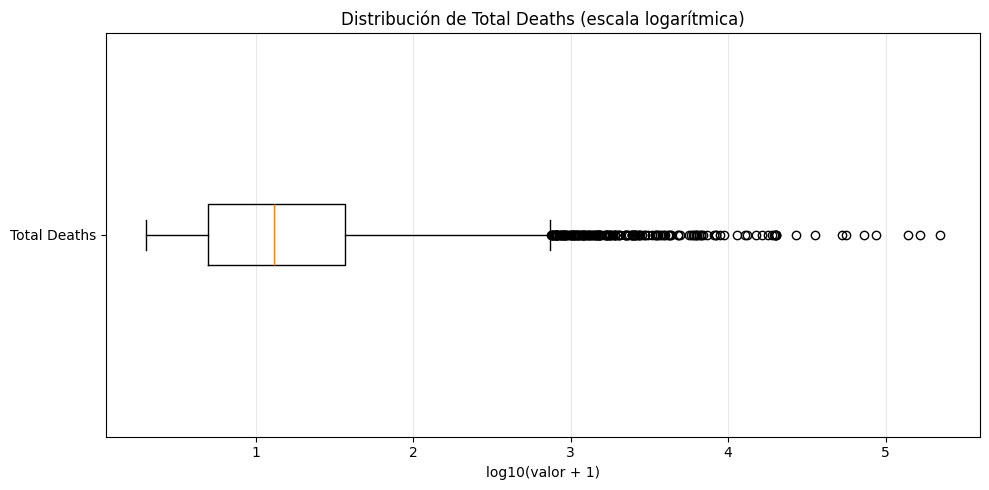

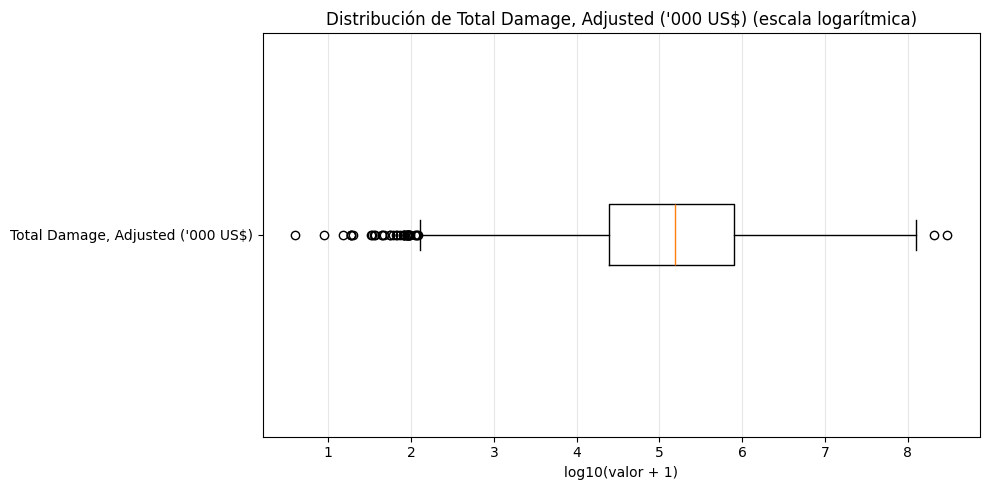

In [36]:
for columna in variables_extremos:
    valores = datos_extremos[columna].dropna()

    # Logaritmo de base 10 de (valor + 1)
    valores_log = np.log10(valores + 1)

    plt.figure(figsize=(10, 5))
    plt.boxplot(valores_log, vert=False)

    plt.title(f"Distribución de {columna} (escala logarítmica)")
    plt.xlabel("log10(valor + 1)")
    plt.yticks([1], [columna])
    plt.grid(axis="x", alpha=0.3)
    plt.tight_layout()
    plt.show()


# Paso 2. Detectar candidatos a valores atípicos con IQR

- El rango intercuartílico se calcula:
IQR = Q3 - Q1

- El límite superior habitual:
Ls = Q3 + 1.5(IQR)

In [37]:

# Detectar valores extremos altos mediante IQR
resultados_iqr = []
mascaras_atipicos = {}

for columna in variables_extremos:

    valores = datos_extremos[columna]

    # Ignorar valores faltantes para calcular los cuartiles
    disponibles = valores.dropna()

    q1 = disponibles.quantile(0.25)
    q3 = disponibles.quantile(0.75)
    iqr = q3 - q1

    limite_inferior = q1 - 1.5 * iqr
    limite_superior = q3 + 1.5 * iqr

    # En este proyecto nos interesan los valores altos
    mascara = valores.notna() & (valores > limite_superior)
    mascaras_atipicos[columna] = mascara

    resultados_iqr.append({
        "Variable": columna,
        "Datos_disponibles": len(disponibles),
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "Limite_inferior": limite_inferior,
        "Limite_superior": limite_superior,
        "Candidatos_extremos_altos": int(mascara.sum())
    })

resumen_iqr = pd.DataFrame(resultados_iqr)

display(resumen_iqr.round(2))


,Variable,Datos_disponibles,Q1,Q3,IQR,Limite_inferior,Limite_superior,Candidatos_extremos_altos
0,Total Deaths,7835,4.0,36.0,32.0,-44.0,84.0,1027
1,"Total Damage, Adjusted ('000 US$)",3312,24357.0,804833.0,780476.0,-1146357.0,1975547.0,456


# Paso 3. Examinar los eventos identificados

In [38]:

# Columnas útiles para investigar cada evento
columnas_evento = [
    "DisNo.",
    "Country",
    "Disaster Type",
    "Disaster Subtype",
    "Event Name",
    "Start Year",
    "Total Deaths",
    "Total Damage, Adjusted ('000 US$)"
]

columnas_evento = [
    c for c in columnas_evento
    if c in df_trabajo.columns
]

for columna in variables_extremos:

    print(f"\n--- Candidatos extremos: {columna} ---")

    mascara = mascaras_atipicos[columna]

    # Mostrar primero los valores más altos
    candidatos = df_trabajo.loc[
        mascara, columnas_evento
    ].copy()

    candidatos = candidatos.sort_values(
        by=columna,
        ascending=False
    )

    print("Cantidad de candidatos:", len(candidatos))
    display(candidatos.head(20))



--- Candidatos extremos: Total Deaths ---
Cantidad de candidatos: 1027


,DisNo.,Country,Disaster Type,Disaster Subtype,Event Name,Start Year,Total Deaths,"Total Damage, Adjusted ('000 US$)"
4533,2010-0017-HTI,Haiti,Earthquake,Ground movement,NaN,2010,222570.0,11811414.0
2449,2004-0659-IDN,Indonesia,Earthquake,Tsunami,NaN,2004,165708.0,7587548.0
2825,2008-0184-MMR,Myanmar,Storm,Tropical cyclone,Cyclone 'Nargis',2008,138366.0,5981221.0
9811,2008-0192-CHN,China,Earthquake,Ground movement,NaN,2008,87476.0,127100952.0
4082,2005-0575-PAK,Pakistan,Earthquake,Ground movement,NaN,2005,73338.0,8572324.0
3069,2010-0372-RUS,Russian Federation,Extreme temperature,Heat wave,NaN,2010,55736.0,590571.0
5718,2023-0054-TUR,Türkiye,Earthquake,Ground movement,NaN,2023,53000.0,35923858.0
9422,2004-0659-LKA,Sri Lanka,Earthquake,Tsunami,NaN,2004,35399.0,2243914.0
9339,2003-0630-IRN,Iran (Islamic Republic of),Earthquake,Ground movement,NaN,2003,26796.0,875043.0
9307,2003-0391-ITA,Italy,Extreme temperature,Heat wave,NaN,2003,20089.0,7700380.0



--- Candidatos extremos: Total Damage, Adjusted ('000 US$) ---
Cantidad de candidatos: 456


,DisNo.,Country,Disaster Type,Disaster Subtype,Event Name,Start Year,Total Deaths,"Total Damage, Adjusted ('000 US$)"
3153,2011-0082-JPN,Japan,Earthquake,Tsunami,NaN,2011,19846.0,300561348.0
9498,2005-0467-USA,United States of America,Storm,Tropical cyclone,Katrina,2005,1833.0,206065474.0
9811,2008-0192-CHN,China,Earthquake,Ground movement,NaN,2008,87476.0,127100952.0
5201,2017-0362-USA,United States of America,Storm,Tropical cyclone,Hurricane Harvey,2017,88.0,124774087.0
8619,2022-0614-USA,United States of America,Storm,Tropical cyclone,Hurricane 'Ian',2022,152.0,110007737.0
964,2017-0383-PRI,Puerto Rico,Storm,Tropical cyclone,Hurricane 'Maria',2017,64.0,89311978.0
2103,2024-0693-USA,United States of America,Storm,Tropical cyclone,Tropical cyclone 'Helene',2024,219.0,82105029.0
5582,2021-0551-USA,United States of America,Storm,Tropical cyclone,Tropical storm 'Ida',2021,96.0,77227433.0
10682,2017-0381-USA,United States of America,Storm,Tropical cyclone,Hurricane 'Irma',2017,97.0,74864452.0
98,2012-0410-USA,United States of America,Storm,Tropical cyclone,Hurricane 'Sandy',2012,158.0,70111391.0


# Paso 4. Guardar los reportes

In [39]:

# Guardar el resumen estadístico del método IQR
carpeta_resultados = Path("../resultados")
carpeta_resultados.mkdir(parents=True, exist_ok=True)

resumen_iqr.to_csv(
    carpeta_resultados / "resumen_valores_atipicos_iqr.csv",
    index=False,
    encoding="utf-8"
)

# Unir los candidatos detectados en cualquiera de las variables
mascara_cualquier_atipico = pd.Series(
    False,
    index=df_trabajo.index
)

for mascara in mascaras_atipicos.values():
    mascara_cualquier_atipico |= mascara

reporte_candidatos = df_trabajo.loc[
    mascara_cualquier_atipico,
    columnas_evento
].copy()

reporte_candidatos.to_csv(
    carpeta_resultados / "candidatos_valores_atipicos.csv",
    index=False,
    encoding="utf-8"
)

print("Reportes guardados en:", carpeta_resultados)
print("Registros únicos candidatos:",
      len(reporte_candidatos))


Reportes guardados en:

 ..\resultados
Registros únicos candidatos: 1355


In [40]:
resumen_iqr

,Variable,Datos_disponibles,Q1,Q3,IQR,Limite_inferior,Limite_superior,Candidatos_extremos_altos
0,Total Deaths,7835,4.0,36.0,32.0,-44.0,84.0,1027
1,"Total Damage, Adjusted ('000 US$)",3312,24357.0,804833.0,780476.0,-1146357.0,1975547.0,456


In [41]:
reporte_candidatos

,DisNo.,Country,Disaster Type,Disaster Subtype,Event Name,Start Year,Total Deaths,"Total Damage, Adjusted ('000 US$)"
2,2025-0750-AFG,Afghanistan,Earthquake,Ground movement,NaN,2025,2200.0,180000.0
4,2024-0962-AGO,Angola,Epidemic,Bacterial disease,Cholera,2025,776.0,NaN
9,2026-0227-BGD,Bangladesh,Epidemic,Viral disease,Meales,2026,253.0,NaN
11,2025-0694-SOM,Somalia,Epidemic,Bacterial disease,Diphteria,2025,89.0,NaN
14,2025-0161-ARG,Argentina,Flood,Flood (General),NaN,2025,125.0,375000.0
...,...,...,...,...,...,...,...,...
10876,2019-0417-USA,United States of America,Storm,Tropical cyclone,Tropical storm ' Imelda',2019,5.0,4407462.0
10885,2019-0455-COL,Colombia,Epidemic,Viral disease,Dengue,2019,169.0,NaN
10892,2019-0521-JPN,Japan,Storm,Tropical cyclone,Typhoon 'Faxai',2019,3.0,11459401.0
10896,2019-0500-KEN,Kenya,Flood,Flash flood,NaN,2019,90.0,NaN


In [42]:
#Mostrar los 15 eventos con más fallecimientos

columnas_evento = [
    "DisNo.",
    "Country",
    "Disaster Type",
    "Disaster Subtype",
    "Event Name",
    "Start Year",
    "Total Deaths",
    "Total Damage, Adjusted ('000 US$)"
]

# Conservar solamente las columnas que existen
columnas_evento = [
    c for c in columnas_evento
    if c in df_trabajo.columns
]

# Obtener el límite superior calculado para fallecimientos
limite_muertes = resumen_iqr.loc[
    resumen_iqr["Variable"] == "Total Deaths",
    "Limite_superior"
].iloc[0]

# Seleccionar candidatos con más fallecimientos que el límite
candidatos_muertes = df_trabajo.loc[
    pd.to_numeric(
        df_trabajo["Total Deaths"],
        errors="coerce"
    ) > limite_muertes,
    columnas_evento
].copy()

# Ordenar de mayor a menor cantidad de fallecimientos
candidatos_muertes = candidatos_muertes.sort_values(
    by="Total Deaths",
    ascending=False
)

display(candidatos_muertes.head(15))


,DisNo.,Country,Disaster Type,Disaster Subtype,Event Name,Start Year,Total Deaths,"Total Damage, Adjusted ('000 US$)"
4533,2010-0017-HTI,Haiti,Earthquake,Ground movement,NaN,2010,222570.0,11811414.0
2449,2004-0659-IDN,Indonesia,Earthquake,Tsunami,NaN,2004,165708.0,7587548.0
2825,2008-0184-MMR,Myanmar,Storm,Tropical cyclone,Cyclone 'Nargis',2008,138366.0,5981221.0
9811,2008-0192-CHN,China,Earthquake,Ground movement,NaN,2008,87476.0,127100952.0
4082,2005-0575-PAK,Pakistan,Earthquake,Ground movement,NaN,2005,73338.0,8572324.0
3069,2010-0372-RUS,Russian Federation,Extreme temperature,Heat wave,NaN,2010,55736.0,590571.0
5718,2023-0054-TUR,Türkiye,Earthquake,Ground movement,NaN,2023,53000.0,35923858.0
9422,2004-0659-LKA,Sri Lanka,Earthquake,Tsunami,NaN,2004,35399.0,2243914.0
9339,2003-0630-IRN,Iran (Islamic Republic of),Earthquake,Ground movement,NaN,2003,26796.0,875043.0
9307,2003-0391-ITA,Italy,Extreme temperature,Heat wave,NaN,2003,20089.0,7700380.0


In [43]:
#Mostrar los 15 eventos con mayores daños económicos


columna_danos = "Total Damage, Adjusted ('000 US$)"

limite_danos = resumen_iqr.loc[
    resumen_iqr["Variable"] == columna_danos,
    "Limite_superior"
].iloc[0]

# Seleccionar eventos que superan el límite IQR
candidatos_danos = df_trabajo.loc[
    pd.to_numeric(
        df_trabajo[columna_danos],
        errors="coerce"
    ) > limite_danos,
    columnas_evento
].copy()

# Ordenar de mayor a menor daño económico ajustado
candidatos_danos = candidatos_danos.sort_values(
    by=columna_danos,
    ascending=False
)

display(candidatos_danos.head(15))


,DisNo.,Country,Disaster Type,Disaster Subtype,Event Name,Start Year,Total Deaths,"Total Damage, Adjusted ('000 US$)"
3153,2011-0082-JPN,Japan,Earthquake,Tsunami,NaN,2011,19846.0,300561348.0
9498,2005-0467-USA,United States of America,Storm,Tropical cyclone,Katrina,2005,1833.0,206065474.0
9811,2008-0192-CHN,China,Earthquake,Ground movement,NaN,2008,87476.0,127100952.0
5201,2017-0362-USA,United States of America,Storm,Tropical cyclone,Hurricane Harvey,2017,88.0,124774087.0
8619,2022-0614-USA,United States of America,Storm,Tropical cyclone,Hurricane 'Ian',2022,152.0,110007737.0
964,2017-0383-PRI,Puerto Rico,Storm,Tropical cyclone,Hurricane 'Maria',2017,64.0,89311978.0
2103,2024-0693-USA,United States of America,Storm,Tropical cyclone,Tropical cyclone 'Helene',2024,219.0,82105029.0
5582,2021-0551-USA,United States of America,Storm,Tropical cyclone,Tropical storm 'Ida',2021,96.0,77227433.0
10682,2017-0381-USA,United States of America,Storm,Tropical cyclone,Hurricane 'Irma',2017,97.0,74864452.0
98,2012-0410-USA,United States of America,Storm,Tropical cyclone,Hurricane 'Sandy',2012,158.0,70111391.0


# Guardar las listas ordenadas

In [44]:

carpeta_resultados = Path("../resultados")
carpeta_resultados.mkdir(parents=True, exist_ok=True)

candidatos_muertes.to_csv(
    carpeta_resultados / "candidatos_extremos_fallecimientos.csv",
    index=False,
    encoding="utf-8"
)

candidatos_danos.to_csv(
    carpeta_resultados / "candidatos_extremos_danos_economicos.csv",
    index=False,
    encoding="utf-8"
)

print("Candidatos por fallecimientos:", len(candidatos_muertes))
print("Candidatos por daños económicos:", len(candidatos_danos))
print("Archivos guardados en:", carpeta_resultados)


Candidatos por fallecimientos: 1027
Candidatos por daños económicos: 456
Archivos guardados en: ..\resultados


In [45]:
# Mostrar las columnas y sus nombres exactos
print(df_trabajo.columns.tolist())

# Mostrar los primeros cinco eventos extremos por fallecimientos
display(
    candidatos_muertes[
        [
            "DisNo.",
            "Country",
            "Start Year",
            "Total Deaths"
        ]
    ].head(5)
)

# Mostrar los primeros cinco por daños económicos
display(
    candidatos_danos[
        [
            "DisNo.",
            "Country",
            "Start Year",
            "Total Damage, Adjusted ('000 US$)"
        ]
    ].head(5)
)


['DisNo.', 'Historic', 'Classification Key', 'Disaster Group', 'Disaster Subgroup', 'Disaster Type', 'Disaster Subtype', 'External IDs', 'Event Name', 'ISO', 'Country', 'Subregion', 'Region', 'Location', 'Origin', 'Associated Types', 'OFDA/BHA Response', 'Appeal', 'Declaration', "AID Contribution ('000 US$)", 'Magnitude', 'Magnitude Scale', 'Latitude', 'Longitude', 'River Basin', 'Start Year', 'Start Month', 'Start Day', 'End Year', 'End Month', 'End Day', 'Total Deaths', 'No. Injured', 'No. Affected', 'No. Homeless', 'Total Affected', "Reconstruction Costs ('000 US$)", "Reconstruction Costs, Adjusted ('000 US$)", "Insured Damage ('000 US$)", "Insured Damage, Adjusted ('000 US$)", "Total Damage ('000 US$)", "Total Damage, Adjusted ('000 US$)", 'CPI', 'Admin Units', 'GADM Admin Units', 'Entry Date', 'Last Update', 'Falta_Total_Deaths', 'Falta_Total_Affected', 'Falta_Danos_Economicos', 'Falta_Coordenadas', 'Revisar_anio_identificador', 'Revisar_fechas']


,DisNo.,Country,Start Year,Total Deaths
4533,2010-0017-HTI,Haiti,2010,222570.0
2449,2004-0659-IDN,Indonesia,2004,165708.0
2825,2008-0184-MMR,Myanmar,2008,138366.0
9811,2008-0192-CHN,China,2008,87476.0
4082,2005-0575-PAK,Pakistan,2005,73338.0


,DisNo.,Country,Start Year,"Total Damage, Adjusted ('000 US$)"
3153,2011-0082-JPN,Japan,2011,300561348.0
9498,2005-0467-USA,United States of America,2005,206065474.0
9811,2008-0192-CHN,China,2008,127100952.0
5201,2017-0362-USA,United States of America,2017,124774087.0
8619,2022-0614-USA,United States of America,2022,110007737.0


# Análisis exploratorio (EDA)

In [46]:
# Carpeta para guardar las gráficas del proyecto
carpeta_graficas = Path("../resultados/graficas")
carpeta_graficas.mkdir(parents=True, exist_ok=True)

# Revisar que las variables necesarias existan
columnas_necesarias = [
    "DisNo.",
    "Country",
    "Disaster Type",
    "Start Year",
    "Total Deaths",
    "Total Damage, Adjusted ('000 US$)"
]

for columna in columnas_necesarias:
    if columna not in df_trabajo.columns:
        print("Falta la columna:", columna)

print("Dimensiones actuales:", df_trabajo.shape)
print("Carpeta de gráficas:", carpeta_graficas.resolve())


Dimensiones actuales: (10907, 53)
Carpeta de gráficas: C:\Users\itzel\PROYECTO_DESASTRES\resultados\graficas


Gráfica de registros por año

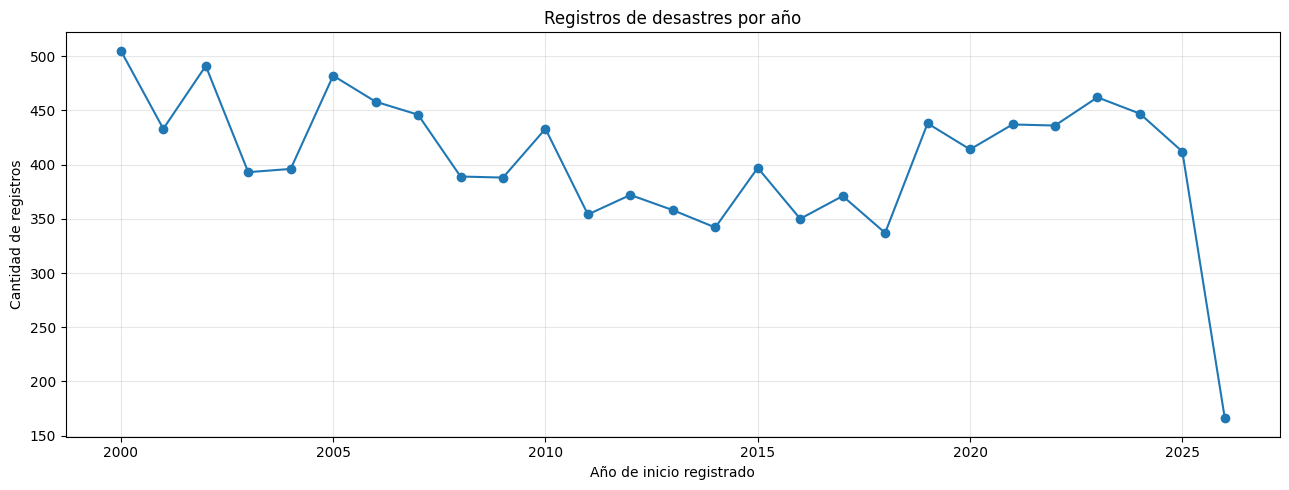

,Start Year,Cantidad_registros
12,2012,372
13,2013,358
14,2014,342
15,2015,397
16,2016,350
17,2017,371
18,2018,337
19,2019,438
20,2020,414
21,2021,437


In [47]:
# Crear una copia numérica del año
anio = pd.to_numeric(
    df_trabajo["Start Year"],
    errors="coerce"
)

# Contar registros por año
registros_por_anio = (
    anio.dropna()
    .astype(int)
    .value_counts()
    .sort_index()
)

plt.figure(figsize=(13, 5))
plt.plot(
    registros_por_anio.index,
    registros_por_anio.values,
    marker="o",
    linewidth=1.5
)

plt.title("Registros de desastres por año")
plt.xlabel("Año de inicio registrado")
plt.ylabel("Cantidad de registros")
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    carpeta_graficas / "01_registros_por_anio.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

display(
    registros_por_anio.rename("Cantidad_registros")
    .reset_index()
    .rename(columns={
        "index": "Start Year",
        "Cantidad_registros": "Cantidad_registros"
    })
    .tail(15)
)

Gráfica por tipo de desastre

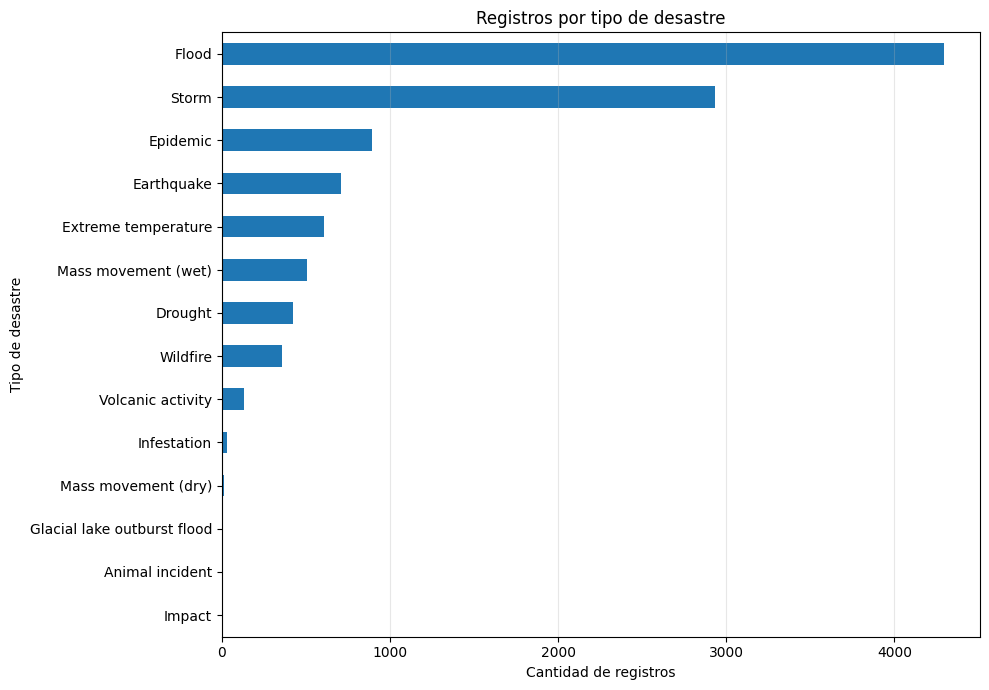

,Cantidad_registros
Disaster Type,
Flood,4294
Storm,2930
Epidemic,895
Earthquake,707
Extreme temperature,606
Mass movement (wet),505
Drought,426
Wildfire,356
Volcanic activity,134


In [48]:

# Contar registros por tipo de desastre
registros_por_tipo = (
    df_trabajo["Disaster Type"]
    .fillna("Sin dato")
    .value_counts()
    .sort_values(ascending=True)
)

plt.figure(figsize=(10, 7))
registros_por_tipo.plot(kind="barh")

plt.title("Registros por tipo de desastre")
plt.xlabel("Cantidad de registros")
plt.ylabel("Tipo de desastre")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()

plt.savefig(
    carpeta_graficas / "02_registros_por_tipo.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

display(
    registros_por_tipo.sort_values(ascending=False)
    .rename("Cantidad_registros")
    .to_frame()
)


Analizar los fallecimientos y daños económicos por año

,Start Year,Registros,Registros_con_muertes,Fallecimientos_informados,Registros_con_danos,Danos_ajustados_informados
12,2012,372,283,11728.0,145,224356300.0
13,2013,358,266,22202.0,168,166711757.0
14,2014,342,245,20888.0,153,133367789.0
15,2015,397,281,24332.0,158,119023175.0
16,2016,350,256,10730.0,154,198810888.0
17,2017,371,261,11912.0,153,429184202.0
18,2018,337,224,15989.0,127,171285775.0
19,2019,438,339,22667.0,72,127087344.0
20,2020,414,293,15766.0,141,219239463.0
21,2021,437,269,14619.0,145,306073747.0


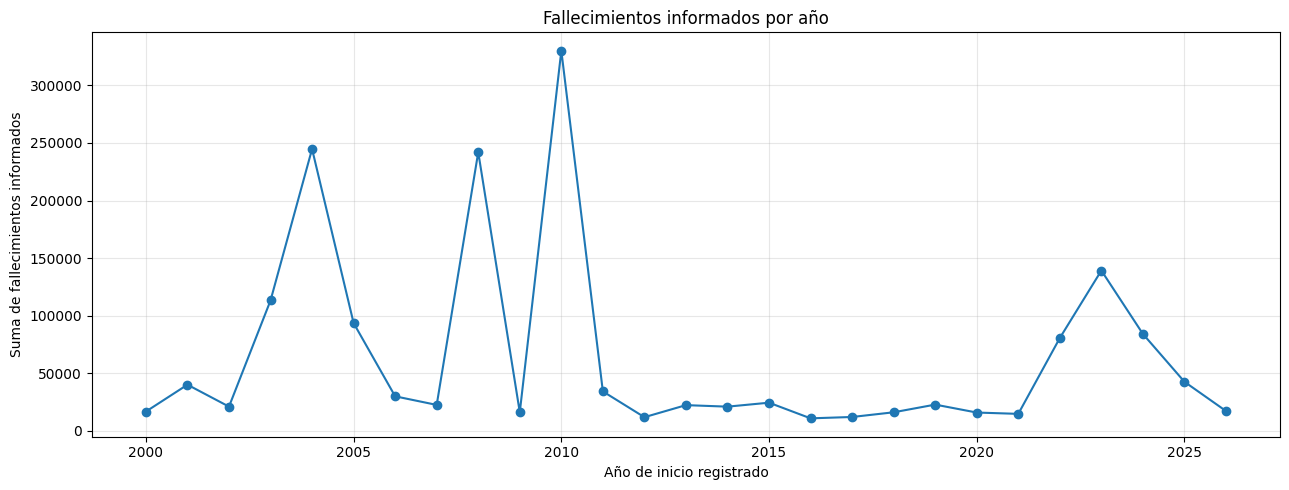

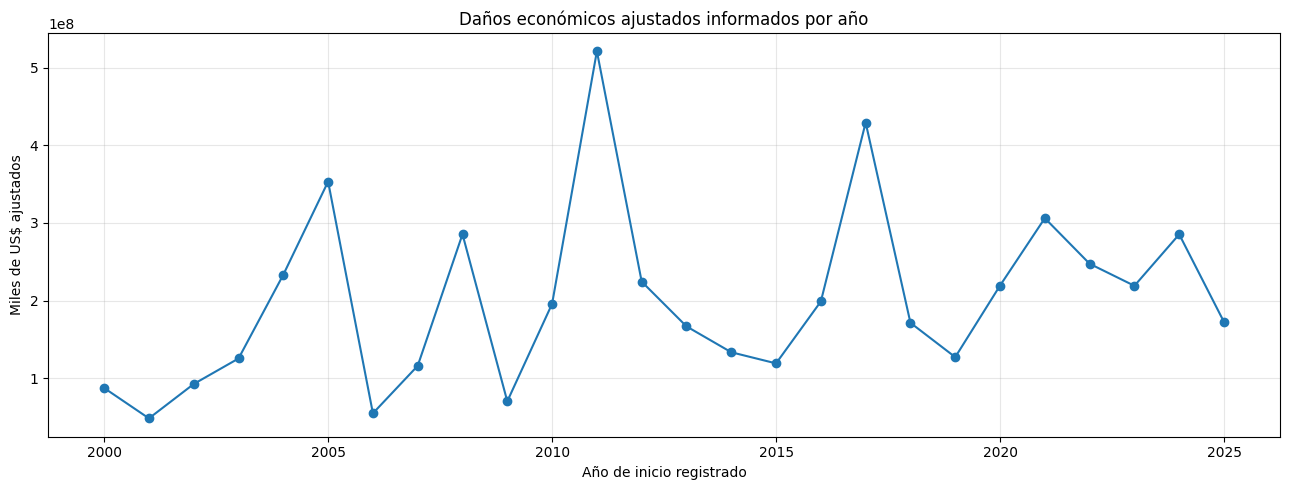

In [49]:

# Convertir las variables a valores numéricos
muertes = pd.to_numeric(
    df_trabajo["Total Deaths"],
    errors="coerce"
)

danos = pd.to_numeric(
    df_trabajo["Total Damage, Adjusted ('000 US$)"],
    errors="coerce"
)

datos_temporales = pd.DataFrame({
    "Start Year": anio,
    "Total Deaths": muertes,
    "Danos_ajustados": danos
}).dropna(subset=["Start Year"])

# Agrupar por año y calcular sumas y cobertura
resumen_anual = datos_temporales.groupby("Start Year").agg(
    Registros=("Start Year", "size"),
    Registros_con_muertes=("Total Deaths", "count"),
    Fallecimientos_informados=(
        "Total Deaths",
        lambda x: x.sum(min_count=1)
    ),
    Registros_con_danos=("Danos_ajustados", "count"),
    Danos_ajustados_informados=(
        "Danos_ajustados",
        lambda x: x.sum(min_count=1)
    )
).reset_index()

display(resumen_anual.tail(15))

# Gráfica de fallecimientos informados por año
plt.figure(figsize=(13, 5))
plt.plot(
    resumen_anual["Start Year"],
    resumen_anual["Fallecimientos_informados"],
    marker="o"
)
plt.title("Fallecimientos informados por año")
plt.xlabel("Año de inicio registrado")
plt.ylabel("Suma de fallecimientos informados")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(
    carpeta_graficas / "03_fallecimientos_por_anio.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# Gráfica de daños económicos ajustados por año
plt.figure(figsize=(13, 5))
plt.plot(
    resumen_anual["Start Year"],
    resumen_anual["Danos_ajustados_informados"],
    marker="o"
)
plt.title("Daños económicos ajustados informados por año")
plt.xlabel("Año de inicio registrado")
plt.ylabel("Miles de US$ ajustados")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(
    carpeta_graficas / "04_danos_ajustados_por_anio.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# Guardar la tabla anual para el reporte
resumen_anual.to_csv(
    carpeta_graficas.parent / "resumen_anual.csv",
    index=False,
    encoding="utf-8"
)


Visualizar los valores faltantes

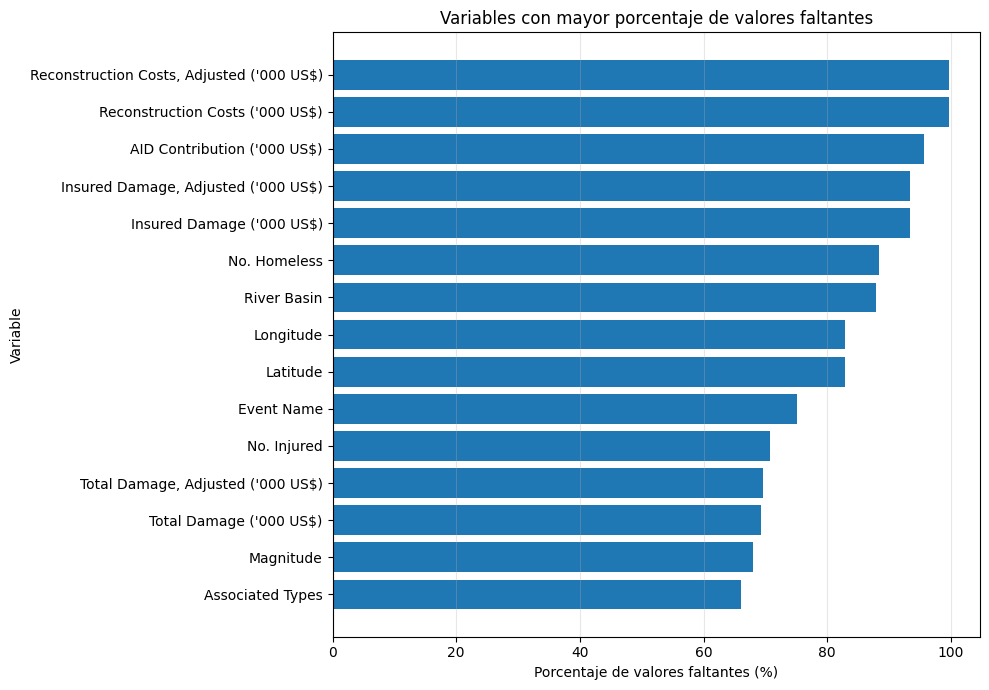

,Valores_faltantes,Porcentaje_faltante
"Reconstruction Costs, Adjusted ('000 US$)",10875,99.71
Reconstruction Costs ('000 US$),10874,99.70
AID Contribution ('000 US$),10426,95.59
"Insured Damage, Adjusted ('000 US$)",10187,93.40
Insured Damage ('000 US$),10184,93.37
No. Homeless,9635,88.34
River Basin,9581,87.84
Latitude,9043,82.91
Longitude,9043,82.91
Event Name,8192,75.11


In [50]:

# Calcular cantidad y porcentaje de valores faltantes
resumen_faltantes = pd.DataFrame({
    "Valores_faltantes": df_trabajo.isna().sum(),
    "Porcentaje_faltante": (
        df_trabajo.isna().mean() * 100
    )
})

# Mostrar las 15 columnas con mayor porcentaje de faltantes
faltantes_top = (
    resumen_faltantes
    .sort_values("Porcentaje_faltante", ascending=False)
    .head(15)
    .sort_values("Porcentaje_faltante")
)

plt.figure(figsize=(10, 7))
plt.barh(
    faltantes_top.index,
    faltantes_top["Porcentaje_faltante"]
)

plt.title("Variables con mayor porcentaje de valores faltantes")
plt.xlabel("Porcentaje de valores faltantes (%)")
plt.ylabel("Variable")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.savefig(
    carpeta_graficas / "05_valores_faltantes.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

display(
    resumen_faltantes.sort_values(
        "Porcentaje_faltante",
        ascending=False
    ).round(2)
)


In [51]:
resumen_anual

,Start Year,Registros,Registros_con_muertes,Fallecimientos_informados,Registros_con_danos,Danos_ajustados_informados
0,2000,505,352,16611.0,153,87328867.0
1,2001,433,296,39958.0,133,48214918.0
2,2002,491,338,20911.0,149,92463552.0
3,2003,393,283,113136.0,123,125331163.0
4,2004,396,267,244765.0,137,233284114.0
5,2005,482,354,93494.0,142,353196632.0
6,2006,458,332,29863.0,103,54705339.0
7,2007,446,350,22399.0,131,115897484.0
8,2008,389,283,241993.0,111,285410786.0
9,2009,388,282,16038.0,104,70172051.0


# detectar registros duplicados

In [52]:

# 1. Revisar registros completamente duplicados
duplicados_completos = df_trabajo.duplicated().sum()

# 2. Revisar identificadores de desastre repetidos
duplicados_id = df_trabajo["DisNo."].duplicated().sum()

print("Registros totales:", len(df_trabajo))
print("Filas completamente duplicadas:", duplicados_completos)
print("Identificadores DisNo. repetidos:", duplicados_id)

# 3. Mostrar los registros que comparten identificador
detalle_duplicados = df_trabajo[
    df_trabajo["DisNo."].duplicated(keep=False)
].sort_values("DisNo.")

display(detalle_duplicados.head(20))

# 4. Guardar los posibles duplicados para su revisión
if not detalle_duplicados.empty:
    detalle_duplicados.to_csv(
        "../resultados/duplicados_por_identificador.csv",
        index=False,
        encoding="utf-8-sig"
    )
    print("Revisión guardada en resultados.")
else:
    print("No se encontraron identificadores repetidos.")


Registros totales: 10907
Filas completamente duplicadas: 0
Identificadores DisNo. repetidos: 0


,DisNo.,Historic,Classification Key,Disaster Group,Disaster Subgroup,Disaster Type,Disaster Subtype,External IDs,Event Name,ISO,...,Admin Units,GADM Admin Units,Entry Date,Last Update,Falta_Total_Deaths,Falta_Total_Affected,Falta_Danos_Economicos,Falta_Coordenadas,Revisar_anio_identificador,Revisar_fechas


No se encontraron identificadores repetidos.


# Comprobar la integridad de los datos de 2026

In [53]:

# Revisar los registros de 2026
datos_2026 = df_trabajo[
    pd.to_numeric(df_trabajo["Start Year"], errors="coerce") == 2026
].copy()

columna_danos = "Total Damage, Adjusted ('000 US$)"

print("Eventos registrados en 2026:", len(datos_2026))
print(
    "Daños ajustados disponibles:",
    datos_2026[columna_danos].notna().sum()
)
print(
    "Daños ajustados faltantes:",
    datos_2026[columna_danos].isna().sum()
)

display(
    datos_2026[
        ["DisNo.", "Country", "Disaster Type",
         "Total Deaths", columna_danos]
    ].head(15)
)


Eventos registrados en 2026: 166
Daños ajustados disponibles: 0
Daños ajustados faltantes: 166


,DisNo.,Country,Disaster Type,Total Deaths,"Total Damage, Adjusted ('000 US$)"
1,2026-0153-KEN,Kenya,Flood,59.0,NaN
3,2026-0305-AFG,Afghanistan,Flood,18.0,NaN
6,2026-0174-SYR,Syrian Arab Republic,Storm,7.0,NaN
7,1988-0424-VEN,Venezuela (Bolivarian Republic of),Storm,5.0,NaN
9,2026-0227-BGD,Bangladesh,Epidemic,253.0,NaN
10,2026-0310-COD,Democratic Republic of the Congo,Flood,6.0,NaN
15,2026-0353-AFG,Afghanistan,Flood,28.0,NaN
16,2026-0417-ECU,Ecuador,Flood,18.0,NaN
18,2026-0019-PHL,Philippines,Volcanic activity,NaN,NaN
19,2026-0087-PRT,Portugal,Storm,1.0,NaN


# revisar las fechas inconsistentes

In [54]:
# Crear una tabla de revisión independiente
revision_fechas = df_trabajo[
    [
        "DisNo.", "Country", "Disaster Type",
        "Start Year", "Start Month", "Start Day",
        "End Year", "End Month", "End Day"
    ]
].copy()

# Convertir los campos de fecha a valores numéricos
columnas_fecha = [
    "Start Year", "Start Month", "Start Day",
    "End Year", "End Month", "End Day"
]

for columna in columnas_fecha:
    revision_fechas[columna] = pd.to_numeric(
        revision_fechas[columna], errors="coerce"
    )

# Extraer el año del identificador DisNo.
revision_fechas["Anio_DisNo"] = pd.to_numeric(
    revision_fechas["DisNo."].astype("string").str.slice(0, 4),
    errors="coerce"
)

# Identificar diferencias entre el año del ID y el año de inicio
revision_fechas["Anio_ID_difiere_inicio"] = (
    revision_fechas["Anio_DisNo"] != revision_fechas["Start Year"]
)

# Construir fechas solo cuando los componentes están disponibles
revision_fechas["Fecha_inicio"] = pd.to_datetime(
    {
        "year": revision_fechas["Start Year"],
        "month": revision_fechas["Start Month"],
        "day": revision_fechas["Start Day"]
    },
    errors="coerce"
)

revision_fechas["Fecha_fin"] = pd.to_datetime(
    {
        "year": revision_fechas["End Year"],
        "month": revision_fechas["End Month"],
        "day": revision_fechas["End Day"]
    },
    errors="coerce"
)

# Detectar fechas completas cuya secuencia parece incorrecta
revision_fechas["Inicio_posterior_fin"] = (
    revision_fechas["Fecha_inicio"].notna()
    & revision_fechas["Fecha_fin"].notna()
    & (revision_fechas["Fecha_inicio"] > revision_fechas["Fecha_fin"])
)

# Mostrar únicamente los casos que requieren revisión
casos_revision = revision_fechas[
    revision_fechas["Anio_ID_difiere_inicio"]
    | revision_fechas["Inicio_posterior_fin"]
].copy()

columnas_mostrar = [
    "DisNo.", "Country", "Disaster Type",
    "Anio_DisNo", "Start Year", "End Year",
    "Fecha_inicio", "Fecha_fin",
    "Anio_ID_difiere_inicio", "Inicio_posterior_fin"
]

print("Registros que requieren revisión:", len(casos_revision))
display(casos_revision[columnas_mostrar].head(30))

# Guardar los casos para documentarlos en el informe
carpeta_resultados = Path("../resultados")
carpeta_resultados.mkdir(parents=True, exist_ok=True)

casos_revision[columnas_mostrar].to_csv(
    carpeta_resultados / "revision_fechas.csv",
    index=False,
    encoding="utf-8-sig"
)


Registros que requieren revisión: 55


,DisNo.,Country,Disaster Type,Anio_DisNo,Start Year,End Year,Fecha_inicio,Fecha_fin,Anio_ID_difiere_inicio,Inicio_posterior_fin
4,2024-0962-AGO,Angola,Epidemic,2024,2025,2025,2025-01-07,NaT,True,False
7,1988-0424-VEN,Venezuela (Bolivarian Republic of),Storm,1988,2026,1988,2026-09-11,1988-09-11,True,True
61,2026-0221-IDN,Indonesia,Earthquake,2026,2026,2026,2026-04-02,2026-03-02,False,True
65,1995-0275-NPL,Nepal,Storm,1995,2026,1995,2026-11-10,1995-11-11,True,True
358,1999-9388-DJI,Djibouti,Drought,1999,2001,2001,NaT,NaT,True,False
770,2018-9277-CRI,Costa Rica,Drought,2018,2019,2019,NaT,NaT,True,False
1492,2014-9580-SLV,El Salvador,Drought,2014,2015,2016,NaT,NaT,True,False
1518,2014-0530-MWI,Malawi,Epidemic,2014,2015,2015,NaT,NaT,True,False
1524,2014-0529-BOL,Bolivia (Plurinational State of),Flood,2014,2015,2015,2015-01-15,2015-01-31,True,False
1640,2025-0075-AUS,Australia,Flood,2025,2024,2025,2024-02-29,2025-02-05,True,False


# separar las inconsistencias por tipo

In [55]:

# Clasificar los hallazgos sin modificar df_trabajo
revision_fechas["Tipo_revision"] = "Revisar"

revision_fechas.loc[
    revision_fechas["Anio_ID_difiere_inicio"],
    "Tipo_revision"
] = "Diferencia entre anio del ID y anio de inicio"

revision_fechas.loc[
    revision_fechas["Inicio_posterior_fin"],
    "Tipo_revision"
] = "Inicio posterior al fin"

# Los registros con ambas condiciones tendrán una categoría propia
revision_fechas.loc[
    revision_fechas["Anio_ID_difiere_inicio"]
    & revision_fechas["Inicio_posterior_fin"],
    "Tipo_revision"
] = "Diferencia de anio y orden temporal incorrecto"

# Resumen de categorías
resumen_revision = (
    revision_fechas.loc[casos_revision.index, "Tipo_revision"]
    .value_counts()
    .rename_axis("Tipo_revision")
    .reset_index(name="Cantidad")
)

display(resumen_revision)

# Revisar fechas de inicio posteriores a la fecha actual
fecha_actual = pd.Timestamp("2026-10-11")

inicios_futuros = revision_fechas[
    revision_fechas["Fecha_inicio"] > fecha_actual
]

print("Registros con fecha de inicio posterior al 11/10/2026:",
      len(inicios_futuros))

display(
    inicios_futuros[
        ["DisNo.", "Country", "Fecha_inicio", "Fecha_fin"]
    ].head(20)
)

# Guardar la revisión completa
revision_fechas.loc[casos_revision.index].to_csv(
    "../resultados/revision_fechas_clasificada.csv",
    index=False,
    encoding="utf-8-sig"
)


,Tipo_revision,Cantidad
0,Diferencia entre anio del ID y anio de inicio,52
1,Diferencia de anio y orden temporal incorrecto,2
2,Inicio posterior al fin,1


Registros con fecha de inicio posterior al 11/10/2026: 1


,DisNo.,Country,Fecha_inicio,Fecha_fin
65,1995-0275-NPL,Nepal,2026-11-10,1995-11-11


### Revisión de la consistencia temporal

Se analizaron los campos de fecha de inicio y finalización de los eventos, así como el año incluido en el identificador `DisNo.`. Se identificaron 55 registros que requieren revisión por diferencias entre el año del identificador y el año de inicio, por un orden temporal inconsistente o por ambas condiciones.

Estos resultados representan casos potenciales de inconsistencia y no necesariamente errores confirmados. Por ello, se conservaron los registros originales y se generó una tabla independiente para documentar los casos identificados. No se realizaron correcciones automáticas, ya que estas podrían alterar información válida o eliminar características propias de eventos que abarcan más de un año.

Los casos con fechas de inicio posteriores a las fechas de finalización requieren especial atención. Asimismo, las fechas incompletas limitan la posibilidad de verificar la secuencia temporal de algunos eventos. Estas situaciones se documentarán como parte del control de calidad y de las limitaciones del conjunto de datos.

# Integración geográfica

In [56]:
# Comprobar si GeoPandas está instalado
try:
    import geopandas as gpd
    print("GeoPandas instalado:", gpd.__version__)
except ImportError:
    print("GeoPandas no está instalado.")

# Revisar si el archivo de Natural Earth existe
from pathlib import Path

carpeta_geo = Path("../datos/geograficos/ne_110m_admin_0_countries")

archivos_shp = list(carpeta_geo.glob("*.shp"))

print("\nArchivos shapefile encontrados:")
for archivo in archivos_shp:
    print(archivo.name)


GeoPandas instalado: 1.2.0

Archivos shapefile encontrados:
ne_110m_admin_0_countries.shp


# Leer y examinar el shapefile

In [57]:
# Ruta de la carpeta que contiene los archivos de Natural Earth
carpeta_geo = Path("../datos/geograficos/ne_110m_admin_0_countries")

# Leer el shapefile
ruta_shapefile = carpeta_geo / "ne_110m_admin_0_countries.shp"
paises = gpd.read_file(ruta_shapefile)

# Examinar sus dimensiones y sistema de coordenadas
print("Cantidad de países o entidades:", len(paises))
print("Cantidad de columnas:", len(paises.columns))
print("Sistema de coordenadas:", paises.crs)

# Mostrar las columnas disponibles
print("\nColumnas del archivo:")
print(paises.columns.tolist())

# Mostrar una muestra de registros
display(paises.head())


Cantidad de países o entidades: 177
Cantidad de columnas: 169
Sistema de coordenadas: EPSG:4326

Columnas del archivo:
['featurecla', 'scalerank', 'LABELRANK', 'SOVEREIGNT', 'SOV_A3', 'ADM0_DIF', 'LEVEL', 'TYPE', 'TLC', 'ADMIN', 'ADM0_A3', 'GEOU_DIF', 'GEOUNIT', 'GU_A3', 'SU_DIF', 'SUBUNIT', 'SU_A3', 'BRK_DIFF', 'NAME', 'NAME_LONG', 'BRK_A3', 'BRK_NAME', 'BRK_GROUP', 'ABBREV', 'POSTAL', 'FORMAL_EN', 'FORMAL_FR', 'NAME_CIAWF', 'NOTE_ADM0', 'NOTE_BRK', 'NAME_SORT', 'NAME_ALT', 'MAPCOLOR7', 'MAPCOLOR8', 'MAPCOLOR9', 'MAPCOLOR13', 'POP_EST', 'POP_RANK', 'POP_YEAR', 'GDP_MD', 'GDP_YEAR', 'ECONOMY', 'INCOME_GRP', 'FIPS_10', 'ISO_A2', 'ISO_A2_EH', 'ISO_A3', 'ISO_A3_EH', 'ISO_N3', 'ISO_N3_EH', 'UN_A3', 'WB_A2', 'WB_A3', 'WOE_ID', 'WOE_ID_EH', 'WOE_NOTE', 'ADM0_ISO', 'ADM0_DIFF', 'ADM0_TLC', 'ADM0_A3_US', 'ADM0_A3_FR', 'ADM0_A3_RU', 'ADM0_A3_ES', 'ADM0_A3_CN', 'ADM0_A3_TW', 'ADM0_A3_IN', 'ADM0_A3_NP', 'ADM0_A3_PK', 'ADM0_A3_DE', 'ADM0_A3_GB', 'ADM0_A3_BR', 'ADM0_A3_IL', 'ADM0_A3_PS', 'ADM0_A3_S

,featurecla,scalerank,LABELRANK,SOVEREIGNT,SOV_A3,ADM0_DIF,LEVEL,TYPE,TLC,ADMIN,...,FCLASS_TR,FCLASS_ID,FCLASS_PL,FCLASS_GR,FCLASS_IT,FCLASS_NL,FCLASS_SE,FCLASS_BD,FCLASS_UA,geometry
0,Admin-0 country,1,6,Fiji,FJI,0,2,Sovereign country,1,Fiji,...,None,None,None,None,None,None,None,None,None,"MULTIPOLYGON (((180 -16.06713, 180 -16.55522, ..."
1,Admin-0 country,1,3,United Republic of Tanzania,TZA,0,2,Sovereign country,1,United Republic of Tanzania,...,None,None,None,None,None,None,None,None,None,"POLYGON ((33.90371 -0.95, 34.07262 -1.05982, 3..."
2,Admin-0 country,1,7,Western Sahara,SAH,0,2,Indeterminate,1,Western Sahara,...,Unrecognized,Unrecognized,Unrecognized,None,None,Unrecognized,None,None,None,"POLYGON ((-8.66559 27.65643, -8.66512 27.58948..."
3,Admin-0 country,1,2,Canada,CAN,0,2,Sovereign country,1,Canada,...,None,None,None,None,None,None,None,None,None,"MULTIPOLYGON (((-122.84 49, -122.97421 49.0025..."
4,Admin-0 country,1,2,United States of America,US1,1,2,Country,1,United States of America,...,None,None,None,None,None,None,None,None,None,"MULTIPOLYGON (((-122.84 49, -120 49, -117.0312..."


# Identificar los códigos de país

In [58]:

# Buscar columnas relacionadas con nombres y códigos
columnas_identificacion = [
    columna for columna in paises.columns
    if any(
        palabra in columna.lower()
        for palabra in ["name", "admin", "iso", "a3", "sov"]
    )
]

print("Columnas de identificación:")
print(columnas_identificacion)

# Mostrar los campos de identificación disponibles
display(paises[columnas_identificacion].head(15))


Columnas de identificación:
['SOVEREIGNT', 'SOV_A3', 'ADMIN', 'ADM0_A3', 'GU_A3', 'SU_A3', 'NAME', 'NAME_LONG', 'BRK_A3', 'BRK_NAME', 'NAME_CIAWF', 'NAME_SORT', 'NAME_ALT', 'ISO_A2', 'ISO_A2_EH', 'ISO_A3', 'ISO_A3_EH', 'ISO_N3', 'ISO_N3_EH', 'UN_A3', 'WB_A3', 'ADM0_ISO', 'ADM0_A3_US', 'ADM0_A3_FR', 'ADM0_A3_RU', 'ADM0_A3_ES', 'ADM0_A3_CN', 'ADM0_A3_TW', 'ADM0_A3_IN', 'ADM0_A3_NP', 'ADM0_A3_PK', 'ADM0_A3_DE', 'ADM0_A3_GB', 'ADM0_A3_BR', 'ADM0_A3_IL', 'ADM0_A3_PS', 'ADM0_A3_SA', 'ADM0_A3_EG', 'ADM0_A3_MA', 'ADM0_A3_PT', 'ADM0_A3_AR', 'ADM0_A3_JP', 'ADM0_A3_KO', 'ADM0_A3_VN', 'ADM0_A3_TR', 'ADM0_A3_ID', 'ADM0_A3_PL', 'ADM0_A3_GR', 'ADM0_A3_IT', 'ADM0_A3_NL', 'ADM0_A3_SE', 'ADM0_A3_BD', 'ADM0_A3_UA', 'ADM0_A3_UN', 'ADM0_A3_WB', 'NAME_LEN', 'NAME_AR', 'NAME_BN', 'NAME_DE', 'NAME_EN', 'NAME_ES', 'NAME_FA', 'NAME_FR', 'NAME_EL', 'NAME_HE', 'NAME_HI', 'NAME_HU', 'NAME_ID', 'NAME_IT', 'NAME_JA', 'NAME_KO', 'NAME_NL', 'NAME_PL', 'NAME_PT', 'NAME_RU', 'NAME_SV', 'NAME_TR', 'NAME_UK', 'NAME_UR', '

,SOVEREIGNT,SOV_A3,ADMIN,ADM0_A3,GU_A3,SU_A3,NAME,NAME_LONG,BRK_A3,BRK_NAME,...,NAME_PT,NAME_RU,NAME_SV,NAME_TR,NAME_UK,NAME_UR,NAME_VI,NAME_ZH,NAME_ZHT,FCLASS_ISO
0,Fiji,FJI,Fiji,FJI,FJI,FJI,Fiji,Fiji,FJI,Fiji,...,Fiji,Фиджи,Fiji,Fiji,Фіджі,فجی,Fiji,斐济,斐濟,Admin-0 country
1,United Republic of Tanzania,TZA,United Republic of Tanzania,TZA,TZA,TZA,Tanzania,Tanzania,TZA,Tanzania,...,Tanzânia,Танзания,Tanzania,Tanzanya,Танзанія,تنزانیہ,Tanzania,坦桑尼亚,坦尚尼亞,Admin-0 country
2,Western Sahara,SAH,Western Sahara,SAH,SAH,SAH,W. Sahara,Western Sahara,B28,W. Sahara,...,Sara Ocidental,Западная Сахара,Västsahara,Batı Sahra,Західна Сахара,مغربی صحارا,Tây Sahara,西撒哈拉,西撒哈拉,Admin-0 dependency
3,Canada,CAN,Canada,CAN,CAN,CAN,Canada,Canada,CAN,Canada,...,Canadá,Канада,Kanada,Kanada,Канада,کینیڈا,Canada,加拿大,加拿大,Admin-0 country
4,United States of America,US1,United States of America,USA,USA,USA,United States of America,United States,USA,United States,...,Estados Unidos,США,USA,Amerika Birleşik Devletleri,Сполучені Штати Америки,ریاستہائے متحدہ امریکا,Hoa Kỳ,美国,美國,Admin-0 country
5,Kazakhstan,KA1,Kazakhstan,KAZ,KAZ,KAZ,Kazakhstan,Kazakhstan,KAZ,Kazakhstan,...,Cazaquistão,Казахстан,Kazakstan,Kazakistan,Казахстан,قازقستان,Kazakhstan,哈萨克斯坦,哈薩克,Admin-0 country
6,Uzbekistan,UZB,Uzbekistan,UZB,UZB,UZB,Uzbekistan,Uzbekistan,UZB,Uzbekistan,...,Uzbequistão,Узбекистан,Uzbekistan,Özbekistan,Узбекистан,ازبکستان,Uzbekistan,乌兹别克斯坦,烏茲別克,Admin-0 country
7,Papua New Guinea,PNG,Papua New Guinea,PNG,PNG,PN1,Papua New Guinea,Papua New Guinea,PN1,Papua New Guinea,...,Papua-Nova Guiné,Папуа — Новая Гвинея,Papua Nya Guinea,Papua Yeni Gine,Папуа Нова Гвінея,پاپوا نیو گنی,Papua New Guinea,巴布亚新几内亚,巴布亞紐幾內亞,Admin-0 country
8,Indonesia,IDN,Indonesia,IDN,IDN,IDN,Indonesia,Indonesia,IDN,Indonesia,...,Indonésia,Индонезия,Indonesien,Endonezya,Індонезія,انڈونیشیا,Indonesia,印度尼西亚,印度尼西亞,Admin-0 country
9,Argentina,ARG,Argentina,ARG,ARG,ARG,Argentina,Argentina,ARG,Argentina,...,Argentina,Аргентина,Argentina,Arjantin,Аргентина,ارجنٹائن,Argentina,阿根廷,阿根廷,Admin-0 country


# Revisar el campo ISO de EM-DAT

In [59]:

print("Columna ISO presente:", "ISO" in df_trabajo.columns)

if "ISO" in df_trabajo.columns:
    print("\nEjemplos de códigos ISO en EM-DAT:")
    display(
        df_trabajo[["Country", "ISO"]]
        .drop_duplicates()
        .head(20)
    )

    print("\nValores ISO faltantes:",
          df_trabajo["ISO"].isna().sum())

    print("Cantidad de códigos ISO distintos:",
          df_trabajo["ISO"].nunique())


Columna ISO presente: True

Ejemplos de códigos ISO en EM-DAT:


,Country,ISO
0,Ecuador,ECU
1,Kenya,KEN
2,Afghanistan,AFG
4,Angola,AGO
5,Somalia,SOM
6,Syrian Arab Republic,SYR
7,Venezuela (Bolivarian Republic of),VEN
8,Kyrgyzstan,KGZ
9,Bangladesh,BGD
10,Democratic Republic of the Congo,COD



Valores ISO faltantes: 0
Cantidad de códigos ISO distintos: 220


# Comprobar la correspondencia entre países

In [60]:

import pandas as pd
from pathlib import Path

# 1. Identificar qué columna ISO existe en Natural Earth
candidatas_iso = ["ISO_A3", "ADM0_A3", "SOV_A3"]
columna_iso_geo = next(
    (col for col in candidatas_iso if col in paises.columns),
    None
)

if columna_iso_geo is None:
    print("No se encontró una columna ISO conocida.")
    print("Columnas disponibles:", paises.columns.tolist())
else:
    print("Columna geográfica seleccionada:", columna_iso_geo)

    # 2. Preparar códigos para compararlos
    iso_emdat = (
        df_trabajo[["Country", "ISO"]]
        .drop_duplicates()
        .copy()
    )

    iso_emdat["ISO_comparacion"] = (
        iso_emdat["ISO"].astype("string").str.strip().str.upper()
    )

    iso_geo = paises[[columna_iso_geo]].copy()
    iso_geo["ISO_comparacion"] = (
        iso_geo[columna_iso_geo]
        .astype("string").str.strip().str.upper()
    )

    # Excluir códigos vacíos o marcadores no válidos
    codigos_geo = set(
        iso_geo.loc[
            iso_geo["ISO_comparacion"].notna()
            & ~iso_geo["ISO_comparacion"].isin(["", "-99", "NAN"]),
            "ISO_comparacion"
        ]
    )

    codigos_emdat = set(iso_emdat["ISO_comparacion"].dropna())

    # 3. Resumir coincidencias por código ISO
    coincidentes = codigos_emdat & codigos_geo
    solo_emdat = codigos_emdat - codigos_geo

    print("\n--- Resumen de la correspondencia ---")
    print("Códigos distintos en EM-DAT:", len(codigos_emdat))
    print("Códigos válidos distintos en Natural Earth:", len(codigos_geo))
    print("Códigos coincidentes:", len(coincidentes))
    print("Códigos de EM-DAT sin coincidencia exacta:", len(solo_emdat))

    # 4. Mostrar países cuyos códigos no coinciden
    no_coincidentes = (
        iso_emdat[
            iso_emdat["ISO_comparacion"].isin(solo_emdat)
        ][["Country", "ISO"]]
        .drop_duplicates()
        .sort_values(["ISO", "Country"])
    )

    display(no_coincidentes)

    # 5. Guardar la lista para revisión posterior
    carpeta_resultados = Path("../resultados")
    carpeta_resultados.mkdir(parents=True, exist_ok=True)

    no_coincidentes.to_csv(
        carpeta_resultados / "paises_sin_coincidencia_iso.csv",
        index=False,
        encoding="utf-8-sig"
    )


Columna geográfica seleccionada: ISO_A3

--- Resumen de la correspondencia ---
Códigos distintos en EM-DAT: 220
Códigos válidos distintos en Natural Earth: 172
Códigos coincidentes: 166
Códigos de EM-DAT sin coincidencia exacta: 54


,Country,ISO
5205,Anguilla,AIA
2486,American Samoa,ASM
974,Antigua and Barbuda,ATG
8902,Azores Islands,AZO
7700,Saint Barthélemy,BLM
437,Bermuda,BMU
122,Barbados,BRB
168,Cook Islands,COK
340,Comoros,COM
386,Cabo Verde,CPV


In [61]:

# Comparar los códigos ISO de EM-DAT con varias columnas de Natural Earth

columnas_candidatas = [
    columna for columna in ["ISO_A3", "ADM0_A3", "SOV_A3"]
    if columna in paises.columns
]

print("Columnas comparadas:", columnas_candidatas)

# Normalizar códigos sin modificar los datos originales
def normalizar_codigo(serie):
    return serie.astype("string").str.strip().str.upper()

codigos_emdat = (
    df_trabajo[["Country", "ISO"]]
    .drop_duplicates()
    .copy()
)
codigos_emdat["ISO"] = normalizar_codigo(codigos_emdat["ISO"])

# Crear un conjunto con los códigos encontrados en cualquiera
# de las columnas candidatas de Natural Earth
codigos_geograficos = set()

for columna in columnas_candidatas:
    valores = normalizar_codigo(paises[columna])
    valores_validos = valores[
        valores.notna() & ~valores.isin(["", "-99", "NAN"])
    ]
    codigos_geograficos.update(valores_validos.tolist())

codigos_emdat_set = set(codigos_emdat["ISO"].dropna())

coincidencias_ampliadas = codigos_emdat_set & codigos_geograficos
sin_coincidencia_ampliada = codigos_emdat_set - codigos_geograficos

print("\n--- Comparación ampliada ---")
print("Códigos distintos en EM-DAT:", len(codigos_emdat_set))
print("Códigos con coincidencia en alguna columna:", 
      len(coincidencias_ampliadas))
print("Códigos aún sin coincidencia:",
      len(sin_coincidencia_ampliada))

# Revisar específicamente Francia y Noruega
print("\n--- Francia y Noruega en Natural Earth ---")

columnas_nombre = [
    c for c in ["ADMIN", "NAME", "NAME_LONG", "ISO_A3", "ADM0_A3", "SOV_A3"]
    if c in paises.columns
]

display(
    paises[
        paises[columnas_nombre].astype("string")
        .apply(lambda col: col.str.contains(
            "France|Norway", case=False, na=False
        ))
        .any(axis=1)
    ][columnas_nombre]
)

# Lista de códigos que siguen sin coincidencia
sin_coincidencia = (
    codigos_emdat[codigos_emdat["ISO"].isin(sin_coincidencia_ampliada)]
    .sort_values(["ISO", "Country"])
)

display(sin_coincidencia)

# Guardar para documentar y revisar los códigos restantes
carpeta_resultados = Path("../resultados")
carpeta_resultados.mkdir(parents=True, exist_ok=True)

sin_coincidencia.to_csv(
    carpeta_resultados / "paises_iso_pendientes_revision.csv",
    index=False,
    encoding="utf-8-sig"
)


Columnas comparadas: ['ISO_A3', 'ADM0_A3', 'SOV_A3']

--- Comparación ampliada ---
Códigos distintos en EM-DAT: 220
Códigos con coincidencia en alguna columna: 168
Códigos aún sin coincidencia: 52

--- Francia y Noruega en Natural Earth ---


,ADMIN,NAME,NAME_LONG,ISO_A3,ADM0_A3,SOV_A3
21,Norway,Norway,Norway,-99,NOR,NOR
43,France,France,France,-99,FRA,FR1


,Country,ISO
5205,Anguilla,AIA
2486,American Samoa,ASM
974,Antigua and Barbuda,ATG
8902,Azores Islands,AZO
7700,Saint Barthélemy,BLM
437,Bermuda,BMU
122,Barbados,BRB
168,Cook Islands,COK
340,Comoros,COM
386,Cabo Verde,CPV


Medir cuántos eventos se pueden relacionar

In [62]:
# Normalizar códigos sin modificar las tablas originales
emdat = df_trabajo.copy()
geo = paises.copy()

emdat["ISO_union"] = (
    emdat["ISO"].astype("string").str.strip().str.upper()
)
geo["ISO_union"] = (
    geo["ADM0_A3"].astype("string").str.strip().str.upper()
)

# Excluir códigos vacíos y marcadores no válidos de la capa geográfica
geo_validos = geo[
    geo["ISO_union"].notna()
    & ~geo["ISO_union"].isin(["", "-99", "NAN"])
].copy()

# Comprobar si ADM0_A3 identifica una sola geometría por código
duplicados_geo = geo_validos[
    geo_validos["ISO_union"].duplicated(keep=False)
].sort_values("ISO_union")

print("Geometrías con código ADM0_A3 repetido:",
      len(duplicados_geo))

if not duplicados_geo.empty:
    display(
        duplicados_geo[
            ["ADMIN", "ISO_A3", "ADM0_A3", "SOV_A3"]
        ]
    )

# Códigos únicos de EM-DAT y de Natural Earth
codigos_emdat = set(emdat["ISO_union"].dropna())
codigos_geo = set(geo_validos["ISO_union"].dropna())

print("\nCódigos distintos en EM-DAT:", len(codigos_emdat))
print("Códigos disponibles en ADM0_A3:", len(codigos_geo))
print("Coincidencias exactas:",
      len(codigos_emdat & codigos_geo))
print("Códigos de EM-DAT sin coincidencia:",
      len(codigos_emdat - codigos_geo))

# Calcular coincidencias por registro de evento
eventos_con_geometria = emdat["ISO_union"].isin(codigos_geo)

print("\nTotal de eventos:", len(emdat))
print("Eventos con coincidencia geográfica:",
      int(eventos_con_geometria.sum()))
print("Eventos sin coincidencia geográfica:",
      int((~eventos_con_geometria).sum()))
print("Porcentaje de eventos con coincidencia:",
      round(eventos_con_geometria.mean() * 100, 2), "%")

# Listar los países o territorios que aún no coinciden
pendientes_geo = (
    emdat.loc[
        ~eventos_con_geometria, ["Country", "ISO"]
    ]
    .drop_duplicates()
    .sort_values(["ISO", "Country"])
)

display(pendientes_geo.head(60))

# Guardar la lista de pendientes
carpeta_resultados = Path("../resultados")
carpeta_resultados.mkdir(parents=True, exist_ok=True)

pendientes_geo.to_csv(
    carpeta_resultados / "pendientes_integracion_geografica.csv",
    index=False,
    encoding="utf-8-sig"
)


Geometrías con código ADM0_A3 repetido:

 0

Códigos distintos en EM-DAT: 220
Códigos disponibles en ADM0_A3: 177
Coincidencias exactas: 166
Códigos de EM-DAT sin coincidencia: 54

Total de eventos: 10907
Eventos con coincidencia geográfica: 10588
Eventos sin coincidencia geográfica: 319
Porcentaje de eventos con coincidencia: 97.08 %


,Country,ISO
5205,Anguilla,AIA
2486,American Samoa,ASM
974,Antigua and Barbuda,ATG
8902,Azores Islands,AZO
7700,Saint Barthélemy,BLM
437,Bermuda,BMU
122,Barbados,BRB
168,Cook Islands,COK
340,Comoros,COM
386,Cabo Verde,CPV


# crear el conjunto procesado

In [63]:
# 1. Crear las carpetas de salida
carpeta_procesados = Path("../datos/procesados")
carpeta_geografica = Path("../datos/geograficos")
carpeta_resultados = Path("../resultados")

for carpeta in [
    carpeta_procesados,
    carpeta_geografica,
    carpeta_resultados
]:
    carpeta.mkdir(parents=True, exist_ok=True)

# 2. Preparar la tabla geográfica
geo_union = paises.copy()

geo_union["ISO_union"] = (
    geo_union["ADM0_A3"]
    .astype("string")
    .str.strip()
    .str.upper()
)

# Excluir códigos vacíos y marcadores no válidos
geo_union = geo_union[
    geo_union["ISO_union"].notna()
    & ~geo_union["ISO_union"].isin(["", "-99", "NAN"])
].copy()

# Comprobar que cada código identifica una sola entidad
if geo_union["ISO_union"].duplicated().any():
    raise ValueError(
        "Hay códigos ADM0_A3 duplicados. "
        "Revisa las entidades antes de unir."
    )

# Conservar solamente los atributos necesarios para la unión
lookup_geo = geo_union[
    ["ISO_union", "ADMIN"]
].rename(
    columns={"ADMIN": "Nombre_Natural_Earth"}
)


# 3. Preparar una copia de EM-DAT
emdat_procesado = df_trabajo.copy()

emdat_procesado["ISO_union"] = (
    emdat_procesado["ISO"]
    .astype("string")
    .str.strip()
    .str.upper()
)


# 4. Integrar los atributos geográficos
emdat_procesado = emdat_procesado.merge(
    lookup_geo,
    on="ISO_union",
    how="left",
    validate="many_to_one",
    indicator="_resultado_union"
)

# Crear indicadores de correspondencia
emdat_procesado["Coincidencia_geografica"] = (
    emdat_procesado["_resultado_union"] == "both"
)

emdat_procesado["Estado_geografico"] = (
    emdat_procesado["Coincidencia_geografica"]
    .map({
        True: "Coincide",
        False: "Pendiente de revisión"
    })
)

# Quitar la columna técnica auxiliar
emdat_procesado.drop(
    columns=["_resultado_union"],
    inplace=True
)


# 5. Validar que no se perdieron ni multiplicaron filas
assert len(emdat_procesado) == len(df_trabajo), (
    "La cantidad de filas cambió durante la unión."
)

assert emdat_procesado["DisNo."].is_unique, (
    "Se detectaron identificadores repetidos tras la unión."
)

print("Filas originales:", len(df_trabajo))
print("Filas procesadas:", len(emdat_procesado))
print(
    "Eventos con coincidencia:",
    int(emdat_procesado["Coincidencia_geografica"].sum())
)
print(
    "Eventos pendientes:",
    int((~emdat_procesado["Coincidencia_geografica"]).sum())
)


# 6. Guardar el conjunto procesado
ruta_csv = carpeta_procesados / "EMDAT_procesado.csv"

emdat_procesado.to_csv(
    ruta_csv,
    index=False,
    encoding="utf-8-sig"
)

print("\nConjunto procesado guardado en:", ruta_csv)


# 7. Guardar los eventos pendientes de correspondencia
pendientes_eventos = emdat_procesado[
    ~emdat_procesado["Coincidencia_geografica"]
].copy()

pendientes_eventos.to_csv(
    carpeta_resultados / "eventos_sin_geometria.csv",
    index=False,
    encoding="utf-8-sig"
)

# Lista de países o territorios pendientes
pendientes_paises = (
    pendientes_eventos[["Country", "ISO"]]
    .drop_duplicates()
    .sort_values(["ISO", "Country"])
)

pendientes_paises.to_csv(
    carpeta_resultados / "paises_sin_geometria.csv",
    index=False,
    encoding="utf-8-sig"
)


# 8. Guardar un resumen de calidad
resumen_integracion = pd.DataFrame({
    "Indicador": [
        "Eventos originales",
        "Eventos procesados",
        "Eventos con geometría asociada",
        "Eventos sin geometría asociada",
        "Porcentaje de eventos con geometría",
        "Códigos ISO distintos en EM-DAT",
        "Códigos ISO sin coincidencia"
    ],
    "Valor": [
        len(df_trabajo),
        len(emdat_procesado),
        int(emdat_procesado["Coincidencia_geografica"].sum()),
        int((~emdat_procesado["Coincidencia_geografica"]).sum()),
        round(
            emdat_procesado["Coincidencia_geografica"].mean() * 100,
            2
        ),
        emdat_procesado["ISO_union"].nunique(),
        pendientes_paises["ISO"].nunique()
    ]
})

display(resumen_integracion)

resumen_integracion.to_csv(
    carpeta_resultados / "resumen_integracion_geografica.csv",
    index=False,
    encoding="utf-8-sig"
)


Filas originales: 10907
Filas procesadas: 10907
Eventos con coincidencia: 10588
Eventos pendientes: 319



Conjunto procesado guardado en: ..\datos\procesados\EMDAT_procesado.csv


,Indicador,Valor
0,Eventos originales,10907.00
1,Eventos procesados,10907.00
2,Eventos con geometría asociada,10588.00
3,Eventos sin geometría asociada,319.00
4,Porcentaje de eventos con geometría,97.08
5,Códigos ISO distintos en EM-DAT,220.00
6,Códigos ISO sin coincidencia,54.00


Guardar la capa geográfica

In [64]:

ruta_geojson = (
    carpeta_geografica / "paises_natural_earth.geojson"
)

paises.to_file(
    ruta_geojson,
    driver="GeoJSON"
)

print("Capa geográfica guardada en:", ruta_geojson)


Capa geográfica guardada en: ..\datos\geograficos\paises_natural_earth.geojson


### Integración de los datos con la información geográfica

Para incorporar el componente espacial al conjunto de datos de desastres naturales, se utilizó la capa de países de Natural Earth. La integración se realizó mediante el código ISO de cada evento de EM-DAT y el campo `ADM0_A3` de Natural Earth, después de normalizar ambos campos como cadenas de texto y eliminar espacios innecesarios.

Antes de efectuar la unión, se verificó que no existieran códigos `ADM0_A3` duplicados entre las entidades geográficas consideradas válidas. Posteriormente, se realizó una unión de tipo *left join*, con el propósito de conservar todos los registros originales de EM-DAT, incluso cuando no existiera una correspondencia geográfica.

El conjunto original contenía 10,907 eventos y, después de la integración, se conservaron los mismos 10,907 registros. De ellos, 10,588 obtuvieron una correspondencia geográfica, lo que representa una cobertura del 97.08 %. Los 319 eventos restantes, equivalentes al 2.92 %, quedaron identificados como pendientes de revisión. Estos registros corresponden a 54 códigos ISO distintos sin coincidencia en la capa geográfica utilizada.

Los eventos sin correspondencia no se eliminaron ni se asignaron a una geometría de manera automática, con el fin de evitar asociaciones incorrectas. Se generaron archivos de revisión para facilitar el análisis posterior de los códigos pendientes. Esta decisión permite conservar la integridad del conjunto de datos y documentar las limitaciones de la integración espacial.

# tabla de revisión de los 54 códigos

In [65]:
# Códigos geográficos disponibles en Natural Earth
campos_iso = [
    c for c in [
        "ISO_A3", "ADM0_A3", "SOV_A3",
        "GU_A3", "BRK_A3", "ISO_A2"
    ]
    if c in paises.columns
]

# Normalizar los códigos de Natural Earth
geo_codigos = paises.copy()

for columna in campos_iso:
    geo_codigos[columna] = (
        geo_codigos[columna]
        .astype("string")
        .str.strip()
        .str.upper()
    )

# Contar eventos por país/código en EM-DAT
conteo_emdat = (
    emdat_procesado
    .groupby(["Country", "ISO"], dropna=False)
    .size()
    .reset_index(name="Numero_eventos")
)

# Códigos presentes en ADM0_A3
codigos_adm0 = set(
    geo_codigos["ADM0_A3"].dropna()
) if "ADM0_A3" in geo_codigos.columns else set()

# Identificar los países pendientes
pendientes = conteo_emdat[
    ~conteo_emdat["ISO"].astype("string").str.upper().isin(codigos_adm0)
].copy()

# Buscar si el código aparece en otra columna geográfica
def buscar_campo_alternativo(codigo):
    coincidencias = []

    if pd.isna(codigo):
        return "Sin código ISO"

    codigo = str(codigo).strip().upper()

    for campo in campos_iso:
        if campo == "ADM0_A3":
            continue

        filas = geo_codigos[geo_codigos[campo] == codigo]

        if not filas.empty:
            nombres = filas["ADMIN"].astype(str).tolist()
            coincidencias.append(
                f"{campo}: {', '.join(nombres)}"
            )

    return " | ".join(coincidencias) if coincidencias else "Sin coincidencia alternativa"

pendientes["Coincidencia_alternativa"] = (
    pendientes["ISO"].apply(buscar_campo_alternativo)
)

# Ordenar por cantidad de eventos para revisar primero los más frecuentes
pendientes = pendientes.sort_values(
    "Numero_eventos",
    ascending=False
)

display(pendientes)

# Guardar el diagnóstico
pendientes.to_csv(
    "../resultados/diagnostico_codigos_geograficos.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Códigos pendientes:", pendientes["ISO"].nunique())
print("Eventos afectados:", pendientes["Numero_eventos"].sum())
print("Diagnóstico guardado.")


,Country,ISO,Numero_eventos,Coincidencia_alternativa
182,South Sudan,SSD,30,ISO_A3: South Sudan
40,"China, Hong Kong Special Administrative Region",HKG,19,Sin coincidencia alternativa
43,Comoros,COM,15,Sin coincidencia alternativa
166,Saint Vincent and the Grenadines,VCT,14,Sin coincidencia alternativa
197,Tonga,TON,14,Sin coincidencia alternativa
164,Saint Lucia,LCA,12,Sin coincidencia alternativa
172,Serbia Montenegro,SCG,12,Sin coincidencia alternativa
30,Cabo Verde,CPV,11,Sin coincidencia alternativa
124,Micronesia (Federated States of),FSM,11,Sin coincidencia alternativa
160,Réunion,REU,10,Sin coincidencia alternativa


Códigos pendientes: 54
Eventos afectados: 319
Diagnóstico guardado.


### Revisión de códigos geográficos sin correspondencia

Durante la integración con Natural Earth se identificaron 319 eventos cuyos códigos ISO no encontraron una correspondencia en el campo geográfico utilizado, `ADM0_A3`. Estos eventos representan el 2.92 % del conjunto original y corresponden a 54 códigos ISO distintos.

Para investigar estos casos, se generó una tabla de diagnóstico que permite comprobar si los códigos aparecen en otros campos de identificación geográfica. Los casos se revisarán para distinguir territorios que no están representados de manera independiente, códigos históricos, posibles equivalencias y registros sin correspondencia verificable.

Los registros pendientes se conservarán en el conjunto procesado. Únicamente se establecerán equivalencias cuando exista evidencia suficiente para justificar la asociación, evitando asignaciones geográficas arbitrarias y la pérdida de información.

In [66]:
codigos_revisar = ["SSD", "PSE"]

columnas_revisar = [
    c for c in ["ADMIN", "ISO_A3", "ADM0_A3", "SOV_A3", "GU_A3"]
    if c in paises.columns
]

display(
    paises.loc[
        paises[columnas_revisar].astype("string")
        .apply(lambda columna: columna.str.upper().isin(codigos_revisar))
        .any(axis=1),
        columnas_revisar
    ]
)

,ADMIN,ISO_A3,ADM0_A3,SOV_A3,GU_A3
79,Palestine,PSE,PSX,IS1,PSX
176,South Sudan,SSD,SDS,SDS,SDS


In [67]:
resumen_pendientes = (
    pendientes.groupby("Coincidencia_alternativa", dropna=False)
    .agg(
        Codigos=("ISO", "nunique"),
        Eventos=("Numero_eventos", "sum")
    )
    .reset_index()
    .sort_values("Eventos", ascending=False)
)

display(resumen_pendientes)

pendientes.to_csv(
    "../resultados/diagnostico_codigos_geograficos.csv",
    index=False,
    encoding="utf-8-sig"
)

resumen_pendientes.to_csv(
    "../resultados/resumen_codigos_pendientes.csv",
    index=False,
    encoding="utf-8-sig"
)

,Coincidencia_alternativa,Codigos,Eventos
2,Sin coincidencia alternativa,52,280
1,ISO_A3: South Sudan,1,30
0,ISO_A3: Palestine,1,9


### Diagnóstico de la integración geográfica

Durante la integración de los registros de desastres con la cartografía de Natural Earth, se identificaron 54 códigos geográficos distintos sin correspondencia directa con el campo `ADM0_A3`. Estos códigos representan territorios, regiones insulares y códigos históricos o especiales.

Se generó una tabla de diagnóstico que registra el nombre del país o territorio, el código ISO, el número de eventos asociados y las posibles coincidencias en campos geográficos alternativos. Las coincidencias alternativas se consideran candidatas para revisión y no se aceptan automáticamente.

Los registros sin correspondencia confirmada se conservan en el conjunto de datos y se identifican como pendientes de revisión. Esta decisión evita perder información y previene asignaciones geográficas incorrectas que podrían distorsionar los resultados de la visualización.

In [68]:
# Validar el dataset integrado
print("Registros originales:", len(df_trabajo))
print("Registros integrados:", len(emdat_procesado))

print(
    "Identificadores duplicados:",
    emdat_procesado["DisNo."].duplicated().sum()
)

print(
    "Eventos con coincidencia geográfica:",
    emdat_procesado["Coincidencia_geografica"].sum()
)

print(
    "Eventos pendientes:",
    (~emdat_procesado["Coincidencia_geografica"]).sum()
)

# Comprobaciones automáticas
assert len(df_trabajo) == len(emdat_procesado), (
    "La cantidad de registros cambió durante la integración."
)

assert emdat_procesado["DisNo."].is_unique, (
    "Existen identificadores de desastre duplicados."
)

print("\nValidación completada.")

Registros originales: 10907
Registros integrados: 10907
Identificadores duplicados: 0
Eventos con coincidencia geográfica: 10588
Eventos pendientes: 319

Validación completada.


In [69]:
carpeta_procesados = Path("../datos/procesados")
carpeta_procesados.mkdir(parents=True, exist_ok=True)

ruta_final = carpeta_procesados / "EMDAT_integrado_final.csv"

emdat_procesado.to_csv(
    ruta_final,
    index=False,
    encoding="utf-8-sig"
)

print("Dataset guardado en:", ruta_final.resolve())
print("Dimensiones:", emdat_procesado.shape)

Dataset guardado en: C:\Users\itzel\PROYECTO_DESASTRES\datos\procesados\EMDAT_integrado_final.csv
Dimensiones: (10907, 57)


# Crear una tabla de calidad del dataset

In [70]:
calidad = pd.DataFrame({
    "Indicador": [
        "Número de registros",
        "Número de columnas",
        "Identificadores duplicados",
        "Celdas vacías",
        "Eventos con coincidencia geográfica",
        "Eventos pendientes de correspondencia"
    ],
    "Resultado": [
        len(emdat_procesado),
        len(emdat_procesado.columns),
        int(emdat_procesado["DisNo."].duplicated().sum()),
        int(emdat_procesado.isna().sum().sum()),
        int(emdat_procesado["Coincidencia_geografica"].sum()),
        int((~emdat_procesado["Coincidencia_geografica"]).sum())
    ]
})

display(calidad)

calidad.to_csv(
    "../resultados/resumen_calidad_dataset.csv",
    index=False,
    encoding="utf-8-sig"
)

,Indicador,Resultado
0,Número de registros,10907
1,Número de columnas,57
2,Identificadores duplicados,0
3,Celdas vacías,168762
4,Eventos con coincidencia geográfica,10588
5,Eventos pendientes de correspondencia,319


In [71]:
faltantes

Reconstruction Costs, Adjusted ('000 US$)    10875
Reconstruction Costs ('000 US$)              10874
AID Contribution ('000 US$)                  10426
Insured Damage, Adjusted ('000 US$)          10187
Insured Damage ('000 US$)                    10184
No. Homeless                                  9635
River Basin                                   9581
Latitude                                      9043
Longitude                                     9043
Event Name                                    8192
No. Injured                                   7720
Total Damage, Adjusted ('000 US$)             7595
Total Damage ('000 US$)                       7560
Magnitude                                     7418
Associated Types                              7212
Origin                                        6720
External IDs                                  6591
No. Affected                                  3678
GADM Admin Units                              3082
Total Deaths                   

# Clasificar las variables y decidir su tratamiento

In [72]:

# Clasificación inicial del tratamiento de valores faltantes

import pandas as pd

variables_criticas = {
    "Total Deaths": "Conservar faltantes; no asumir cero fallecimientos.",
    "Total Affected": "Conservar faltantes; no asumir cero personas afectadas.",
    "Total Damage, Adjusted ('000 US$)": "Conservar faltantes; analizar solo valores reportados.",
    "Latitude": "Conservar faltantes; revisar disponibilidad de coordenadas.",
    "Longitude": "Conservar faltantes; revisar disponibilidad de coordenadas.",
    "Event Name": "Conservar faltantes; no inventar nombres.",
    "No. Homeless": "Conservar faltantes; no asumir cero personas sin hogar.",
    "No. Injured": "Conservar faltantes; no asumir cero personas lesionadas.",
    "No. Affected": "Conservar faltantes; no asumir cero personas afectadas.",
    "Reconstruction Costs, Adjusted ('000 US$)": "Evaluar utilidad por su elevada ausencia.",
    "Reconstruction Costs ('000 US$)": "Evaluar utilidad por su elevada ausencia.",
    "AID Contribution ('000 US$)": "Evaluar utilidad por su elevada ausencia.",
    "Insured Damage, Adjusted ('000 US$)": "Evaluar utilidad por su elevada ausencia.",
    "Insured Damage ('000 US$)": "Evaluar utilidad por su elevada ausencia.",
    "River Basin": "Conservar si es útil para el análisis geográfico."
}

# Si faltantes es una Serie, convertirla en un DataFrame.
if isinstance(faltantes, pd.Series):
    tratamiento = faltantes.rename(
        "Valores_faltantes"
    ).to_frame()
    tratamiento.index.name = "Columna"
    tratamiento = tratamiento.reset_index()

# Si ya es un DataFrame, comprobar su estructura.
else:
    tratamiento = faltantes.copy()

    if "Columna" not in tratamiento.columns:
        tratamiento = tratamiento.reset_index()
        tratamiento = tratamiento.rename(
            columns={"index": "Columna"}
        )

# Añadir el porcentaje de datos faltantes.
tratamiento["Porcentaje_faltante"] = (
    tratamiento["Valores_faltantes"]
    / len(emdat_procesado) * 100
).round(2)

# Añadir la propuesta de tratamiento.
tratamiento["Tratamiento_propuesto"] = (
    tratamiento["Columna"]
    .map(variables_criticas)
    .fillna(
        "Evaluar según su significado y utilidad para el análisis."
    )
)

display(tratamiento)

# Guardar el resultado.
tratamiento.to_csv(
    "../resultados/plan_tratamiento_faltantes.csv",
    index=False,
    encoding="utf-8-sig"
)


,Columna,Valores_faltantes,Porcentaje_faltante,Tratamiento_propuesto
0,"Reconstruction Costs, Adjusted ('000 US$)",10875,99.71,Evaluar utilidad por su elevada ausencia.
1,Reconstruction Costs ('000 US$),10874,99.70,Evaluar utilidad por su elevada ausencia.
2,AID Contribution ('000 US$),10426,95.59,Evaluar utilidad por su elevada ausencia.
3,"Insured Damage, Adjusted ('000 US$)",10187,93.40,Evaluar utilidad por su elevada ausencia.
4,Insured Damage ('000 US$),10184,93.37,Evaluar utilidad por su elevada ausencia.
5,No. Homeless,9635,88.34,Conservar faltantes; no asumir cero personas s...
6,River Basin,9581,87.84,Conservar si es útil para el análisis geográfico.
7,Latitude,9043,82.91,Conservar faltantes; revisar disponibilidad de...
8,Longitude,9043,82.91,Conservar faltantes; revisar disponibilidad de...
9,Event Name,8192,75.11,Conservar faltantes; no inventar nombres.


# Verificar cuántos datos sí están disponibles

In [73]:
columnas_interes = [
    "Total Deaths",
    "Total Affected",
    "Total Damage, Adjusted ('000 US$)",
    "Reconstruction Costs, Adjusted ('000 US$)",
    "AID Contribution ('000 US$)",
    "Insured Damage, Adjusted ('000 US$)",
    "Latitude",
    "Longitude"
]

resumen_disponibilidad = pd.DataFrame({
    "Variable": columnas_interes,
    "Datos_disponibles": [
        emdat_procesado[c].notna().sum()
        for c in columnas_interes
    ],
    "Datos_faltantes": [
        emdat_procesado[c].isna().sum()
        for c in columnas_interes
    ]
})

resumen_disponibilidad["Porcentaje_disponible"] = (
    resumen_disponibilidad["Datos_disponibles"]
    / len(emdat_procesado) * 100
).round(2)

display(resumen_disponibilidad)

,Variable,Datos_disponibles,Datos_faltantes,Porcentaje_disponible
0,Total Deaths,7835,3072,71.83
1,Total Affected,8830,2077,80.96
2,"Total Damage, Adjusted ('000 US$)",3312,7595,30.37
3,"Reconstruction Costs, Adjusted ('000 US$)",32,10875,0.29
4,AID Contribution ('000 US$),481,10426,4.41
5,"Insured Damage, Adjusted ('000 US$)",720,10187,6.60
6,Latitude,1864,9043,17.09
7,Longitude,1864,9043,17.09


# Crear la gráfica de valores faltantes

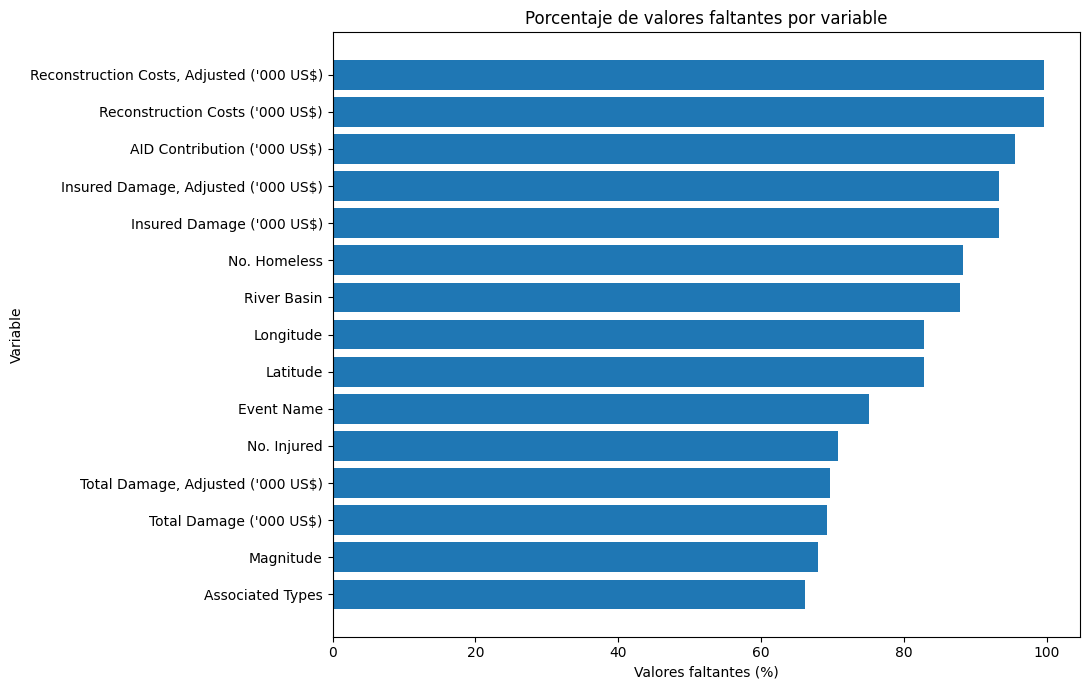

In [74]:
carpeta_graficas = Path("../resultados/graficas")
carpeta_graficas.mkdir(parents=True, exist_ok=True)

faltantes_grafica = (
    emdat_procesado.isna().mean()
    .mul(100)
    .sort_values(ascending=False)
    .head(15)
    .sort_values(ascending=True)
)

plt.figure(figsize=(11, 7))

plt.barh(
    faltantes_grafica.index,
    faltantes_grafica.values
)

plt.xlabel("Valores faltantes (%)")
plt.ylabel("Variable")
plt.title("Porcentaje de valores faltantes por variable")

plt.tight_layout()

plt.savefig(
    carpeta_graficas / "06_porcentaje_faltantes.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Análisis y tratamiento de valores faltantes

Se realizó un análisis de valores faltantes en el conjunto de datos integrado de desastres naturales, compuesto por 10,907 registros y 57 columnas. El análisis permitió identificar diferencias importantes en la disponibilidad de información entre las variables.

Las mayores proporciones de ausencia se encontraron en los costos de reconstrucción, las contribuciones de ayuda y los daños asegurados. Por otra parte, las variables relacionadas con fallecimientos, personas afectadas, daños económicos totales y coordenadas geográficas resultan relevantes para el análisis de impacto y la visualización de los eventos.

Como criterio de preprocesamiento, no se sustituyeron automáticamente los valores faltantes por cero, debido a que la ausencia de un dato no demuestra que el impacto correspondiente haya sido nulo. Se propone conservar los registros y evaluar la disponibilidad de cada variable de acuerdo con el análisis que se realizará. Para los gráficos estadísticos, se utilizarán los valores informados, indicando cuando corresponda que los resultados representan únicamente los registros con datos disponibles.

Las variables con una proporción muy elevada de valores faltantes serán evaluadas según su relevancia para los objetivos del proyecto. Cualquier exclusión o imputación deberá justificarse y documentarse, procurando evitar la pérdida innecesaria de información.

# Detectar valores extremos mediante IQR

IQR = Q3 - Q1

Qinferior = Q1 - 1.5(IQR)

Qsuperior = Q3 + 1.5(IQR)

Donde Q1 es el primer cuartil y Q3 el tercer cuartil. Los valores fuera de esos límites se marcan como posibles outliers.

In [75]:
# Crear carpeta para guardar resultados
carpeta_resultados = Path("../resultados")
carpeta_resultados.mkdir(parents=True, exist_ok=True)

# Variables que analizaremos
variables_iqr = [
    "Total Deaths",
    "Total Damage, Adjusted ('000 US$)"
]

resumen_iqr = []
candidatos_iqr = []

for variable in variables_iqr:

    # Convertir a valores numéricos y excluir los faltantes
    datos = pd.to_numeric(
        emdat_procesado[variable],
        errors="coerce"
    ).dropna()

    # Calcular cuartiles y rango intercuartílico
    q1 = datos.quantile(0.25)
    q3 = datos.quantile(0.75)
    iqr = q3 - q1

    limite_inferior = q1 - 1.5 * iqr
    limite_superior = q3 + 1.5 * iqr

    # Detectar posibles valores extremos
    mascara = (
        (emdat_procesado[variable] < limite_inferior) |
        (emdat_procesado[variable] > limite_superior)
    )

    mascara = mascara & emdat_procesado[variable].notna()
    extremos = emdat_procesado.loc[mascara].copy()

    resumen_iqr.append({
        "Variable": variable,
        "Datos_analizados": len(datos),
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "Limite_inferior": limite_inferior,
        "Limite_superior": limite_superior,
        "Candidatos_outliers": len(extremos)
    })

    # Guardar los eventos detectados con sus datos identificativos
    columnas_info = [
        c for c in [
            "DisNo.", "Country", "ISO",
            "Disaster Type", "Start Year"
        ]
        if c in extremos.columns
    ]

    detalle = extremos[columnas_info].copy()
    detalle["Variable_analizada"] = variable
    detalle["Valor"] = extremos[variable].values
    detalle["Limite_inferior"] = limite_inferior
    detalle["Limite_superior"] = limite_superior

    candidatos_iqr.append(detalle)

# Mostrar resumen
resumen_iqr = pd.DataFrame(resumen_iqr)
display(resumen_iqr.round(2))

# Guardar el resumen
resumen_iqr.to_csv(
    carpeta_resultados / "resumen_outliers_iqr.csv",
    index=False,
    encoding="utf-8-sig"
)

# Guardar los registros detectados
if candidatos_iqr:
    detalle_outliers = pd.concat(
        candidatos_iqr,
        ignore_index=True
    )

    detalle_outliers.to_csv(
        carpeta_resultados / "candidatos_outliers_iqr.csv",
        index=False,
        encoding="utf-8-sig"
    )

    print("Total de filas candidatas:", len(detalle_outliers))
    display(
        detalle_outliers.sort_values(
            "Valor", ascending=False
        ).head(15)
    )


,Variable,Datos_analizados,Q1,Q3,IQR,Limite_inferior,Limite_superior,Candidatos_outliers
0,Total Deaths,7835,4.0,36.0,32.0,-44.0,84.0,1027
1,"Total Damage, Adjusted ('000 US$)",3312,24357.0,804833.0,780476.0,-1146357.0,1975547.0,456


Total de filas candidatas: 1483


,DisNo.,Country,ISO,Disaster Type,Start Year,Variable_analizada,Valor,Limite_inferior,Limite_superior
1166,2011-0082-JPN,Japan,JPN,Earthquake,2011,"Total Damage, Adjusted ('000 US$)",300561348.0,-1146357.0,1975547.0
1414,2005-0467-USA,United States of America,USA,Storm,2005,"Total Damage, Adjusted ('000 US$)",206065474.0,-1146357.0,1975547.0
1423,2008-0192-CHN,China,CHN,Earthquake,2008,"Total Damage, Adjusted ('000 US$)",127100952.0,-1146357.0,1975547.0
1240,2017-0362-USA,United States of America,USA,Storm,2017,"Total Damage, Adjusted ('000 US$)",124774087.0,-1146357.0,1975547.0
1382,2022-0614-USA,United States of America,USA,Storm,2022,"Total Damage, Adjusted ('000 US$)",110007737.0,-1146357.0,1975547.0
1074,2017-0383-PRI,Puerto Rico,PRI,Storm,2017,"Total Damage, Adjusted ('000 US$)",89311978.0,-1146357.0,1975547.0
1132,2024-0693-USA,United States of America,USA,Storm,2024,"Total Damage, Adjusted ('000 US$)",82105029.0,-1146357.0,1975547.0
1256,2021-0551-USA,United States of America,USA,Storm,2021,"Total Damage, Adjusted ('000 US$)",77227433.0,-1146357.0,1975547.0
1472,2017-0381-USA,United States of America,USA,Storm,2017,"Total Damage, Adjusted ('000 US$)",74864452.0,-1146357.0,1975547.0
1031,2012-0410-USA,United States of America,USA,Storm,2012,"Total Damage, Adjusted ('000 US$)",70111391.0,-1146357.0,1975547.0


# Visualizar los valores extremos

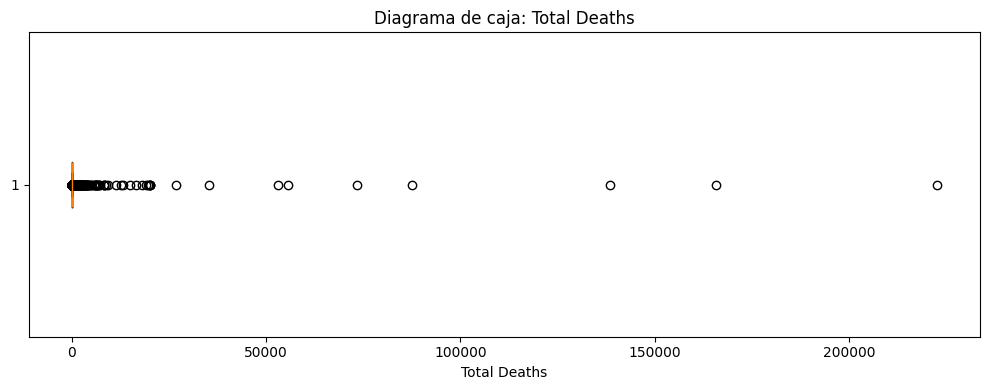

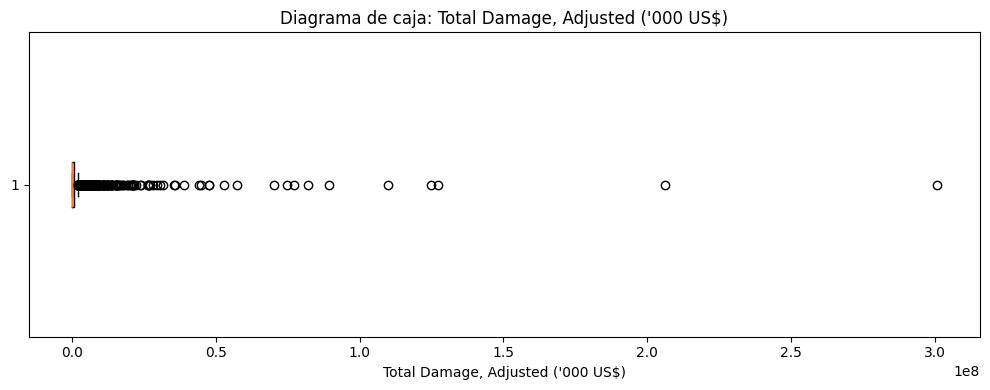

In [76]:
carpeta_graficas = Path("../resultados/graficas")
carpeta_graficas.mkdir(parents=True, exist_ok=True)

for variable in variables_iqr:

    datos = pd.to_numeric(
        emdat_procesado[variable],
        errors="coerce"
    ).dropna()

    plt.figure(figsize=(10, 4))
    plt.boxplot(datos, vert=False)

    plt.title(f"Diagrama de caja: {variable}")
    plt.xlabel(variable)
    plt.tight_layout()

    nombre = (
        variable.lower()
        .replace(" ", "_")
        .replace(",", "")
        .replace("(", "")
        .replace(")", "")
        .replace("'", "")
    )

    plt.savefig(
        carpeta_graficas / f"07_boxplot_{nombre}.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()


### Detección de valores extremos mediante el rango intercuartílico

Para identificar posibles valores extremos en las variables de fallecimientos y daños económicos ajustados, se empleó el método del rango intercuartílico (IQR). Esta técnica se basa en los cuartiles de la distribución y permite establecer límites estadísticos para identificar observaciones alejadas de la zona central de los datos.

El rango intercuartílico se calcula como la diferencia entre el tercer cuartil y el primer cuartil. Se consideran candidatos a valores extremos los registros inferiores a \(Q_1-1.5(IQR)\) o superiores a \(Q_3+1.5(IQR)\).

Los valores faltantes se excluyeron únicamente del cálculo de los cuartiles, sin eliminar sus registros del conjunto de datos. Asimismo, los candidatos identificados no se eliminaron automáticamente, puesto que los desastres naturales pueden producir impactos excepcionalmente elevados que sean reales. Por esta razón, el método se utilizó como herramienta de diagnóstico que permite orientar la revisión de los datos y no como criterio único para determinar errores.

In [77]:
resumen_iqr

,Variable,Datos_analizados,Q1,Q3,IQR,Limite_inferior,Limite_superior,Candidatos_outliers
0,Total Deaths,7835,4.0,36.0,32.0,-44.0,84.0,1027
1,"Total Damage, Adjusted ('000 US$)",3312,24357.0,804833.0,780476.0,-1146357.0,1975547.0,456


In [78]:

# Recalcular y mostrar los resultados en orden explícito

for variable in variables_iqr:
    datos = pd.to_numeric(
        emdat_procesado[variable],
        errors="coerce"
    ).dropna()

    q1 = datos.quantile(0.25)
    q3 = datos.quantile(0.75)
    iqr = q3 - q1

    limite_inferior = q1 - 1.5 * iqr
    limite_superior = q3 + 1.5 * iqr

    mascara = (
        (emdat_procesado[variable] < limite_inferior) |
        (emdat_procesado[variable] > limite_superior)
    ) & emdat_procesado[variable].notna()

    print(f"\nVariable: {variable}")
    print(f"Datos analizados: {len(datos)}")
    print(f"Q1: {q1:,.2f}")
    print(f"Q3: {q3:,.2f}")
    print(f"IQR: {iqr:,.2f}")
    print(f"Límite inferior: {limite_inferior:,.2f}")
    print(f"Límite superior: {limite_superior:,.2f}")
    print(f"Candidatos a outliers: {int(mascara.sum())}")



Variable: Total Deaths
Datos analizados: 7835
Q1: 4.00
Q3: 36.00
IQR: 32.00
Límite inferior: -44.00
Límite superior: 84.00
Candidatos a outliers: 1027

Variable: Total Damage, Adjusted ('000 US$)
Datos analizados: 3312
Q1: 24,357.00
Q3: 804,833.00
IQR: 780,476.00
Límite inferior: -1,146,357.00
Límite superior: 1,975,547.00
Candidatos a outliers: 456


In [79]:
# comprobar si hay valores negativos

for variable in variables_iqr:
    datos = pd.to_numeric(
        emdat_procesado[variable],
        errors="coerce"
    )

    negativos = emdat_procesado.loc[
        datos < 0,
        ["DisNo.", "Country", "Disaster Type", "Start Year", variable]
    ]

    print(f"\n{variable}: {len(negativos)} valores negativos")
    display(negativos.head(10))



Total Deaths: 0 valores negativos


,DisNo.,Country,Disaster Type,Start Year,Total Deaths



Total Damage, Adjusted ('000 US$): 0 valores negativos


,DisNo.,Country,Disaster Type,Start Year,"Total Damage, Adjusted ('000 US$)"


### Resultados de la detección de valores extremos

Se aplicó el método del rango intercuartílico (IQR) a las variables `Total Deaths` y `Total Damage, Adjusted ('000 US$)`. Para la primera variable se analizaron 7,835 registros disponibles y se identificaron 1,027 candidatos a valores extremos, utilizando un límite superior de 84 fallecimientos. Para los daños económicos ajustados se analizaron 3,312 registros y se identificaron 456 candidatos, con un límite superior de 1,975,547 miles de dólares estadounidenses.

Estos resultados representan observaciones que se encuentran alejadas de la distribución central según el criterio estadístico del IQR. Debido a que los desastres naturales pueden provocar pérdidas humanas y económicas extraordinarias, los registros identificados se conservaron para su revisión, sin eliminarlos automáticamente. La detección estadística se considera una etapa de diagnóstico y no una prueba suficiente de que los datos sean incorrectos.

# Etapa 5: fechas inconsistentes

In [80]:
df_fechas = emdat_procesado.copy()

# Convertir los componentes de fecha a números.
columnas_fecha = [
    "Start Year", "Start Month", "Start Day",
    "End Year", "End Month", "End Day"
]

for columna in columnas_fecha:
    df_fechas[columna] = pd.to_numeric(
        df_fechas[columna],
        errors="coerce"
    )

# Comprobar componentes fuera de los rangos permitidos.
mes_inicio_invalido = (
    df_fechas["Start Month"].notna()
    & ~df_fechas["Start Month"].between(1, 12)
)

mes_fin_invalido = (
    df_fechas["End Month"].notna()
    & ~df_fechas["End Month"].between(1, 12)
)

dia_inicio_invalido = (
    df_fechas["Start Day"].notna()
    & ~df_fechas["Start Day"].between(1, 31)
)

dia_fin_invalido = (
    df_fechas["End Day"].notna()
    & ~df_fechas["End Day"].between(1, 31)
)

# Comparar las fechas por componentes, de mayor a menor precisión.
# Solo se comparan componentes disponibles y válidos.
sy = df_fechas["Start Year"]
ey = df_fechas["End Year"]
sm = df_fechas["Start Month"]
em = df_fechas["End Month"]
sd = df_fechas["Start Day"]
ed = df_fechas["End Day"]

anios_comparables = sy.notna() & ey.notna()
inicio_despues = anios_comparables & (sy > ey)

mismos_anios = anios_comparables & (sy == ey)
meses_validos = (
    sm.between(1, 12) & em.between(1, 12)
)
meses_comparables = mismos_anios & meses_validos

inicio_despues |= (
    meses_comparables & (sm > em)
)

mismos_meses = meses_comparables & (sm == em)
dias_validos = (
    sd.between(1, 31) & ed.between(1, 31)
)
dias_comparables = mismos_meses & dias_validos

inicio_despues |= (
    dias_comparables & (sd > ed)
)

# Validar también si la combinación completa forma fechas reales.
fecha_inicio = pd.to_datetime(
    {
        "year": df_fechas["Start Year"],
        "month": df_fechas["Start Month"],
        "day": df_fechas["Start Day"]
    },
    errors="coerce"
)

fecha_fin = pd.to_datetime(
    {
        "year": df_fechas["End Year"],
        "month": df_fechas["End Month"],
        "day": df_fechas["End Day"]
    },
    errors="coerce"
)

fechas_completas_invertidas = (
    fecha_inicio.notna()
    & fecha_fin.notna()
    & (fecha_inicio > fecha_fin)
)

# Crear tabla de incidencias.
incidencias = pd.DataFrame({
    "Inicio_posterior_a_fin": inicio_despues,
    "Mes_inicio_invalido": mes_inicio_invalido,
    "Mes_fin_invalido": mes_fin_invalido,
    "Dia_inicio_fuera_de_rango": dia_inicio_invalido,
    "Dia_fin_fuera_de_rango": dia_fin_invalido,
    "Fecha_completa_invertida": fechas_completas_invertidas
}, index=df_fechas.index)

# Seleccionar los registros que tengan al menos una incidencia.
mascara_incidencias = incidencias.any(axis=1)

columnas_mostrar = [
    c for c in [
        "DisNo.", "Country", "Disaster Type",
        "Start Year", "Start Month", "Start Day",
        "End Year", "End Month", "End Day"
    ]
    if c in df_fechas.columns
]

revision_fechas = df_fechas.loc[
    mascara_incidencias, columnas_mostrar
].copy()

revision_fechas = revision_fechas.join(
    incidencias.loc[mascara_incidencias]
)

# Resumen por tipo de incidencia.
print("Registros con al menos una incidencia:",
      len(revision_fechas))

print("\nConteo por tipo de incidencia:")
display(incidencias.sum().rename("Cantidad").to_frame())

display(revision_fechas.head(20))

# Guardar los resultados.
carpeta_resultados = Path("../resultados")
carpeta_resultados.mkdir(parents=True, exist_ok=True)

revision_fechas.to_csv(
    carpeta_resultados / "revision_fechas_inconsistentes.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\nTabla guardada en resultados/revision_fechas_inconsistentes.csv")


Registros con al menos una incidencia: 3

Conteo por tipo de incidencia:


,Cantidad
Inicio_posterior_a_fin,3
Mes_inicio_invalido,0
Mes_fin_invalido,0
Dia_inicio_fuera_de_rango,0
Dia_fin_fuera_de_rango,0
Fecha_completa_invertida,3


,DisNo.,Country,Disaster Type,Start Year,Start Month,Start Day,End Year,End Month,End Day,Inicio_posterior_a_fin,Mes_inicio_invalido,Mes_fin_invalido,Dia_inicio_fuera_de_rango,Dia_fin_fuera_de_rango,Fecha_completa_invertida
7,1988-0424-VEN,Venezuela (Bolivarian Republic of),Storm,2026,9.0,11.0,1988,9.0,11.0,True,False,False,False,False,True
61,2026-0221-IDN,Indonesia,Earthquake,2026,4.0,2.0,2026,3.0,2.0,True,False,False,False,False,True
65,1995-0275-NPL,Nepal,Storm,2026,11.0,10.0,1995,11.0,11.0,True,False,False,False,False,True



Tabla guardada en resultados/revision_fechas_inconsistentes.csv


In [81]:
# Seleccionar los registros que presentan inconsistencias
columnas_revision = [
    "DisNo.",
    "Country",
    "Disaster Type",
    "Start Year",
    "Start Month",
    "Start Day",
    "End Year",
    "End Month",
    "End Day",
    "Inicio_posterior_a_fin",
    "Fecha_completa_invertida"
]

revision_fechas_final = revision_fechas[columnas_revision].copy()

# Guardar el archivo
revision_fechas_final.to_csv(
    "../resultados/revision_fechas_inconsistentes.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Registros que requieren revisión:", len(revision_fechas_final))

Registros que requieren revisión: 3


### Validación de consistencia de fechas

Se realizó una revisión de las fechas de inicio y finalización de los eventos registrados en el conjunto de datos EM-DAT. La validación consideró el orden cronológico de las fechas, la validez de los meses y los días, y la coherencia entre los componentes disponibles de las fechas.

De los 10,907 registros analizados, se identificaron **3 registros con inconsistencias temporales**, equivalentes aproximadamente al **0.0275 % del conjunto de datos**. Los tres presentaron fechas de inicio posteriores a las fechas de finalización. No se detectaron meses inválidos ni días fuera de los rangos numéricos establecidos por las validaciones aplicadas.

Los registros identificados se conservaron y se exportaron a un archivo independiente para su revisión. No se modificaron automáticamente sus fechas, debido a que cualquier corrección debe estar respaldada por la fuente original. Este procedimiento permite preservar la información disponible y evitar introducir cambios no verificados durante el preprocesamiento.

Como medida adicional, se recomienda revisar la coherencia entre los años de las fechas y el identificador de cada desastre, así como comprobar que las fechas completas correspondan a días válidos del calendario.

In [82]:
revision_fechas_final

,DisNo.,Country,Disaster Type,Start Year,Start Month,Start Day,End Year,End Month,End Day,Inicio_posterior_a_fin,Fecha_completa_invertida
7,1988-0424-VEN,Venezuela (Bolivarian Republic of),Storm,2026,9.0,11.0,1988,9.0,11.0,True,True
61,2026-0221-IDN,Indonesia,Earthquake,2026,4.0,2.0,2026,3.0,2.0,True,True
65,1995-0275-NPL,Nepal,Storm,2026,11.0,10.0,1995,11.0,11.0,True,True


In [83]:
columnas_revision = [
    "DisNo.",
    "Country",
    "Disaster Type",
    "Start Year",
    "Start Month",
    "Start Day",
    "End Year",
    "End Month",
    "End Day",
    "Inicio_posterior_a_fin",
    "Fecha_completa_invertida"
]

display(
    revision_fechas[columnas_revision]
    .reset_index(drop=True)
)

,DisNo.,Country,Disaster Type,Start Year,Start Month,Start Day,End Year,End Month,End Day,Inicio_posterior_a_fin,Fecha_completa_invertida
0,1988-0424-VEN,Venezuela (Bolivarian Republic of),Storm,2026,9.0,11.0,1988,9.0,11.0,True,True
1,2026-0221-IDN,Indonesia,Earthquake,2026,4.0,2.0,2026,3.0,2.0,True,True
2,1995-0275-NPL,Nepal,Storm,2026,11.0,10.0,1995,11.0,11.0,True,True


In [84]:
# Mostrar los nombres reales de las columnas
print(revision_fechas.columns.tolist())

# Mostrar el primer registro como diccionario
print(revision_fechas.iloc[0].to_dict())

# Mostrar la tabla sin formato HTML
print(revision_fechas[
    [
        "DisNo.", "Country", "Disaster Type",
        "Start Year", "Start Month", "Start Day",
        "End Year", "End Month", "End Day",
        "Inicio_posterior_a_fin",
        "Fecha_completa_invertida"
    ]
].to_string(index=False))

['DisNo.', 'Country', 'Disaster Type', 'Start Year', 'Start Month', 'Start Day', 'End Year', 'End Month', 'End Day', 'Inicio_posterior_a_fin', 'Mes_inicio_invalido', 'Mes_fin_invalido', 'Dia_inicio_fuera_de_rango', 'Dia_fin_fuera_de_rango', 'Fecha_completa_invertida']
{'DisNo.': '1988-0424-VEN', 'Country': 'Venezuela (Bolivarian Republic of)', 'Disaster Type': 'Storm', 'Start Year': 2026, 'Start Month': 9.0, 'Start Day': 11.0, 'End Year': 1988, 'End Month': 9.0, 'End Day': 11.0, 'Inicio_posterior_a_fin': True, 'Mes_inicio_invalido': False, 'Mes_fin_invalido': False, 'Dia_inicio_fuera_de_rango': False, 'Dia_fin_fuera_de_rango': False, 'Fecha_completa_invertida': True}
       DisNo.                            Country Disaster Type  Start Year  Start Month  Start Day  End Year  End Month  End Day  Inicio_posterior_a_fin  Fecha_completa_invertida
1988-0424-VEN Venezuela (Bolivarian Republic of)         Storm        2026          9.0       11.0      1988        9.0     11.0                 

# Paso 6. mejorar la validación de fechas

In [85]:
# Extraer el año del identificador del desastre
anio_id = pd.to_numeric(
    emdat_procesado["DisNo."].astype("string").str[:4],
    errors="coerce"
)

# Convertir el año de inicio a numérico
anio_inicio = pd.to_numeric(
    emdat_procesado["Start Year"],
    errors="coerce"
)

# Identificar diferencias entre ambos años
diferencia_anios = (
    anio_id.notna()
    & anio_inicio.notna()
    & (anio_id != anio_inicio)
)

revision_anios = emdat_procesado.loc[
    diferencia_anios,
    ["DisNo.", "Country", "Disaster Type", "Start Year"]
].copy()

revision_anios["Anio_identificador"] = anio_id.loc[
    diferencia_anios
]

print("Registros con diferencia entre años:",
      len(revision_anios))

display(revision_anios.head(20))

Registros con diferencia entre años: 54


,DisNo.,Country,Disaster Type,Start Year,Anio_identificador
4,2024-0962-AGO,Angola,Epidemic,2025,2024
7,1988-0424-VEN,Venezuela (Bolivarian Republic of),Storm,2026,1988
65,1995-0275-NPL,Nepal,Storm,2026,1995
358,1999-9388-DJI,Djibouti,Drought,2001,1999
770,2018-9277-CRI,Costa Rica,Drought,2019,2018
1492,2014-9580-SLV,El Salvador,Drought,2015,2014
1518,2014-0530-MWI,Malawi,Epidemic,2015,2014
1524,2014-0529-BOL,Bolivia (Plurinational State of),Flood,2015,2014
1640,2025-0075-AUS,Australia,Flood,2024,2025
1737,2025-0593-LAO,Lao People's Democratic Republic,Storm,2024,2025


In [86]:
# Crear una copia de los registros que requieren revisión
revision_anios.to_csv(
    "../resultados/revision_diferencias_anios.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Registros guardados:", len(revision_anios))
print("Archivo: revision_diferencias_anios.csv")


Registros guardados: 54
Archivo: revision_diferencias_anios.csv


### Validación de consistencia entre el identificador y el año de inicio

Se comparó el año incluido en el identificador del desastre (`DisNo.`) con la variable `Start Year`. Se identificaron 54 registros con diferencias entre ambos valores, los cuales requieren una revisión adicional.

Estas diferencias se consideraron posibles inconsistencias y no errores confirmados, debido a que la información disponible no permite determinar por sí sola cuál de los dos años es correcto. Se conservaron los registros originales y se generó un archivo independiente para documentar los casos identificados.

Se priorizará la revisión de los registros que presentan simultáneamente discrepancias entre años y fechas de inicio posteriores a las fechas de finalización. No se aplicaron correcciones automáticas, con el propósito de preservar la integridad de los datos y evitar introducir modificaciones sin respaldo documental.

# Consolidar las inconsistencias temporales

In [87]:
import pandas as pd
from pathlib import Path

# 1. Trabajar sobre una copia del conjunto integrado
df_validacion = emdat_procesado.copy()

# 2. Comparar el año de DisNo. con Start Year
anio_id = pd.to_numeric(
    df_validacion["DisNo."].astype("string").str[:4],
    errors="coerce"
)
anio_inicio = pd.to_numeric(
    df_validacion["Start Year"],
    errors="coerce"
)

df_validacion["Diferencia_anio_identificador"] = (
    anio_id.notna()
    & anio_inicio.notna()
    & anio_id.ne(anio_inicio)
)

# 3. Detectar fechas de calendario imposibles
def detectar_fecha_invalida(df, prefijo):
    anio = pd.to_numeric(df[f"{prefijo} Year"], errors="coerce")
    mes = pd.to_numeric(df[f"{prefijo} Month"], errors="coerce")
    dia = pd.to_numeric(df[f"{prefijo} Day"], errors="coerce")

    # Solo validar fechas que tienen los tres componentes
    completa = anio.notna() & mes.notna() & dia.notna()

    fecha = pd.to_datetime(
        {"year": anio, "month": mes, "day": dia},
        errors="coerce"
    )

    return completa & fecha.isna()

df_validacion["Fecha_inicio_calendario_invalida"] = (
    detectar_fecha_invalida(df_validacion, "Start")
)
df_validacion["Fecha_fin_calendario_invalida"] = (
    detectar_fecha_invalida(df_validacion, "End")
)

# 4. Recuperar las alertas cronológicas existentes
# Si las columnas existen, se conservan; si no, se inicializan en False.
for columna in [
    "Inicio_posterior_a_fin",
    "Fecha_completa_invertida"
]:
    if columna not in df_validacion.columns:
        df_validacion[columna] = False
    else:
        df_validacion[columna] = (
            df_validacion[columna].fillna(False).astype(bool)
        )

# 5. Crear una bandera general: al menos una incidencia temporal
columnas_alerta = [
    "Diferencia_anio_identificador",
    "Fecha_inicio_calendario_invalida",
    "Fecha_fin_calendario_invalida",
    "Inicio_posterior_a_fin",
    "Fecha_completa_invertida"
]

df_validacion["Requiere_revision_temporal"] = (
    df_validacion[columnas_alerta].any(axis=1)
)

# 6. Generar el listado de registros que requieren revisión
revision_temporal_final = df_validacion.loc[
    df_validacion["Requiere_revision_temporal"],
    [
        "DisNo.", "Country", "Disaster Type",
        "Start Year", "Start Month", "Start Day",
        "End Year", "End Month", "End Day"
    ] + columnas_alerta
].copy()

# 7. Resumen de calidad temporal
resumen_temporal = pd.DataFrame({
    "Tipo_incidencia": columnas_alerta,
    "Cantidad": [
        int(df_validacion[col].sum())
        for col in columnas_alerta
    ]
})

print("Total de registros:", len(df_validacion))
print(
    "Registros únicos con alguna incidencia temporal:",
    int(df_validacion["Requiere_revision_temporal"].sum())
)
print("\nIncidencias por tipo:")
display(resumen_temporal)

print("\nPrimeros registros para revisar:")
display(revision_temporal_final.head(10))

# 8. Guardar resultados
carpeta = Path("../resultados")
carpeta.mkdir(parents=True, exist_ok=True)

revision_temporal_final.to_csv(
    carpeta / "revision_temporal_consolidada.csv",
    index=False,
    encoding="utf-8-sig"
)

resumen_temporal.to_csv(
    carpeta / "resumen_validacion_temporal.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\nArchivos guardados en:", carpeta.resolve())

Total de registros: 10907
Registros únicos con alguna incidencia temporal: 54

Incidencias por tipo:


,Tipo_incidencia,Cantidad
0,Diferencia_anio_identificador,54
1,Fecha_inicio_calendario_invalida,0
2,Fecha_fin_calendario_invalida,0
3,Inicio_posterior_a_fin,0
4,Fecha_completa_invertida,0



Primeros registros para revisar:


,DisNo.,Country,Disaster Type,Start Year,Start Month,Start Day,End Year,End Month,End Day,Diferencia_anio_identificador,Fecha_inicio_calendario_invalida,Fecha_fin_calendario_invalida,Inicio_posterior_a_fin,Fecha_completa_invertida
4,2024-0962-AGO,Angola,Epidemic,2025,1.0,7.0,2025,10.0,NaN,True,False,False,False,False
7,1988-0424-VEN,Venezuela (Bolivarian Republic of),Storm,2026,9.0,11.0,1988,9.0,11.0,True,False,False,False,False
65,1995-0275-NPL,Nepal,Storm,2026,11.0,10.0,1995,11.0,11.0,True,False,False,False,False
358,1999-9388-DJI,Djibouti,Drought,2001,6.0,NaN,2001,NaN,NaN,True,False,False,False,False
770,2018-9277-CRI,Costa Rica,Drought,2019,3.0,NaN,2019,3.0,NaN,True,False,False,False,False
1492,2014-9580-SLV,El Salvador,Drought,2015,4.0,NaN,2016,12.0,NaN,True,False,False,False,False
1518,2014-0530-MWI,Malawi,Epidemic,2015,2.0,NaN,2015,6.0,NaN,True,False,False,False,False
1524,2014-0529-BOL,Bolivia (Plurinational State of),Flood,2015,1.0,15.0,2015,1.0,31.0,True,False,False,False,False
1640,2025-0075-AUS,Australia,Flood,2024,2.0,29.0,2025,2.0,5.0,True,False,False,False,False
1737,2025-0593-LAO,Lao People's Democratic Republic,Storm,2024,7.0,19.0,2024,7.0,20.0,True,False,False,False,False



Archivos guardados en: C:\Users\itzel\PROYECTO_DESASTRES\resultados


# recalcular correctamente las incidencias

In [88]:
df_validacion = emdat_procesado.copy()

# Convertir los componentes de las fechas a números enteros anulables
campos_fecha = [
    "Start Year", "Start Month", "Start Day",
    "End Year", "End Month", "End Day"
]

for columna in campos_fecha:
    df_validacion[columna] = pd.to_numeric(
        df_validacion[columna], errors="coerce"
    )

# Extraer el año del identificador
anio_id = pd.to_numeric(
    df_validacion["DisNo."].astype("string").str[:4],
    errors="coerce"
)

# Comparar año del identificador y año de inicio
df_validacion["Diferencia_anio_identificador"] = (
    anio_id.notna()
    & df_validacion["Start Year"].notna()
    & anio_id.ne(df_validacion["Start Year"])
)

# Función para construir fechas completas sin modificar los datos originales
def construir_fecha(df, prefijo):
    anio = df[f"{prefijo} Year"].astype("Int64").astype("string")
    mes = df[f"{prefijo} Month"].astype("Int64").astype("string")
    dia = df[f"{prefijo} Day"].astype("Int64").astype("string")

    completa = anio.notna() & mes.notna() & dia.notna()
    texto_fecha = anio + "-" + mes.str.zfill(2) + "-" + dia.str.zfill(2)

    fecha = pd.to_datetime(texto_fecha, errors="coerce")
    return fecha, completa

fecha_inicio, inicio_completo = construir_fecha(df_validacion, "Start")
fecha_fin, fin_completo = construir_fecha(df_validacion, "End")

# Detectar fechas completas imposibles, por ejemplo, 31 de febrero
df_validacion["Fecha_inicio_calendario_invalida"] = (
    inicio_completo & fecha_inicio.isna()
)
df_validacion["Fecha_fin_calendario_invalida"] = (
    fin_completo & fecha_fin.isna()
)

# Detectar inicio posterior al fin solo cuando ambas fechas son válidas y completas
inicio_fin_comparables = (
    inicio_completo & fin_completo
    & fecha_inicio.notna() & fecha_fin.notna()
)

df_validacion["Fecha_completa_invertida"] = (
    inicio_fin_comparables & (fecha_inicio > fecha_fin)
)

# Comparación por componentes para fechas incompletas.
# Solo se compara un componente cuando los anteriores son iguales
# y ambos valores están disponibles.
sy = df_validacion["Start Year"]
sm = df_validacion["Start Month"]
sd = df_validacion["Start Day"]
ey = df_validacion["End Year"]
em = df_validacion["End Month"]
ed = df_validacion["End Day"]

mismo_anio = sy.notna() & ey.notna() & sy.eq(ey)
mismo_mes = mismo_anio & sm.notna() & em.notna() & sm.eq(em)

inicio_posterior = (
    (sy.notna() & ey.notna() & sy.gt(ey))
    | (mismo_anio & sm.notna() & em.notna() & sm.gt(em))
    | (mismo_mes & sd.notna() & ed.notna() & sd.gt(ed))
)

df_validacion["Inicio_posterior_a_fin"] = inicio_posterior

# Consolidar las banderas
columnas_alerta = [
    "Diferencia_anio_identificador",
    "Fecha_inicio_calendario_invalida",
    "Fecha_fin_calendario_invalida",
    "Inicio_posterior_a_fin",
    "Fecha_completa_invertida"
]

df_validacion["Requiere_revision_temporal"] = (
    df_validacion[columnas_alerta].any(axis=1)
)

# Resumen por tipo de incidencia
resumen_temporal = pd.DataFrame({
    "Tipo_incidencia": columnas_alerta,
    "Cantidad": [
        int(df_validacion[c].sum()) for c in columnas_alerta
    ]
})

# Registros únicos con alguna incidencia
revision_temporal_final = df_validacion.loc[
    df_validacion["Requiere_revision_temporal"],
    [
        "DisNo.", "Country", "Disaster Type",
        "Start Year", "Start Month", "Start Day",
        "End Year", "End Month", "End Day"
    ] + columnas_alerta
].copy()

print("Total de registros:", len(df_validacion))
print(
    "Registros únicos con alguna incidencia:",
    len(revision_temporal_final)
)
display(resumen_temporal)
display(revision_temporal_final.head(10))

# Guardar los resultados actualizados
carpeta = Path("../resultados")
carpeta.mkdir(parents=True, exist_ok=True)

revision_temporal_final.to_csv(
    carpeta / "revision_temporal_consolidada.csv",
    index=False, encoding="utf-8-sig"
)

resumen_temporal.to_csv(
    carpeta / "resumen_validacion_temporal.csv",
    index=False, encoding="utf-8-sig"
)

Total de registros: 10907
Registros únicos con alguna incidencia: 55


,Tipo_incidencia,Cantidad
0,Diferencia_anio_identificador,54
1,Fecha_inicio_calendario_invalida,0
2,Fecha_fin_calendario_invalida,0
3,Inicio_posterior_a_fin,3
4,Fecha_completa_invertida,3


,DisNo.,Country,Disaster Type,Start Year,Start Month,Start Day,End Year,End Month,End Day,Diferencia_anio_identificador,Fecha_inicio_calendario_invalida,Fecha_fin_calendario_invalida,Inicio_posterior_a_fin,Fecha_completa_invertida
4,2024-0962-AGO,Angola,Epidemic,2025,1.0,7.0,2025,10.0,NaN,True,False,False,False,False
7,1988-0424-VEN,Venezuela (Bolivarian Republic of),Storm,2026,9.0,11.0,1988,9.0,11.0,True,False,False,True,True
61,2026-0221-IDN,Indonesia,Earthquake,2026,4.0,2.0,2026,3.0,2.0,False,False,False,True,True
65,1995-0275-NPL,Nepal,Storm,2026,11.0,10.0,1995,11.0,11.0,True,False,False,True,True
358,1999-9388-DJI,Djibouti,Drought,2001,6.0,NaN,2001,NaN,NaN,True,False,False,False,False
770,2018-9277-CRI,Costa Rica,Drought,2019,3.0,NaN,2019,3.0,NaN,True,False,False,False,False
1492,2014-9580-SLV,El Salvador,Drought,2015,4.0,NaN,2016,12.0,NaN,True,False,False,False,False
1518,2014-0530-MWI,Malawi,Epidemic,2015,2.0,NaN,2015,6.0,NaN,True,False,False,False,False
1524,2014-0529-BOL,Bolivia (Plurinational State of),Flood,2015,1.0,15.0,2015,1.0,31.0,True,False,False,False,False
1640,2025-0075-AUS,Australia,Flood,2024,2.0,29.0,2025,2.0,5.0,True,False,False,False,False


In [89]:
# Normalizar las banderas para que solo contengan True o False
for columna in columnas_alerta:
    df_validacion[columna] = (
        df_validacion[columna]
        .fillna(False)
        .astype(bool)
    )

# Recalcular la bandera general de revisión
df_validacion["Requiere_revision_temporal"] = (
    df_validacion[columnas_alerta].any(axis=1)
)

# Generar el resumen definitivo
resumen_temporal = pd.DataFrame({
    "Tipo_incidencia": columnas_alerta,
    "Cantidad": [
        int(df_validacion[columna].sum())
        for columna in columnas_alerta
    ]
})

revision_temporal_final = df_validacion.loc[
    df_validacion["Requiere_revision_temporal"],
    [
        "DisNo.", "Country", "Disaster Type",
        "Start Year", "Start Month", "Start Day",
        "End Year", "End Month", "End Day"
    ] + columnas_alerta
].copy()

print("Total de registros:", len(df_validacion))
print(
    "Registros con alguna incidencia:",
    len(revision_temporal_final)
)
print(
    "Banderas con valores nulos:",
    int(df_validacion[columnas_alerta].isna().sum().sum())
)

display(resumen_temporal)
display(revision_temporal_final)

# Guardar resultados
carpeta = Path("../resultados")
carpeta.mkdir(parents=True, exist_ok=True)

revision_temporal_final.to_csv(
    carpeta / "revision_temporal_consolidada.csv",
    index=False,
    encoding="utf-8-sig"
)

resumen_temporal.to_csv(
    carpeta / "resumen_validacion_temporal.csv",
    index=False,
    encoding="utf-8-sig"
)


Total de registros: 10907
Registros con alguna incidencia: 55
Banderas con valores nulos: 0


,Tipo_incidencia,Cantidad
0,Diferencia_anio_identificador,54
1,Fecha_inicio_calendario_invalida,0
2,Fecha_fin_calendario_invalida,0
3,Inicio_posterior_a_fin,3
4,Fecha_completa_invertida,3


,DisNo.,Country,Disaster Type,Start Year,Start Month,Start Day,End Year,End Month,End Day,Diferencia_anio_identificador,Fecha_inicio_calendario_invalida,Fecha_fin_calendario_invalida,Inicio_posterior_a_fin,Fecha_completa_invertida
4,2024-0962-AGO,Angola,Epidemic,2025,1.0,7.0,2025,10.0,NaN,True,False,False,False,False
7,1988-0424-VEN,Venezuela (Bolivarian Republic of),Storm,2026,9.0,11.0,1988,9.0,11.0,True,False,False,True,True
61,2026-0221-IDN,Indonesia,Earthquake,2026,4.0,2.0,2026,3.0,2.0,False,False,False,True,True
65,1995-0275-NPL,Nepal,Storm,2026,11.0,10.0,1995,11.0,11.0,True,False,False,True,True
358,1999-9388-DJI,Djibouti,Drought,2001,6.0,NaN,2001,NaN,NaN,True,False,False,False,False
770,2018-9277-CRI,Costa Rica,Drought,2019,3.0,NaN,2019,3.0,NaN,True,False,False,False,False
1492,2014-9580-SLV,El Salvador,Drought,2015,4.0,NaN,2016,12.0,NaN,True,False,False,False,False
1518,2014-0530-MWI,Malawi,Epidemic,2015,2.0,NaN,2015,6.0,NaN,True,False,False,False,False
1524,2014-0529-BOL,Bolivia (Plurinational State of),Flood,2015,1.0,15.0,2015,1.0,31.0,True,False,False,False,False
1640,2025-0075-AUS,Australia,Flood,2024,2.0,29.0,2025,2.0,5.0,True,False,False,False,False


### Validación de consistencia temporal

Se realizó una validación de consistencia temporal sobre los 10,907 registros del conjunto de datos. Se comparó el año incluido en el identificador del desastre (`DisNo.`) con la variable `Start Year`, además de revisar la validez de las fechas completas y el orden cronológico entre las fechas de inicio y finalización.

Se identificaron 54 registros con discrepancias entre el año del identificador y el año de inicio. Asimismo, se detectaron tres registros en los que la fecha inicial era posterior a la fecha final. No se identificaron fechas completas con combinaciones de día, mes y año inválidas.

Las incidencias cronológicas se conservaron para su revisión, sin aplicar correcciones automáticas, debido a que es necesario contrastarlas con la fuente original. Las discrepancias entre el identificador y el año de inicio se trataron como alertas de consistencia y no como errores confirmados. Esta estrategia evita introducir modificaciones no verificadas y mantiene la trazabilidad del proceso de limpieza.

En total, se identificaron 55 registros únicos con al menos una incidencia temporal. La cantidad corresponde a registros afectados, no a la suma de todas las categorías de alerta, ya que algunas incidencias pueden presentarse simultáneamente.

# auditoría de integridad del conjunto

In [90]:
from pathlib import Path
import pandas as pd

# 1. Auditar el conjunto procesado
print("=== CONJUNTO PROCESADO ===")
print("Filas:", len(emdat_procesado))
print("Columnas:", len(emdat_procesado.columns))

if "DisNo." in emdat_procesado.columns:
    print(
        "Identificadores DisNo. duplicados:",
        emdat_procesado["DisNo."].duplicated().sum()
    )
    print(
        "Identificadores DisNo. vacíos:",
        emdat_procesado["DisNo."].isna().sum()
    )

print(
    "Filas esperadas conservadas:",
    len(emdat_procesado) == 10907
)

# 2. Revisar que la unión geográfica no haya multiplicado filas
if "ISO_union" in emdat_procesado.columns:
    print(
        "Registros con coincidencia geográfica:",
        emdat_procesado["Coincidencia_geografica"].sum()
        if "Coincidencia_geografica" in emdat_procesado.columns
        else "No hay bandera geográfica"
    )

=== CONJUNTO PROCESADO ===
Filas: 10907
Columnas: 57
Identificadores DisNo. duplicados: 0
Identificadores DisNo. vacíos: 0
Filas esperadas conservadas: True
Registros con coincidencia geográfica: 10588


In [91]:
# Cargar el archivo integrado
ruta = Path("../datos/procesados/EMDAT_integrado_WDI.csv")
df_integrado = pd.read_csv(ruta, low_memory=False)

# Verificar que se cargó correctamente
print("Filas:", df_integrado.shape[0])
print("Columnas:", df_integrado.shape[1])
print("\nPrimeros registros:")
display(df_integrado.head())


Filas: 10907
Columnas: 69

Primeros registros:


,DisNo.,Historic,Classification Key,Disaster Group,Disaster Subgroup,Disaster Type,Disaster Subtype,External IDs,Event Name,ISO,...,ISO_union,Nombre_WDI,PIB_USD_corrientes,PIB_disponible,Diferencia_anio_identificador,Fecha_inicio_calendario_invalida,Fecha_fin_calendario_invalida,Fecha_completa_invertida,Inicio_posterior_a_fin,Requiere_revision_temporal
0,2025-0303-ECU,No,nat-geo-ear-gro,Natural,Geophysical,Earthquake,Ground movement,NaN,NaN,ECU,...,ECU,Ecuador,1.303206e+11,True,False,False,False,False,False,False
1,2026-0153-KEN,No,nat-hyd-flo-flo,Natural,Hydrological,Flood,Flood (General),NaN,NaN,KEN,...,KEN,NaN,NaN,False,False,False,False,False,False,False
2,2025-0750-AFG,No,nat-geo-ear-gro,Natural,Geophysical,Earthquake,Ground movement,GLIDE:EQ-2025-000153,NaN,AFG,...,AFG,Afghanistan,NaN,False,False,False,False,False,False,False
3,2026-0305-AFG,No,nat-hyd-flo-flo,Natural,Hydrological,Flood,Flood (General),NaN,NaN,AFG,...,AFG,NaN,NaN,False,False,False,False,False,False,False
4,2024-0962-AGO,No,nat-bio-epi-bac,Natural,Biological,Epidemic,Bacterial disease,GLIDE:EP-2025-000013,Cholera,AGO,...,AGO,Angola,1.221749e+11,True,True,False,False,False,False,True


# Actualizar las validaciones temporales

In [92]:
# Crear una copia para trabajar sin modificar el DataFrame original
df_validacion = df_integrado.copy()

# Convertir los campos temporales a valores numéricos
campos_fecha = [
    "Start Year", "Start Month", "Start Day",
    "End Year", "End Month", "End Day"
]

for columna in campos_fecha:
    df_validacion[columna] = pd.to_numeric(
        df_validacion[columna], errors="coerce"
    )

# Extraer el año del identificador DisNo.
anio_id = pd.to_numeric(
    df_validacion["DisNo."].astype("string").str[:4],
    errors="coerce"
)

# Detectar diferencias entre el año del identificador y Start Year
df_validacion["Diferencia_anio_identificador"] = (
    anio_id.notna()
    & df_validacion["Start Year"].notna()
    & anio_id.ne(df_validacion["Start Year"])
)

# Construir fechas completas para validar el calendario
def construir_fecha(df, prefijo):
    anio = df[f"{prefijo} Year"].astype("Int64").astype("string")
    mes = df[f"{prefijo} Month"].astype("Int64").astype("string")
    dia = df[f"{prefijo} Day"].astype("Int64").astype("string")

    completa = anio.notna() & mes.notna() & dia.notna()
    texto_fecha = anio + "-" + mes.str.zfill(2) + "-" + dia.str.zfill(2)
    fecha = pd.to_datetime(texto_fecha, errors="coerce")

    return fecha, completa

fecha_inicio, inicio_completo = construir_fecha(df_validacion, "Start")
fecha_fin, fin_completo = construir_fecha(df_validacion, "End")

# Detectar fechas completas que no existen en el calendario
df_validacion["Fecha_inicio_calendario_invalida"] = (
    inicio_completo & fecha_inicio.isna()
)

df_validacion["Fecha_fin_calendario_invalida"] = (
    fin_completo & fecha_fin.isna()
)

# Detectar casos donde el inicio ocurre después del final
fechas_comparables = (
    inicio_completo
    & fin_completo
    & fecha_inicio.notna()
    & fecha_fin.notna()
)

df_validacion["Fecha_completa_invertida"] = (
    fechas_comparables & (fecha_inicio > fecha_fin)
)

# Validar el orden temporal usando los componentes disponibles
sy = df_validacion["Start Year"]
sm = df_validacion["Start Month"]
sd = df_validacion["Start Day"]

ey = df_validacion["End Year"]
em = df_validacion["End Month"]
ed = df_validacion["End Day"]

mismo_anio = sy.notna() & ey.notna() & sy.eq(ey)
mismo_mes = mismo_anio & sm.notna() & em.notna() & sm.eq(em)

df_validacion["Inicio_posterior_a_fin"] = (
    (sy.notna() & ey.notna() & sy.gt(ey))
    | (mismo_anio & sm.notna() & em.notna() & sm.gt(em))
    | (mismo_mes & sd.notna() & ed.notna() & sd.gt(ed))
)

# Consolidar las banderas de revisión
columnas_alerta = [
    "Diferencia_anio_identificador",
    "Fecha_inicio_calendario_invalida",
    "Fecha_fin_calendario_invalida",
    "Inicio_posterior_a_fin",
    "Fecha_completa_invertida"
]

for columna in columnas_alerta:
    df_validacion[columna] = (
        df_validacion[columna].fillna(False).astype(bool)
    )

df_validacion["Requiere_revision_temporal"] = (
    df_validacion[columnas_alerta].any(axis=1)
)

# Resumen de resultados
print("Total de registros:", len(df_validacion))
print(
    "Registros con alguna incidencia temporal:",
    df_validacion["Requiere_revision_temporal"].sum()
)

print("\nIncidencias por categoría:")
display(df_validacion[columnas_alerta].sum().to_frame("Cantidad"))


Total de registros: 10907
Registros con alguna incidencia temporal: 55

Incidencias por categoría:


,Cantidad
Diferencia_anio_identificador,54
Fecha_inicio_calendario_invalida,0
Fecha_fin_calendario_invalida,0
Inicio_posterior_a_fin,3
Fecha_completa_invertida,3


In [93]:
# 1. Guardar el conjunto integrado con las validaciones actualizadas.
#    Lo dejo en la carpeta del proyecto y con los montos en pesos
#    mexicanos, que es la moneda con la que trabaja la aplicación.
import sys

RAIZ_PROYECTO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(RAIZ_PROYECTO) not in sys.path:
    sys.path.insert(0, str(RAIZ_PROYECTO))

from src.config import TIPO_CAMBIO_MXN
from src.moneda import convertir

ruta_salida = Path("../datos/procesados/EMDAT_integrado_WDI_validado.csv")

# 2. Convierto las columnas monetarias de USD a MXN antes de guardar.
df_validado_mxn = convertir(df_validacion, TIPO_CAMBIO_MXN)

df_validado_mxn.to_csv(
    ruta_salida,
    index=False,
    encoding="utf-8-sig"
)

print("Archivo guardado en:", ruta_salida.resolve())
print(f"Montos en pesos mexicanos (1 USD = {TIPO_CAMBIO_MXN} MXN)")


Archivo guardado en: C:\Users\itzel\PROYECTO_DESASTRES\datos\procesados\EMDAT_integrado_WDI_validado.csv
Montos en pesos mexicanos (1 USD = 20.8 MXN)


# Preparar los archivos finales

In [94]:
# Crear las carpetas de salida
carpeta_datos = Path("../datos/procesados")
carpeta_tablas = Path("../resultados/tablas")
carpeta_graficas = Path("../resultados/graficas")

for carpeta in [carpeta_datos, carpeta_tablas, carpeta_graficas]:
    carpeta.mkdir(parents=True, exist_ok=True)

# Actualizar las banderas temporales del conjunto integrado
df_final = df_validacion.copy()

df_final["Fecha_inicio_completa"] = (
    df_final[["Start Year", "Start Month", "Start Day"]]
    .notna().all(axis=1)
)

df_final["Fecha_fin_completa"] = (
    df_final[["End Year", "End Month", "End Day"]]
    .notna().all(axis=1)
)

df_final["Fecha_inicio_posterior_fin"] = (
    df_final["Inicio_posterior_a_fin"]
)

df_final["Anio_ID"] = pd.to_numeric(
    df_final["DisNo."].astype("string").str[:4],
    errors="coerce"
)

df_final["Anio_ID_distinto_Start_Year"] = (
    df_final["Diferencia_anio_identificador"]
)

df_final["Revision_fecha_requerida"] = (
    df_final["Requiere_revision_temporal"]
)

# Exportar el conjunto final integrado
df_final.to_csv(
    carpeta_datos / "EMDAT_integrado_WDI.csv",
    index=False,
    encoding="utf-8-sig"
)

# Exportar registros con incidencias temporales
df_final.loc[
    df_final["Requiere_revision_temporal"]
].to_csv(
    carpeta_tablas / "revision_fechas.csv",
    index=False,
    encoding="utf-8-sig"
)

# Tabla de valores faltantes
faltantes = pd.DataFrame({
    "Variable": df_final.columns,
    "Valores_faltantes": df_final.isna().sum().values,
    "Porcentaje_faltante": (
        df_final.isna().mean().values * 100
    ).round(2)
})

faltantes = faltantes.sort_values(
    "Porcentaje_faltante", ascending=False
)

faltantes.to_csv(
    carpeta_tablas / "valores_faltantes.csv",
    index=False,
    encoding="utf-8-sig"
)

# Resumen anual
df_final["Start Year"] = pd.to_numeric(
    df_final["Start Year"], errors="coerce"
)

resumen_anual = df_final.groupby(
    "Start Year", dropna=True
).agg(
    Eventos=("DisNo.", "count"),
    Fallecimientos_reportados=("Total Deaths", "sum"),
    Eventos_con_fallecimientos=("Total Deaths", "count")
).reset_index()

resumen_anual.to_csv(
    carpeta_datos / "resumen_anual.csv",
    index=False,
    encoding="utf-8-sig"
)

# Resumen por tipo de desastre
resumen_tipo = df_final.groupby(
    "Disaster Type", dropna=False
).agg(
    Eventos=("DisNo.", "count"),
    Fallecimientos_reportados=("Total Deaths", "sum")
).reset_index().sort_values("Eventos", ascending=False)

resumen_tipo.to_csv(
    carpeta_datos / "resumen_por_tipo.csv",
    index=False,
    encoding="utf-8-sig"
)

# Resumen de integración geográfica
if "Coincidencia_geografica" in df_final.columns:
    resumen_geo = (
        df_final["Coincidencia_geografica"]
        .value_counts(dropna=False)
        .rename_axis("Coincidencia_geografica")
        .reset_index(name="Registros")
    )

    resumen_geo["Porcentaje"] = (
        resumen_geo["Registros"] / len(df_final) * 100
    ).round(2)

    resumen_geo.to_csv(
        carpeta_tablas / "resumen_integracion_geografica.csv",
        index=False,
        encoding="utf-8-sig"
    )

# Gráfica 1: eventos por año
anual_grafica = resumen_anual.dropna(subset=["Start Year"])

plt.figure(figsize=(11, 5))
plt.plot(
    anual_grafica["Start Year"],
    anual_grafica["Eventos"],
    marker="o"
)
plt.title("Eventos de desastre registrados por año")
plt.xlabel("Año de inicio")
plt.ylabel("Número de eventos")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(
    carpeta_graficas / "01_eventos_por_anio.png",
    dpi=200
)
plt.close()

# Gráfica 2: eventos por tipo de desastre
tipo_grafica = resumen_tipo.dropna(subset=["Disaster Type"])

plt.figure(figsize=(11, 6))
plt.barh(
    tipo_grafica["Disaster Type"][::-1],
    tipo_grafica["Eventos"][::-1]
)
plt.title("Eventos registrados por tipo de desastre")
plt.xlabel("Número de eventos")
plt.ylabel("Tipo de desastre")
plt.tight_layout()
plt.savefig(
    carpeta_graficas / "02_eventos_por_tipo.png",
    dpi=200
)
plt.close()

# Gráfica 3: fallecimientos reportados por año
plt.figure(figsize=(11, 5))
plt.plot(
    anual_grafica["Start Year"],
    anual_grafica["Fallecimientos_reportados"],
    marker="o"
)
plt.title("Fallecimientos reportados por año")
plt.xlabel("Año de inicio")
plt.ylabel("Fallecimientos reportados")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(
    carpeta_graficas / "03_fallecimientos_por_anio.png",
    dpi=200
)
plt.close()

# Gráfica 4: porcentaje de valores faltantes
faltantes_grafica = faltantes[
    faltantes["Porcentaje_faltante"] > 0
].head(15).sort_values("Porcentaje_faltante")

plt.figure(figsize=(10, 6))
plt.barh(
    faltantes_grafica["Variable"],
    faltantes_grafica["Porcentaje_faltante"]
)
plt.title("Variables con mayor porcentaje de datos faltantes")
plt.xlabel("Valores faltantes (%)")
plt.ylabel("Variable")
plt.tight_layout()
plt.savefig(
    carpeta_graficas / "05_valores_faltantes.png",
    dpi=200
)
plt.close()

# Resumen de control final
print("PROCESO TERMINADO")
print("Filas:", len(df_final))
print("Columnas:", len(df_final.columns))
print("Identificadores duplicados:", df_final["DisNo."].duplicated().sum())
print(
    "Incidencias temporales:",
    df_final["Revision_fecha_requerida"].sum()
)
print("\nArchivos guardados en:")
print("-", carpeta_datos.resolve())
print("-", carpeta_tablas.resolve())
print("-", carpeta_graficas.resolve())


PROCESO TERMINADO
Filas: 10907
Columnas: 69
Identificadores duplicados: 0
Incidencias temporales: 55

Archivos guardados en:
- C:\Users\itzel\PROYECTO_DESASTRES\datos\procesados
- C:\Users\itzel\PROYECTO_DESASTRES\resultados\tablas
- C:\Users\itzel\PROYECTO_DESASTRES\resultados\graficas


In [95]:

# Filtrar los desastres correspondientes a México
df_mexico = df_final[
    df_final["ISO"].astype("string").str.strip().str.upper() == "MEX"
].copy()

print("Registros de México:", len(df_mexico))
print("Columnas:", len(df_mexico.columns))
print("\nEventos por tipo de desastre:")
display(
    df_mexico["Disaster Type"]
    .value_counts(dropna=False)
    .rename_axis("Tipo de desastre")
    .reset_index(name="Cantidad")
)

# Guardar el subconjunto sin modificar el conjunto global
ruta_mexico = carpeta_datos / "EMDAT_Mexico_procesado.csv"

df_mexico.to_csv(
    ruta_mexico,
    index=False,
    encoding="utf-8-sig"
)

print("\nArchivo guardado en:", ruta_mexico.resolve())


Registros de México: 171
Columnas: 69

Eventos por tipo de desastre:


,Tipo de desastre,Cantidad
0,Storm,84
1,Flood,50
2,Earthquake,15
3,Mass movement (wet),8
4,Extreme temperature,7
5,Wildfire,2
6,Volcanic activity,2
7,Drought,2
8,Epidemic,1



Archivo guardado en: C:\Users\itzel\PROYECTO_DESASTRES\datos\procesados\EMDAT_Mexico_procesado.csv


# DataSet México

In [96]:
ruta = "../datos/originales/public_emdat_custom_request_2026_Mexico.xlsx"

df_mexico = pd.read_excel(ruta)

df_mexico.head()

,DisNo.,Historic,Classification Key,Disaster Group,Disaster Subgroup,Disaster Type,Disaster Subtype,External IDs,Event Name,ISO,...,"Reconstruction Costs, Adjusted ('000 US$)",Insured Damage ('000 US$),"Insured Damage, Adjusted ('000 US$)",Total Damage ('000 US$),"Total Damage, Adjusted ('000 US$)",CPI,Admin Units,GADM Admin Units,Entry Date,Last Update
0,2026-0001-MEX,No,nat-geo-ear-gro,Natural,Geophysical,Earthquake,Ground movement,USGS:us7000rm3k,NaN,MEX,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2026-01-05,2026-07-27
1,2026-0383-MEX,No,nat-met-sto-tro,Natural,Meteorological,Storm,Tropical cyclone,NaN,Tropical storm 'Boris',MEX,...,NaN,NaN,NaN,100000.0,NaN,NaN,NaN,NaN,2026-06-12,2026-07-27
2,2024-0422-MEX,No,nat-met-sto-tro,Natural,Meteorological,Storm,Tropical cyclone,GLIDE:TC-2024-000105,Hurricane 'Beryl',MEX,...,NaN,NaN,NaN,90000.0,92368.0,97.436176,NaN,NaN,2026-08-19,2026-08-19
3,2000-0643-MEX,No,nat-met-sto-tro,Natural,Meteorological,Storm,Tropical cyclone,NaN,Hurricane 'Keith',MEX,...,NaN,NaN,NaN,1000.0,1870.0,53.487737,"[{""adm1_code"":2031,""adm1_name"":""Campeche""},{""a...","[{""gid_1"":""MEX.20_1"",""migration_date"":""2025-12...",2005-12-16,2026-08-19
4,2000-0611-MEX,No,nat-met-sto-sev,Natural,Meteorological,Storm,Severe weather,NaN,Tropical storm 'Norman',MEX,...,NaN,NaN,NaN,18800.0,35148.0,53.487737,"[{""adm1_code"":2032,""adm1_name"":""Chiapas""},{""ad...","[{""gid_1"":""MEX.12_1"",""migration_date"":""2025-12...",2003-07-01,2026-08-20


In [97]:
ruta_mexico = "../datos/originales/public_emdat_custom_request_2026_Mexico.xlsx"
ruta_global = "../datos/procesados/EMDAT_integrado_WDI.csv"
salida = Path("../datos/procesados")
tablas = Path("../resultados/tablas")
salida.mkdir(parents=True, exist_ok=True)
tablas.mkdir(parents=True, exist_ok=True)

# 2. Cargar los datos
mex = pd.read_excel(ruta_mexico, sheet_name="EM-DAT Data")
global_df = pd.read_csv(ruta_global, low_memory=False)

filas_mex_originales = len(mex)
filas_global_originales = len(global_df)

# 3. Limpieza de texto e identificadores
for df in [mex, global_df]:
    df.columns = df.columns.str.strip()
    for col in df.select_dtypes(include="object").columns:
        df[col] = df[col].map(
            lambda x: x.strip() if isinstance(x, str) else x
        )
        df[col] = df[col].replace("", pd.NA)

mex["DisNo."] = mex["DisNo."].astype("string").str.strip()
global_df["DisNo."] = global_df["DisNo."].astype("string").str.strip()

# Conservar solo registros de México en el archivo nuevo
mex = mex[mex["ISO"].eq("MEX")].copy()

# 4. Depuración: identificar y retirar duplicados
ids_vacios = mex["DisNo."].isna().sum()
duplicados = mex["DisNo."].duplicated().sum()
duplicados_globales = global_df["DisNo."].duplicated().sum()

mex = mex.dropna(subset=["DisNo."])
mex = mex.drop_duplicates(subset=["DisNo."], keep="last")

# Conversión de variables numéricas
numericas = [
    "Start Year", "Start Month", "Start Day",
    "End Year", "End Month", "End Day",
    "Total Deaths", "No. Injured", "No. Affected",
    "No. Homeless", "Total Affected",
    "Latitude", "Longitude", "Magnitude",
    "CPI", "AID Contribution ('000 US$)",
    "Total Damage ('000 US$)",
    "Total Damage, Adjusted ('000 US$)"
]
for col in numericas:
    if col in mex.columns:
        mex[col] = pd.to_numeric(mex[col], errors="coerce")

# 5. Integración por identificador único DisNo.
# Alinear columnas para conservar PIB y datos geográficos.
for col in global_df.columns:
    if col not in mex.columns:
        mex[col] = pd.NA

mex = mex[global_df.columns]
global_df = global_df.drop_duplicates(subset=["DisNo."], keep="first")

base = global_df.set_index("DisNo.")
nuevos = mex[~mex["DisNo."].isin(base.index)].copy()
coincidentes = mex[mex["DisNo."].isin(base.index)].copy()

# Actualizar coincidencias solo cuando el nuevo dato no esté vacío.
actualizaciones = 0
for _, fila in coincidentes.iterrows():
    id_evento = fila["DisNo."]
    for col in mex.columns:
        if col == "DisNo.":
            continue
        nuevo = fila[col]
        anterior = base.at[id_evento, col]
        if pd.notna(nuevo) and (
            pd.isna(anterior) or str(nuevo) != str(anterior)
        ):
            base.at[id_evento, col] = nuevo
            actualizaciones += 1

# Incorporar eventos nuevos, si los hubiera
base_final = base.reset_index()
if not nuevos.empty:
    base_final = pd.concat([base_final, nuevos], ignore_index=True)

# 6. Validación final
base_final = base_final.drop_duplicates(subset=["DisNo."], keep="first")
mex_final = base_final[base_final["ISO"].eq("MEX")].copy()

resumen = pd.DataFrame({
    "Indicador": [
        "Filas del archivo mexicano original",
        "Filas de la base global original",
        "Registros mexicanos procesados",
        "Registros coincidentes por DisNo.",
        "Nuevos eventos incorporados",
        "Valores actualizados con datos no vacíos",
        "Identificadores vacíos en archivo mexicano",
        "Duplicados DisNo. en archivo mexicano",
        "Duplicados DisNo. en base global original",
        "Filas finales de la base integrada",
        "Duplicados DisNo. en resultado final"
    ],
    "Valor": [
        filas_mex_originales,
        filas_global_originales,
        len(mex),
        len(coincidentes),
        len(nuevos),
        actualizaciones,
        ids_vacios,
        duplicados,
        duplicados_globales,
        len(base_final),
        base_final["DisNo."].duplicated().sum()
    ]
})

faltantes = (
    mex.isna().sum().rename("Valores faltantes")
    .to_frame()
    .assign(Porcentaje=lambda x: (x["Valores faltantes"] / len(mex) * 100).round(2))
    .sort_values("Porcentaje", ascending=False)
)

# 7. Guardar los resultados
base_final.to_csv(
    salida / "EMDAT_integrado_WDI_Mexico_actualizado.csv",
    index=False, encoding="utf-8-sig"
)
mex.to_csv(
    salida / "EMDAT_Mexico_limpio.csv",
    index=False, encoding="utf-8-sig"
)
resumen.to_csv(
    tablas / "resumen_integracion_mexico.csv",
    index=False, encoding="utf-8-sig"
)
faltantes.to_csv(
    tablas / "faltantes_dataset_mexico.csv",
    encoding="utf-8-sig"
)

print("INTEGRACIÓN TERMINADA")
display(resumen)
print("Eventos por tipo:")
display(mex_final["Disaster Type"].value_counts().to_frame("Cantidad"))
print("Archivos guardados en:", salida.resolve())
print("Tablas de validación guardadas en:", tablas.resolve())


INTEGRACIÓN TERMINADA


,Indicador,Valor
0,Filas del archivo mexicano original,171
1,Filas de la base global original,10907
2,Registros mexicanos procesados,171
3,Registros coincidentes por DisNo.,171
4,Nuevos eventos incorporados,0
5,Valores actualizados con datos no vacíos,182
6,Identificadores vacíos en archivo mexicano,0
7,Duplicados DisNo. en archivo mexicano,0
8,Duplicados DisNo. en base global original,0
9,Filas finales de la base integrada,10907


Eventos por tipo:


,Cantidad
Disaster Type,
Storm,84
Flood,50
Earthquake,15
Mass movement (wet),8
Extreme temperature,7
Wildfire,2
Volcanic activity,2
Drought,2
Epidemic,1


Archivos guardados en: C:\Users\itzel\PROYECTO_DESASTRES\datos\procesados
Tablas de validación guardadas en: C:\Users\itzel\PROYECTO_DESASTRES\resultados\tablas


---

# Etapa 6: codificación, escalado y balanceo

Ya tengo el conjunto limpio y validado. Antes de cerrar la actividad reviso los tres pasos de preparación que todavía no había documentado: **codificación** de las variables de texto, **escalado** de las variables de impacto y **balanceo** de las clases.

También verifico que los indicadores socioeconómicos que agregué (PIB, población y superficie) salgan de la misma fuente que el archivo integrado que usa la aplicación.

## Paso 1: validar la integración socioeconómica

Los datos del Banco Mundial los integro con el módulo `src.integracion_paises.py`, para no repetir la descarga dentro del notebook. Aquí compruebo que la tabla resultante tenga los países y las unidades que espero.

In [98]:
# Reviso la tabla socioeconómica que alimenta la aplicación.
import sys
from pathlib import Path

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))

from src.integracion_paises import construir_tabla, TIPO_CAMBIO_MXN

tabla_paises = construir_tabla()

# Muestro las economías que más peso tienen en el conjunto.
paises_clave = ["MEX", "USA", "BRA", "ARG", "IND"]
resumen_socio = tabla_paises.loc[
    [c for c in paises_clave if c in tabla_paises.index],
    ["poblacion", "superficie_km2", "pib_mxn", "pib_pc_mxn", "densidad", "anio_socio"],
].copy()
resumen_socio.columns = [
    "Población", "Superficie km²", "PIB MXN",
    "PIB per cápita MXN", "Densidad hab/km²", "Año",
]
display(resumen_socio)

print("Países con PIB:", int(tabla_paises["pib_mxn"].notna().sum()))
print("Países con población:", int(tabla_paises["poblacion"].notna().sum()))
print("Países con superficie:", int(tabla_paises["superficie_km2"].notna().sum()))
print(f"Tipo de cambio usado: 1 USD = {TIPO_CAMBIO_MXN} MXN")

,Población,Superficie km²,PIB MXN,PIB per cápita MXN,Densidad hab/km²,Año
codigo,,,,,,
MEX,1.308610e+08,1957193.9,3.807418e+13,290951.0,66.9,2024.0
USA,3.400038e+08,9831510.0,6.093987e+14,1792329.0,34.6,2024.0
BRA,2.119986e+08,8510420.0,4.546509e+13,214459.0,24.9,2024.0
ARG,4.569616e+07,2780400.0,1.327800e+13,290572.0,16.4,2024.0
IND,1.450936e+09,3287263.0,7.822492e+13,53913.0,441.4,2024.0


Países con PIB: 264
Países con población: 267
Países con superficie: 262
Tipo de cambio usado: 1 USD = 20.8 MXN


In [99]:
# Comparo el PIB de México del archivo integrado con el que calcula el módulo.
mex_mismo_anio = df_validado_mxn[
    df_validado_mxn["ISO"].astype("string").str.upper().eq("MEX")
    & df_validado_mxn["Start Year"].eq(2024)
]["PIB_MXN_corrientes"].dropna()

pib_archivo = mex_mismo_anio.iloc[0] if len(mex_mismo_anio) else None
pib_modulo = tabla_paises.loc["MEX", "pib_mxn"]

print("PIB MXN de México en el archivo (2024):",
      f"{pib_archivo:,.0f}" if pib_archivo is not None else "sin dato")
print("PIB MXN de México en la tabla WDI:", f"{pib_modulo:,.0f}")
print("El PIB se guarda en pesos desde el pipeline, no en el navegador.")

PIB MXN de México en el archivo (2024): 38,074,177,670,649
PIB MXN de México en la tabla WDI: 38,074,177,670,649
El PIB se guarda en pesos desde el pipeline, no en el navegador.


## Paso 2: codificar las variables categóricas

Los modelos y las visualizaciones necesitan números, no texto. Codifico el tipo de desastre con un entero estable (orden alfabético) y conservo el catálogo para poder regresar a la etiqueta original en cualquier momento. El nombre en español se toma del diccionario del proyecto.

In [100]:
# Codifico el tipo de desastre y guardo el catálogo con su nombre en español.
from src.diccionario_desastres import traducir_serie

tipos = df_final["Disaster Type"].astype("string").str.strip()

catalogo_tipos = pd.DataFrame({"tipo_en": sorted(tipos.dropna().unique())})
catalogo_tipos["codigo"] = range(len(catalogo_tipos))
catalogo_tipos["tipo_es"] = traducir_serie(catalogo_tipos["tipo_en"])

mapa_tipos = dict(zip(catalogo_tipos["tipo_en"], catalogo_tipos["codigo"]))
df_final["Tipo_codigo"] = tipos.map(mapa_tipos).astype("Int64")

catalogo_tipos.to_csv(
    carpeta_tablas / "catalogo_tipos_desastre.csv",
    index=False,
    encoding="utf-8-sig",
)

display(catalogo_tipos)
print("Tipos codificados:", len(catalogo_tipos))
print("Eventos sin código:", int(df_final["Tipo_codigo"].isna().sum()))


,tipo_en,codigo,tipo_es
0,Animal incident,0,Incidente con animales
1,Drought,1,Sequía
2,Earthquake,2,Terremoto
3,Epidemic,3,Epidemia
4,Extreme temperature,4,Temperatura extrema
5,Flood,5,Inundación
6,Glacial lake outburst flood,6,Ruptura de lago glacial
7,Impact,7,Impacto
8,Infestation,8,Infestación
9,Mass movement (dry),9,Deslizamiento (seco)


Tipos codificados: 14
Eventos sin código: 0


In [101]:
# El grupo solo tiene una categoría, así que el one-hot confirma
# que el conjunto no mezcla desastres tecnológicos.
print("Valores de Disaster Group:")
display(df_final["Disaster Group"].value_counts(dropna=False))

dummies_grupo = pd.get_dummies(
    df_final["Disaster Group"], prefix="Grupo", dtype=int
)

print("Columnas generadas:", list(dummies_grupo.columns))
print("Cada evento queda en un solo grupo:",
      bool((dummies_grupo.sum(axis=1) <= 1).all()))


Valores de Disaster Group:


Disaster Group
Natural    10907
Name: count, dtype: int64

Columnas generadas: ['Grupo_Natural']
Cada evento queda en un solo grupo: True


## Paso 3: escalar las variables de impacto

Las tres variables de impacto (fallecidos, afectados y daño económico) tienen escalas muy distintas: un evento puede tener 2 fallecidos y otro 2 millones de afectados. Para poder compararlas en el mapa aplico dos transformaciones:

- **Min-max**: lleva cada variable al rango 0–1.
- **Logarítmica**: reduce el peso de los valores extremos, que son frecuentes en desastres.

In [102]:
# Escalo las variables de impacto con min-max y con logaritmo.
import numpy as np

variables_impacto = [
    "Total Deaths",
    "Total Affected",
    "Total Damage, Adjusted ('000 MXN)",
]

escalado = pd.DataFrame(index=df_validado_mxn.index)

for variable in variables_impacto:
    serie = pd.to_numeric(df_validado_mxn[variable], errors="coerce").clip(lower=0)
    minimo, maximo = serie.min(), serie.max()

    escalado[f"{variable} | min-max"] = (
        (serie - minimo) / (maximo - minimo) if maximo > minimo else 0.0
    )
    escalado[f"{variable} | log"] = (
        np.log1p(serie) / np.log1p(maximo) if maximo > 0 else 0.0
    )

resumen_escalado = escalado.describe().T[["min", "50%", "max"]].round(3)
display(resumen_escalado)

,min,50%,max
Total Deaths | min-max,0.000,0.000,1.0
Total Deaths | log,0.056,0.208,1.0
Total Affected | min-max,0.000,0.000,1.0
Total Affected | log,0.035,0.438,1.0
"Total Damage, Adjusted ('000 MXN) | min-max",0.000,0.001,1.0
"Total Damage, Adjusted ('000 MXN) | log",0.184,0.664,1.0


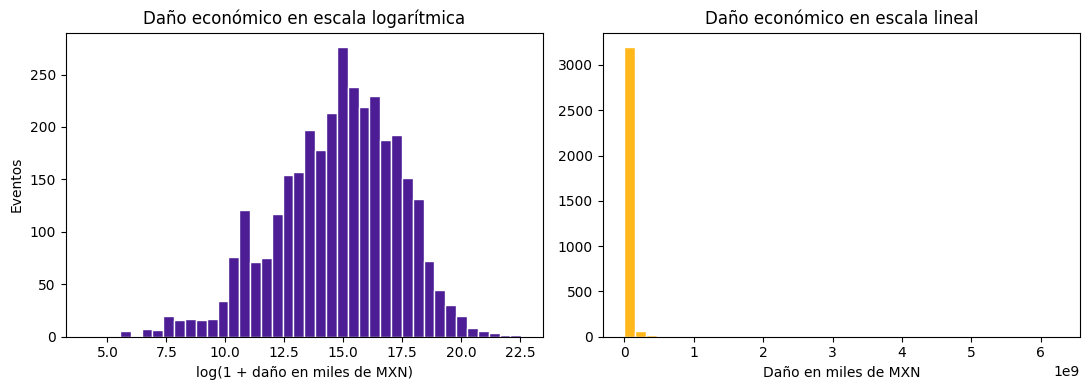

Eventos con daño económico: 3312
Mediana: 3,205,914 miles de MXN
Máximo:  6,251,676,038 miles de MXN


In [103]:
# Comparo visualmente la escala lineal contra la logarítmica en el daño económico.
import matplotlib.pyplot as plt

variable = "Total Damage, Adjusted ('000 MXN)"
datos = pd.to_numeric(df_validado_mxn[variable], errors="coerce").dropna()
datos = datos[datos > 0]

fig, ejes = plt.subplots(1, 2, figsize=(11, 4))

ejes[0].hist(np.log1p(datos), bins=40, color="#4C1D95", edgecolor="white")
ejes[0].set_title("Daño económico en escala logarítmica")
ejes[0].set_xlabel("log(1 + daño en miles de MXN)")
ejes[0].set_ylabel("Eventos")

ejes[1].hist(datos, bins=40, color="#FFB71B", edgecolor="white")
ejes[1].set_title("Daño económico en escala lineal")
ejes[1].set_xlabel("Daño en miles de MXN")

plt.tight_layout()
plt.savefig(
    carpeta_graficas / "actividad1_escalado_dano.png",
    dpi=140,
    bbox_inches="tight",
)
plt.show()

print("Eventos con daño económico:", len(datos))
print(f"Mediana: {datos.median():,.0f} miles de MXN")
print(f"Máximo:  {datos.max():,.0f} miles de MXN")

## Paso 4: revisar el balanceo de clases

El balanceo se aplica cuando se entrena un modelo de clasificación. Este proyecto es **descriptivo**: el atlas no predice el tipo de desastre, solo lo representa. Aun así, reviso el desbalance para dejarlo documentado y para saber qué precauciones tomar si más adelante se usara un modelo.

In [104]:
# Reviso cuántos eventos hay por tipo de desastre.
conteo_tipos = (
    df_final["Disaster Type"]
    .value_counts()
    .rename_axis("Tipo de desastre")
    .reset_index(name="Eventos")
)
conteo_tipos["Porcentaje"] = (
    conteo_tipos["Eventos"] / conteo_tipos["Eventos"].sum() * 100
).round(1)

display(conteo_tipos)

mayoritaria = conteo_tipos.iloc[0]
minoritaria = conteo_tipos.iloc[-1]
razon = mayoritaria["Eventos"] / minoritaria["Eventos"]

print(f"Clase mayoritaria: {mayoritaria['Tipo de desastre']} "
      f"({mayoritaria['Eventos']} eventos)")
print(f"Clase minoritaria: {minoritaria['Tipo de desastre']} "
      f"({minoritaria['Eventos']} eventos)")
print(f"Razón de desbalance: {razon:.1f} a 1")

,Tipo de desastre,Eventos,Porcentaje
0,Flood,4294,39.4
1,Storm,2930,26.9
2,Epidemic,895,8.2
3,Earthquake,707,6.5
4,Extreme temperature,606,5.6
5,Mass movement (wet),505,4.6
6,Drought,426,3.9
7,Wildfire,356,3.3
8,Volcanic activity,134,1.2
9,Infestation,29,0.3


Clase mayoritaria: Flood (4294 eventos)
Clase minoritaria: Animal incident (1 eventos)
Razón de desbalance: 4294.0 a 1


In [105]:
# Dimensiono tres escenarios de balanceo para justificar la decisión.
objetivo_minoria = int(conteo_tipos["Eventos"].min())
objetivo_mediana = int(conteo_tipos["Eventos"].median())
objetivo_mayoria = int(conteo_tipos["Eventos"].max())

escenarios = pd.DataFrame({
    "Escenario": [
        "Igualar a la clase minoritaria",
        "Igualar a la mediana",
        "Igualar a la clase mayoritaria",
    ],
    "Eventos por clase": [objetivo_minoria, objetivo_mediana, objetivo_mayoria],
})
escenarios["Eventos totales"] = escenarios["Eventos por clase"] * len(conteo_tipos)
escenarios["Cambio respecto al original"] = (
    escenarios["Eventos totales"] - len(df_final)
)

display(escenarios)

print("Decisión: no aplico balanceo. El atlas describe todos los eventos")
print("registrados y descartar clases minoritarias distorsionaría el mapa.")
print("Si se entrenara un modelo, convendría usar pesos por clase en lugar")
print("de eliminar registros.")


,Escenario,Eventos por clase,Eventos totales,Cambio respecto al original
0,Igualar a la clase minoritaria,1,14,-10893
1,Igualar a la mediana,391,5474,-5433
2,Igualar a la clase mayoritaria,4294,60116,49209


Decisión: no aplico balanceo. El atlas describe todos los eventos
registrados y descartar clases minoritarias distorsionaría el mapa.
Si se entrenara un modelo, convendría usar pesos por clase en lugar
de eliminar registros.
